## This notebook goes from cellranger ouptut of lung mets scRNA-seq data, to cell assignment, to MILO/MAST analysis

This is the 'master' notebook that shows how all lung_met analysis was done.

However, a few steps were done outside the notebook; this notebook will point you to the scripts/commands to run them.

In particular, cellAssign, scDblFinder, and MILO were run in separate docker containers with specific software installed.

All docker containers are available on dockerhub:

```
docker1 pull biohpc/scrna2024:0.3    # for docker container used for this notebook
docker1 pull biohpc/scrna-gpu:0.0.1  # for cellAssign; requires a GPU
docker1 pull biohpc/scDblFinder:0.1  # for scDblFinder
docker1 pull biohpc/milo:0.1         # for MILO
```

In addition, the UMAP coordinates could not be reproduced 100% from the original values used in the paper, likely due to random number seed differences, or perhaps software versions changed. We include the original results and code to load them in, and demonstrate that there is no meaningful difference between the two sets of UMAPs.

Some other results are also included in this repository and loaded by this notebook, because they are computationally intensive. But there are instructions to run the code which should reproduce the results exactly.



Prerequisite: cellranger should be run on all fastq files for each sample. We used cellranger-8.0.1

The command we used:
```
cellranger count --sample=$SAMPLE --id=$SAMPLE --create-bam=true --localcores=20 \
  --localmem=128 --disable-ui --transcriptome=refdata-gex-mm10-2020-A \
  --fastqs=FASTQ_DIR
```

The `--create-bam=true` option could be omitted, we did not use the bam files.

In [1]:
import glob
import itertools
import os
import random
import sys
import warnings
from importlib.metadata import version
from pathlib import Path

import h5py
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.cluster.hierarchy as hc
import scrublet as scr
import seaborn as sns
import textalloc as ta
from scipy import stats
from scipy.sparse import coo_matrix, csr_matrix
from sklearn.manifold import trustworthiness


In [2]:
sys.path.append('../SatSeq_10x_Variant_Calling/python')
import scrna_processing as scrpr

In [3]:
print(f"Python: {sys.version.split()[0]}")

packages = [
    "h5py",
    "matplotlib",
    "numpy",
    "pandas",
    "scanpy",
    "scipy",
    "scrublet",
    "seaborn",
    "textalloc",
    "scikit-learn",
]

for package in packages:
    print(f"{package}: {version(package)}")

Python: 3.10.12
h5py: 3.10.0
matplotlib: 3.8.3
numpy: 1.26.4
pandas: 2.2.1
scanpy: 1.9.8
scipy: 1.12.0
scrublet: 0.2.3
seaborn: 0.13.2
textalloc: 1.1.8
scikit-learn: 1.4.1.post1


In [4]:
# Point this directory to location of cellranger output
cellranger_out_dir='/workdir/satseq/matt_cbsulaughney/10x/lung_mets'

In [5]:
samples=[x+'_'+str(i+1) for x,i in itertools.product(['K337', 'P13', 'REF', 'STOP'], range(2))]
samples

['K337_1', 'K337_2', 'P13_1', 'P13_2', 'REF_1', 'REF_2', 'STOP_1', 'STOP_2']

In [6]:
adatas = [sc.read_10x_h5(cellranger_out_dir + '/' + s + '/outs/raw_feature_bc_matrix.h5', gex_only=False) for s in samples]

/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1908: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1908: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1908: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1908: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1908: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_name

/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1908: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1908: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1908: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1908: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1908: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [7]:
for i,s in enumerate(samples):
    adatas[i].obs['sample'] = s
    adatas[i].obs['sample'] = adatas[i].obs['sample'].astype(str)
    adatas[i].obs.index = [f"{x.split('-')[0]}-{s}" for x in adatas[i].obs.index]
    adatas

In [8]:
for i,s in enumerate(samples):
    readData = h5py.File(cellranger_out_dir + '/' + s + '/outs/molecule_info.h5', 'r')
    read_matrix = csr_matrix((readData['count'], (readData['barcode_idx'], readData['feature_idx'])), shape=adatas[i].shape)

    #gene_ids should be unique
    gene_ids = adatas[i].var.gene_ids
    geneTable = gene_ids.value_counts()
    print(f"Num unique gene IDs: {sum(geneTable==1)}\nNum non-unique gene IDs: {sum(geneTable > 1)}")
    if sum(geneTable > 1) > 0:
        print("ERROR: Gene IDs not unique")
    gene_names = adatas[i].var.index
    geneTable = gene_names.value_counts()
    print(f"Num unique gene names: {sum(geneTable==1)}\nNum non-unique gene names: {sum(geneTable > 1)}")
    if sum(geneTable > 1) > 0:
        tdata = adatas[i].copy().T
        dupGenes = geneTable[geneTable > 1].index
        #print(f"Duplicated gene [indices]")
        removeGenes = np.zeros(len(gene_names), bool)
        for dupGene in dupGenes:
            idx = [i for i in range(len(gene_names)) if gene_names[i] == dupGene] 
            #print(dupGene,idx)
            for j in range(len(idx)):
                if (j != 0):
                    tdata.X[idx[0],:] += tdata.X[idx[j],:]
                    read_matrix[:,idx[0]] += read_matrix[:,idx[j]]
                    removeGenes[idx[j]] = True
        tdata = tdata[~removeGenes]
        adatas[i] = tdata.copy().T
        read_matrix = read_matrix[:,~removeGenes]
        print(f"Combined {len(dupGenes)} genes; removed {sum(removeGenes)} columns")
    adatas[i].layers['read_matrix'] = read_matrix

Num unique gene IDs: 32285
Num non-unique gene IDs: 0
Num unique gene names: 32207
Num non-unique gene names: 38


/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1908: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1906: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/usr/local/lib/python3.10/dist-packages/scipy/sparse/_index.py:136: SparseEfficiencyWarning: Changing the sparsity structure of a csc_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray_sparse(i, j, x)
/usr/local/lib/python3.10/dist-packages/scipy/sparse/_index.py:136: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray_sparse(i, j, x)


Combined 38 genes; removed 40 columns
Num unique gene IDs: 32285
Num non-unique gene IDs: 0
Num unique gene names: 32207
Num non-unique gene names: 38


/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1908: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1906: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/usr/local/lib/python3.10/dist-packages/scipy/sparse/_index.py:136: SparseEfficiencyWarning: Changing the sparsity structure of a csc_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray_sparse(i, j, x)
/usr/local/lib/python3.10/dist-packages/scipy/sparse/_index.py:136: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray_sparse(i, j, x)


Combined 38 genes; removed 40 columns
Num unique gene IDs: 32285
Num non-unique gene IDs: 0
Num unique gene names: 32207
Num non-unique gene names: 38


/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1908: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1906: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/usr/local/lib/python3.10/dist-packages/scipy/sparse/_index.py:136: SparseEfficiencyWarning: Changing the sparsity structure of a csc_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray_sparse(i, j, x)
/usr/local/lib/python3.10/dist-packages/scipy/sparse/_index.py:136: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray_sparse(i, j, x)


... (14 outputs left out)

/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1908: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1906: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


/usr/local/lib/python3.10/dist-packages/scipy/sparse/_index.py:136: SparseEfficiencyWarning: Changing the sparsity structure of a csc_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray_sparse(i, j, x)


/usr/local/lib/python3.10/dist-packages/scipy/sparse/_index.py:136: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray_sparse(i, j, x)


Combined 38 genes; removed 40 columns


In [9]:
# calculate mtFrac and library_size first
for i,adata in enumerate(adatas):
    msum = np.array(adata.X.sum(axis=1)).flatten()
    mt_genes = [x for x in adata.var.index if x.startswith('mt')]
    mt = np.array(adata[:,mt_genes].X.sum(axis=1)).flatten()
    f = msum == 0
    adatas[i].obs['library_size'] = msum
    adatas[i].obs['mt_frac'] = 0.0
    adatas[i].obs.loc[adatas[i].obs['library_size'] > 0,'mt_frac'] = mt[~f]/msum[~f]

In [10]:
mt_genes

['mt-Nd1',
 'mt-Nd2',
 'mt-Co1',
 'mt-Co2',
 'mt-Atp8',
 'mt-Atp6',
 'mt-Co3',
 'mt-Nd3',
 'mt-Nd4l',
 'mt-Nd4',
 'mt-Nd5',
 'mt-Nd6',
 'mt-Cytb']

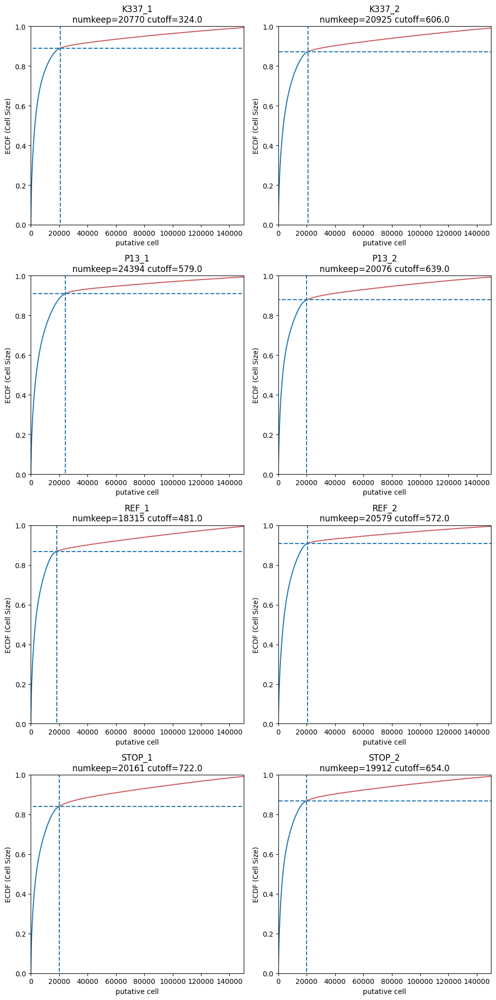

In [11]:
nrows=4
ncols=2
plt.subplots(nrows=nrows,ncols=ncols,figsize=(ncols*5,nrows*5))
cutoffs=[]
for idx in range(len(adatas)):
    ax = plt.subplot(nrows, ncols, idx+1)
    is_invalid = np.array(adatas[idx].obs['library_size'] < 0)
    is_invalid = scrpr.filter_low_count(adatas[idx].X, is_invalid, plot=True, ax=ax, adjust_inflection_pt=0.9, num_rolling=100)
    cutoffs.append(np.max(adatas[idx].obs.iloc[is_invalid]['library_size']))
    ax.set_title(f"{samples[idx]}\nnumkeep={sum(~is_invalid)} cutoff={cutoffs[-1]}")
    ax.set_xlim(0, 150000)
plt.tight_layout()
plt.show()

0 K337_1
1 K337_2
2 P13_1
3 P13_2
4 REF_1
5 REF_2
6 STOP_1
7 STOP_2


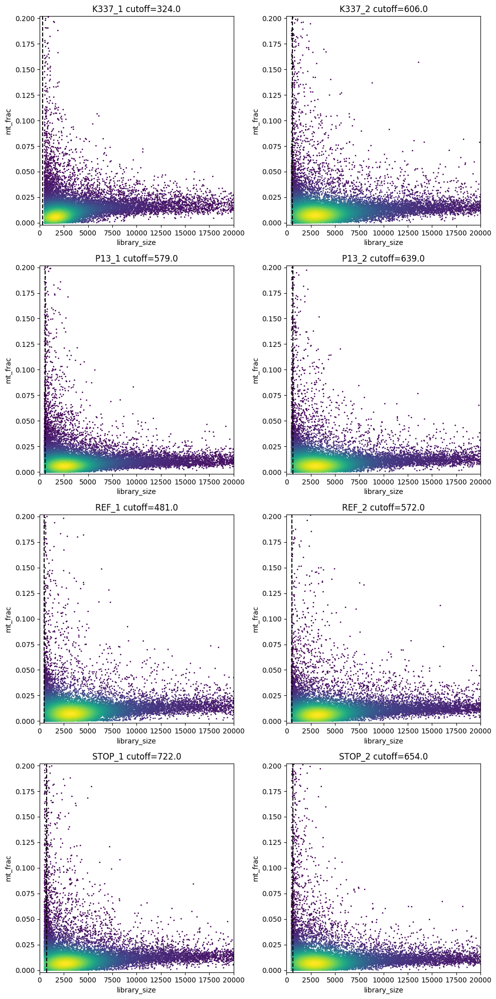

6 STOP_1


7 STOP_2


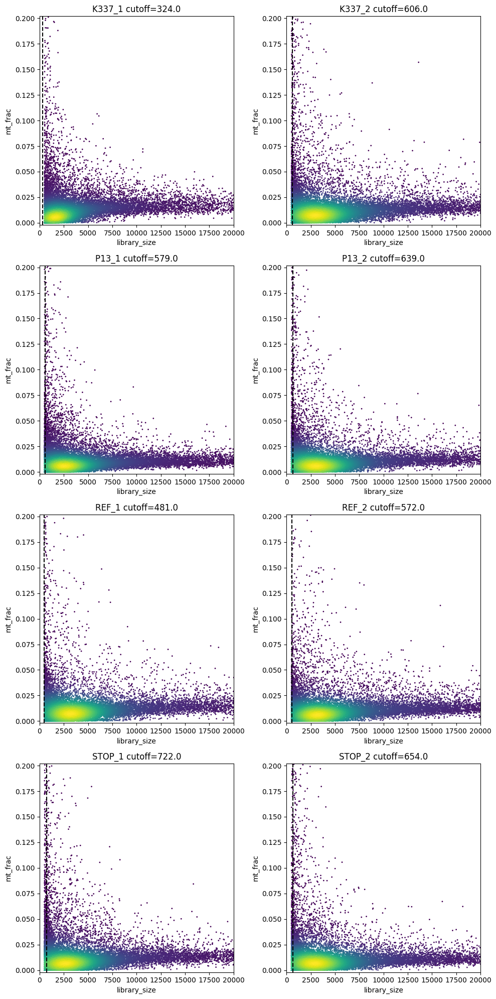

In [12]:
plt.subplots(nrows=nrows, ncols=ncols, figsize=(ncols*5, nrows*5))
idx=1
maxval = np.max(np.array([np.max(adata.obs['library_size']) for adata in adatas]))
maxmt = np.max(np.array([np.max(adata.obs['mt_frac']) for adata in adatas]))
maxmt=0.2
for i,adata in enumerate(adatas):
    f = adata.obs['library_size'] > 500 # skip very empty cells, otherwise plot_scatter_continuous blows up
    x = np.array(adata.obs.loc[f,'library_size'])
    y = np.array(adata.obs.loc[f,'mt_frac'])
    sample = adata.obs['sample'].iloc[0]
    print(i, sample)
    ax = plt.subplot(nrows, ncols, idx)
    idx=idx+1
    scrpr.plot_scatter_continuous(x, y, ax=ax, colorbar=False, s=1)
    ax.set_xlabel('library_size')
    ax.set_ylabel('mt_frac')
    ax.set_title(f'{sample} cutoff={cutoffs[i]}')
    ax.set_xlim((-maxval*0.01, maxval*1.01))
    ax.set_ylim((-maxmt*0.01, maxmt*1.010))
    plt.axvline(cutoffs[i], color='black', linestyle='--')
    plt.xlim(0, 20000)
plt.tight_layout()
plt.show()

In [13]:
for i in range(len(adatas)):
    adatas[i] = adatas[i][adatas[i].obs['library_size'] > cutoffs[i]]

In [14]:
adata = sc.concat(adatas, merge='same')

In [15]:
adata.shape

(165132, 32245)

In [16]:
adata.obs['sample'].value_counts()

sample
P13_1     24394
K337_2    20925
K337_1    20770
REF_2     20579
STOP_1    20161
P13_2     20076
STOP_2    19912
REF_1     18315
Name: count, dtype: int64

## Some cell filtering/quality

__This next section filters high-mitochondrial cells, below is using a cutoff of 20%, may want to review cutoff with ashley__

In [17]:
adata.var['feature_types'].unique()

array(['Gene Expression'], dtype=object)

In [18]:
genes = list(adatas[0].var.index)

Cells removed: 359
Cells remaining: 20411
Cells removed: 302
Cells remaining: 20623
Cells removed: 182
Cells remaining: 24212
Cells removed: 231
Cells remaining: 19845
Cells removed: 291
Cells remaining: 18024
Cells removed: 204
Cells remaining: 20375
Cells removed: 230
Cells remaining: 19931
Cells removed: 294
Cells remaining: 19618


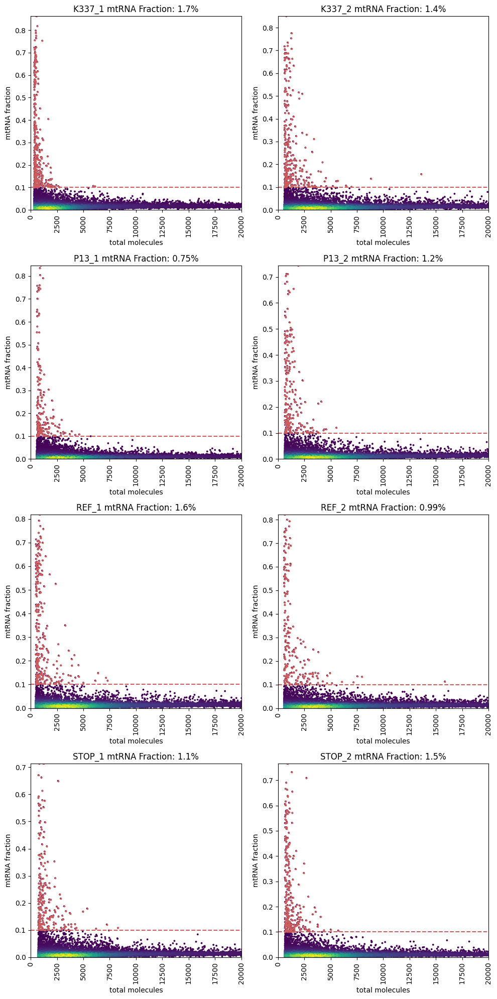

Cells removed: 230
Cells remaining: 19931


Cells removed: 294
Cells remaining: 19618


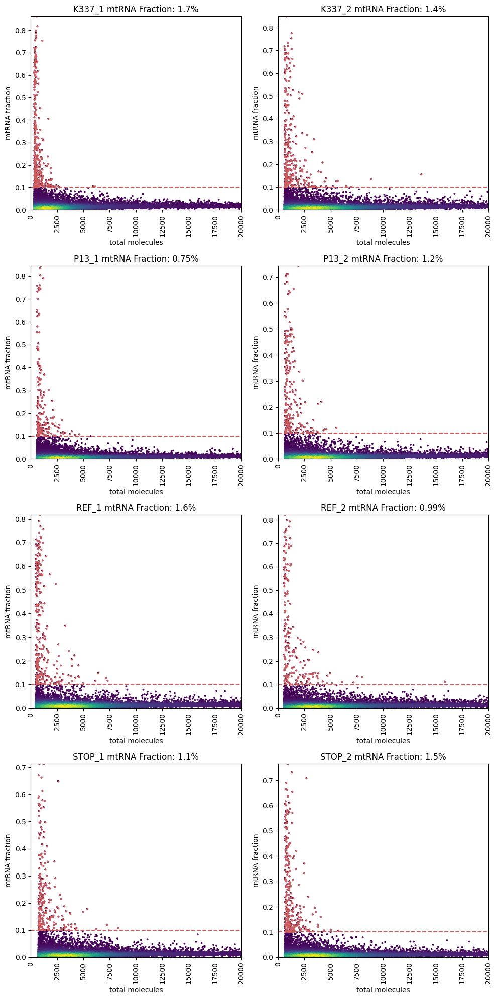

In [19]:
mito_thresh = 0.1
idx=1
fig = plt.subplots(nrows=nrows, ncols=ncols, figsize=(ncols*5, nrows*5))
mt_invalid = {}
for sample in samples:
    ax = plt.subplot(nrows, ncols, idx)
    idx=idx+1
    f = adata.obs['sample'] == sample
    mt_invalid[sample] = np.zeros(sum(f), bool)
    low_count_dict = {}
    molecules = coo_matrix(adata[f].X)
    mt_invalid[sample] = scrpr.filter_high_mitochondrial_rna(molecules, genes, mt_invalid[sample], 
                                                     max_mt_content=mito_thresh, plot=True, 
                                                     ax=ax, mt_prefix='mt-')
    print(f"Cells removed: {np.count_nonzero(mt_invalid[sample])}")
    print(f"Cells remaining: {np.count_nonzero(mt_invalid[sample]==0)}")
    ax = plt.gca()
    txt = ax.get_title()
    ax.set_title(sample + ' '  + txt)
    ax.set_xlim(0, 20000)
    #plt.savefig(f'{output_dir}/mtFilter.png', dpi=400)
plt.tight_layout()
plt.show()

### coverage

ymax=11.577868852459016
Cells removed: 359
Cells remaining: 20411
Cells failing this filter: 0
ymax=13.47069065583285
Cells removed: 313
Cells remaining: 20612
Cells failing this filter: 11
ymax=4.202591283863368
Cells removed: 416
Cells remaining: 23978
Cells failing this filter: 234
ymax=4.3979430379746836
Cells removed: 614
Cells remaining: 19462
Cells failing this filter: 383
ymax=12.799829642248723
Cells removed: 474
Cells remaining: 17841
Cells failing this filter: 183
ymax=3.9991714995857497
Cells removed: 432
Cells remaining: 20147
Cells failing this filter: 228
ymax=4.8055207026348805
Cells removed: 940
Cells remaining: 19221
Cells failing this filter: 710
ymax=3.1242502142245074
Cells removed: 689
Cells remaining: 19223
Cells failing this filter: 395


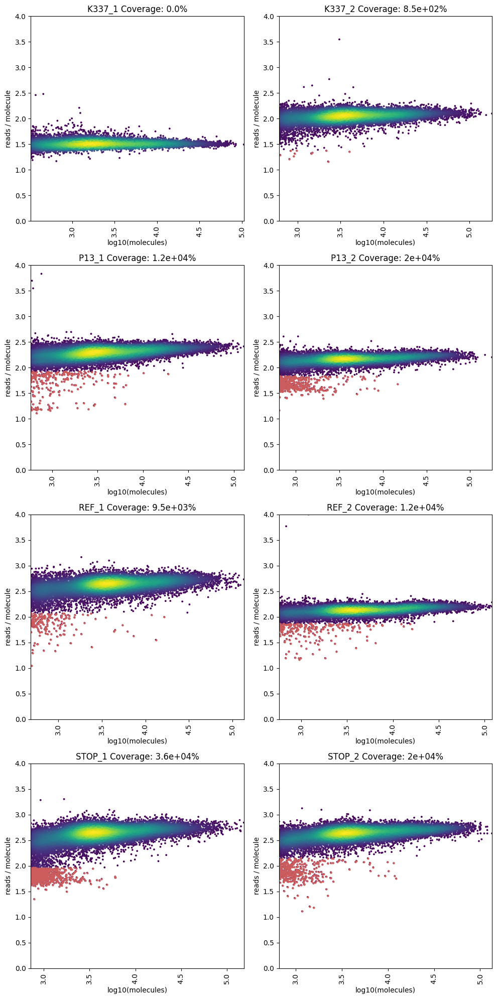

ymax=4.8055207026348805
Cells removed: 940
Cells remaining: 19221
Cells failing this filter: 710


ymax=3.1242502142245074
Cells removed: 689
Cells remaining: 19223
Cells failing this filter: 395


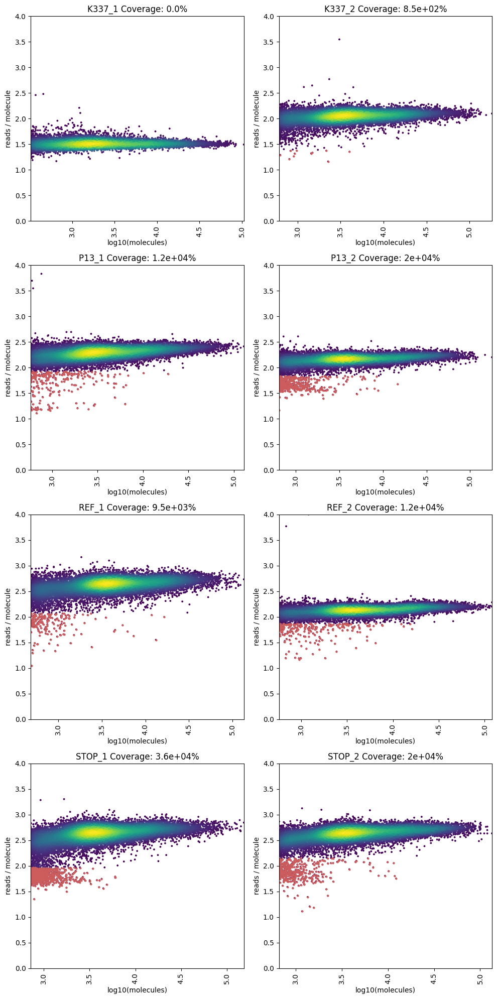

In [20]:
idx=1
fig, ax = plt.subplots(nrows=nrows, ncols=ncols, figsize=(5*ncols, 5*nrows))
cov_invalid = {}
for sample in samples:
    ax = plt.subplot(nrows, ncols, idx)
    idx=idx+1
    f = adata.obs['sample'] == sample
    molecules = coo_matrix(adata[f].X)
    cov_invalid[sample] = scrpr.filter_low_coverage(molecules, adata[f].layers['read_matrix'], 
                                                    mt_invalid[sample], cutoff=3, plot=True, ax = ax)
    print(f"Cells removed: {np.count_nonzero(cov_invalid[sample])}")
    print(f"Cells remaining: {np.count_nonzero(cov_invalid[sample]==0)}")
    print(f"Cells failing this filter: {sum(cov_invalid[sample]) - sum(mt_invalid[sample])}")
    ax = plt.gca()
    txt = ax.get_title()
    ax.set_title(sample + ' '  + txt)
    ax.set_ylim(0, 4.0)

# SAVE FIGURE
#fn = output_dir + '/readsPerMolecule_vs_size.png'
plt.tight_layout()
#plt.savefig(fn, dpi=400)
plt.show()

### Complexity

In [21]:
is_invalid = {}
for sample in samples:
    is_invalid[sample] = (mt_invalid[sample] ) | (cov_invalid[sample])
    print(sample, sum(is_invalid[sample]))

K337_1 359
K337_2 313
P13_1 416
P13_2 614
REF_1 474
REF_2 432
STOP_1 940
STOP_2 689


Cells removed: 371
Cells remaining: 20399
Cells failing this filter: 12
Cells removed: 326
Cells remaining: 20599
Cells failing this filter: 13
Cells removed: 428
Cells remaining: 23966
Cells failing this filter: 12
Cells removed: 629
Cells remaining: 19447
Cells failing this filter: 15
Cells removed: 498
Cells remaining: 17817
Cells failing this filter: 24
Cells removed: 445
Cells remaining: 20134
Cells failing this filter: 13
Cells removed: 952
Cells remaining: 19209
Cells failing this filter: 12
Cells removed: 709
Cells remaining: 19203
Cells failing this filter: 20


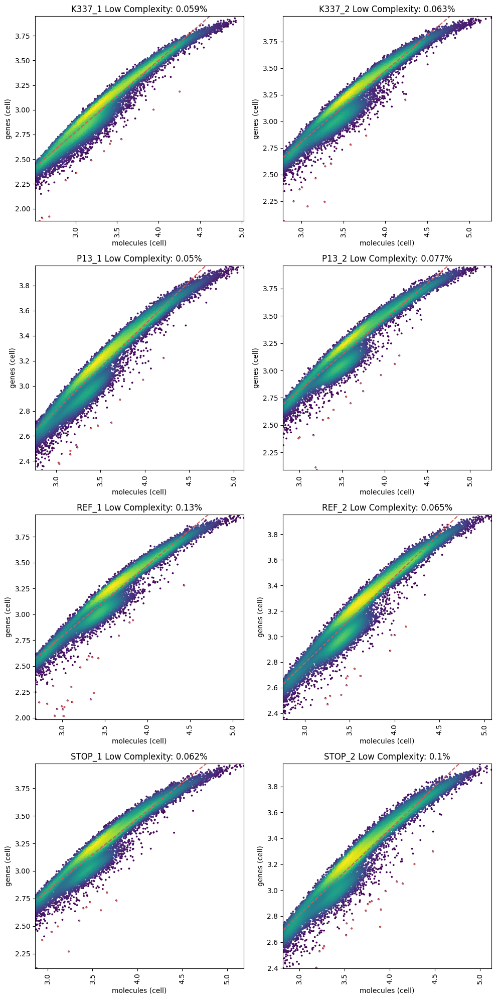

Cells removed: 952
Cells remaining: 19209
Cells failing this filter: 12


Cells removed: 709
Cells remaining: 19203
Cells failing this filter: 20


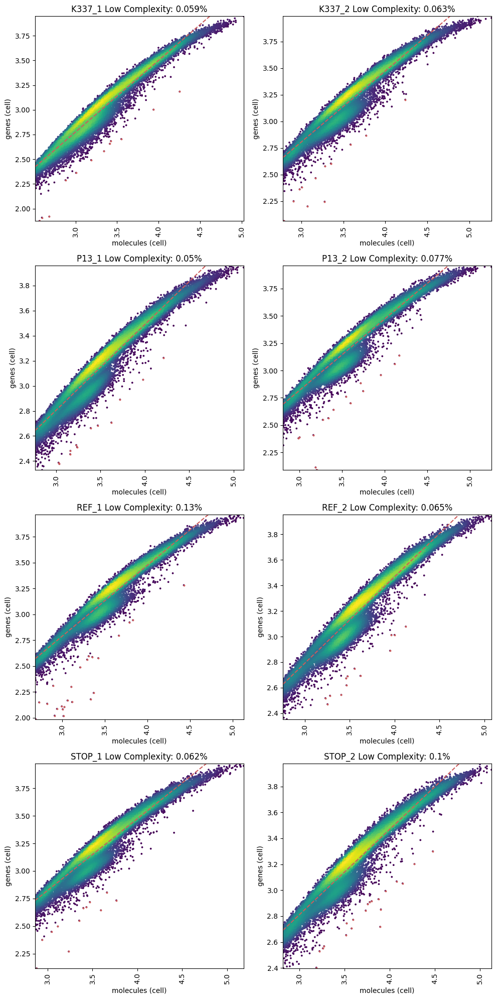

In [22]:
fig, ax = plt.subplots(nrows=nrows, ncols=ncols, figsize=(5*ncols, 5*nrows))
idx = 1
complexity_invalid = {}
for sample in samples:
    ax = plt.subplot(nrows, ncols, idx)
    idx=idx+1
    f = adata.obs['sample'] == sample
    molecules = coo_matrix(adata[f].X)
    complexity_invalid[sample] = scrpr.filter_low_gene_abundance(molecules, 
                                                         is_invalid[sample], residual_cutoff=0.40, plot=True, ax=ax)
    print(f"Cells removed: {np.count_nonzero(complexity_invalid[sample])}")
    print(f"Cells remaining: {np.count_nonzero(complexity_invalid[sample]==0)}")
    print(f"Cells failing this filter: {sum(complexity_invalid[sample]) - sum(is_invalid[sample])}")

    ax = plt.gca()
    txt = ax.get_title()
    ax.set_title(sample + ' '  + txt)

#fn = output_dir + '/complexityFilter.png'
plt.tight_layout()
#plt.savefig(fn, dpi=400)
plt.show()

In [23]:
for sample in samples:
    is_invalid[sample] = (is_invalid[sample] ) | (complexity_invalid[sample])
    print(sample, sum(is_invalid[sample]))

K337_1 371
K337_2 326
P13_1 428
P13_2 629
REF_1 498
REF_2 445
STOP_1 952
STOP_2 709


In [24]:
all_invalid = np.zeros(adata.shape[0], bool)
for s in samples:
    f = (adata.obs['sample'] == s)
    all_invalid[f] = is_invalid[s]
adata = adata[~all_invalid]
adata.shape

(160774, 32245)

In [25]:
adata.obs['totReads'] = np.array(np.sum(adata[:,genes].layers['read_matrix'], axis=1)).reshape(-1)
adata.obs['library_size'] = np.squeeze(np.asarray(np.sum(adata[:,genes].X, axis=1)))
adata.layers['X_orig'] = adata.X.copy()
sc.pp.normalize_total(adata, target_sum=10000)
adata.layers['X'] = adata.X.copy()
adata.X = adata.layers['X'].copy()

# note: next 3 lines are equivalent to adata.layers['logX'] = np.log10(adata.X+0.1)-np.log10(0.1) = np.log10(10x+1)
adata.X = adata.X*10
sc.pp.log1p(adata, base=10)
adata.layers['logX'] = adata.X.copy()
print(np.max(adata.layers['logX']), np.max(adata.layers['X']))

/tmp/ipykernel_58269/134937359.py:1: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs['totReads'] = np.array(np.sum(adata[:,genes].layers['read_matrix'], axis=1)).reshape(-1)


4.8293104 6750.0


## Cell assign

In [26]:

warnings.filterwarnings(
    "ignore",
    message="The default value of 'ignore' for the `na_action` parameter.*",
    category=FutureWarning,
)

warnings.filterwarnings(
    "ignore",
    message="No data for colormapping provided via 'c'.*",
    category=UserWarning,
)

In [27]:
!mkdir -p NOBACKUP

In [28]:
tmpadata = sc.AnnData(X=adata.layers['X'], obs=adata.obs, var=adata.var).copy()
    
tmpadata.var['gene_ids'] = tmpadata.var.index.copy()
tmpadata.layers['X'] = tmpadata.X
tmpadata.write('NOBACKUP/adata_cellassign_input.h5ad')
        
mfile='data/lung_markers_with_4T1'

Note: cellAssign was run on a different server (with GPU) in a docker container named biohpc/scrna-gpu:0.0.1 (available in dockerhub). 

cellassign was run in chunks of ~1000 cells (chosen by index number modulus num_chunk). This is the code used:

```
numchunk=161
for i in `seq 1 $numchunk; do
    docker run --rm -i \
      -v "$PWD":/work -w /work \
      biohpc/scrna-gpu:0.0.1 \
      R --vanilla --args \
      --infile NOBACKUP/adata_cellassign_input.h5ad \
      --outroot cellAssign_results/cellAssign_${i}_${numcunk} \
      --markers data/lung_markers_with_4T1.csv \
      --seed 12345 --seed2 54321 --sample-cells ${i} ${numchunk} \
      < callCellAssign_gpu.sh
done
```


The results are in the data/cellAssign subdirectory of this repository. Note: it was originally run on a version of the data without doublet filtering. Which is why there are 161 chunks. We remove results for cells that have been filtered out below.

__Now read in the reuslts__

In [29]:
#Note: The "assignments" files contain the row index 9cell name)
# "probs" files have same order but no index
# We are only interested in probs but need to read both to get cell name

adata.obs['cellAssign_0.8'] = ''
adata.obs['cellAssign_maxprob'] = -1.0

files=glob.glob('data/cellAssign/cellAssign_*assignments.txt*')
print(f'Reading cellassign results from {len(files)} files')
probs=[]
for f in files:
    tmp = pd.read_csv(f, sep='\t', index_col=0)
    tmpf = f.replace('assignments', 'probs')
    tmp2 = pd.read_csv(tmpf, sep='\t')
    tmp2.index = tmp.index
    tmp = tmp.loc[tmp.index.isin(adata.obs.index)]
    tmp2 = tmp2.loc[tmp2.index.isin(adata.obs.index)]
    probs.append(tmp2)
    adata.obs.loc[tmp.index,'cellAssign_0.8'] = tmp['celltype']
    adata.obs.loc[tmp2.index,'cellAssign_maxprob'] = np.max(tmp2, axis=1)
    f1 = adata.obs['cellAssign_maxprob'] > 0.8
    tmp3 = tmp2.loc[f1].idxmax(axis=1)
    adata.obs.loc[tmp3.index,'cellAssign_0.8'] = tmp3

Reading cellassign results from 161 files


In [30]:
celltype_colors={
 'AT1': '#E37979',
 'AT2': 'darkred',
 # 'Alveolar macrophages': '#7AD9DA',
 'AM': '#7AD9DA',
 'B cells': '#F9D318',
 'Basal cells': '#7FD5A6',
 #'Basophils': '#7fabaf',
 'Basophil': '#7fabaf',
 #'Cardiomyocytes': '#C15376',
 #'Ciliated cells': '#D39939',
 'Ciliated': '#D39939',
 'Chondrocyte':  '#C15376',
 'cDCs': '#C438FB',
 'Endothelial cells': '#6B0C0C',
 #'Fibroblast cells': '#216C04',
 'Fibroblasts':'#216C04',
 #'ILCs': '#95c300',
 'ILC': '#95c300',
 #'Interstitial macrophages': '#7AAEDA',
  'IM':'#7AAEDA',
 #'Lymphatic EC': '#BD872F',
 'LEC': '#BD872F',
 'Mast cells': '#A16E0F',
 #'Mesothelium': '#E16666',
  'Mesothelial': '#E16666',
 #'Monocytes': '#51ECAE',
  'iMON':'#51ECAE',
 'NK cells': '#EA0C0C',
 #'Neutrophils': '#9CA7A8',
'Neutrophil': '#9CA7A8',
 'PNEC': '#0B11C7',
 'Pericytes': '#00cc20',
 'pDCs':'#692791',
 #'Secretory cells': '#B0A170',
 'Secretory': '#B0A170',
 'Smooth Muscle': '#946E6E',
 'T cells': '#F47D08',
  '4T1':'darkblue',
 'Platelet':'turquoise',
 'SCMF':'magenta',
'unassigned':'lightgray'}

In [31]:
raw_to_color_celltype = {
    'IM': 'Interstitial macrophages',
    'Neutrophil': 'Neutrophils',
    'AM': 'Alveolar macrophages',
    'Fibroblasts': 'Fibroblast cells',
    'LEC': 'Lymphatic EC',
    'Basophil': 'Basophils',
    'Mesothelial': 'Mesothelium',
    'ILC': 'ILCs',
    'iMON': 'Monocytes',
    'Ciliated': 'Ciliated cells',
    'Secretory': 'Secretory cells',
}
raw_to_color_celltype = {}

In [32]:
celltypes=set(adata.obs['cellAssign_0.8'].value_counts().index)

In [33]:
for celltype in adata.obs['cellAssign_0.8'].unique():
    if celltype not in celltype_colors:
        print(celltype)

In [34]:
# use ethan's cell type names
adata.obs['cellAssign_0.8'] = adata.obs['cellAssign_0.8'].astype(str)
for celltype in adata.obs['cellAssign_0.8'].unique():    
    if celltype in celltype_colors:
        continue
    if celltype not in raw_to_color_celltype:
        print(f'error _{celltype}_')
    if raw_to_color_celltype[celltype] != celltype:
        f = adata.obs['cellAssign_0.8'] == celltype
        adata.obs.loc[f,'cellAssign_0.8'] = raw_to_color_celltype[celltype]
adata.obs['cellAssign_0.8'] = pd.Categorical(adata.obs['cellAssign_0.8'], categories=celltype_colors.keys())
adata.uns['cellAssign_0.8_colors'] = [celltype_colors[x] for x in adata.obs['cellAssign_0.8'].cat.categories]

## Doublets

In [35]:
scrub = scr.Scrublet(adata.layers['X_orig'])
doublet_scores, predicted_doublets = scrub.scrub_doublets()

Preprocessing...
Simulating doublets...
Embedding transcriptomes using PCA...
Calculating doublet scores...
Automatically set threshold at doublet score = 0.31
Detected doublet rate = 3.7%
Estimated detectable doublet fraction = 36.8%
Overall doublet rate:
	Expected   = 10.0%
	Estimated  = 10.1%
Elapsed time: 591.7 seconds


Calculating doublet scores...


Automatically set threshold at doublet score = 0.31
Detected doublet rate = 3.7%
Estimated detectable doublet fraction = 36.8%
Overall doublet rate:
	Expected   = 10.0%
	Estimated  = 10.1%
Elapsed time: 632.1 seconds


In [36]:
adata.obs['scrublet'] = doublet_scores

Text(0, 0.5, 'number of cells')

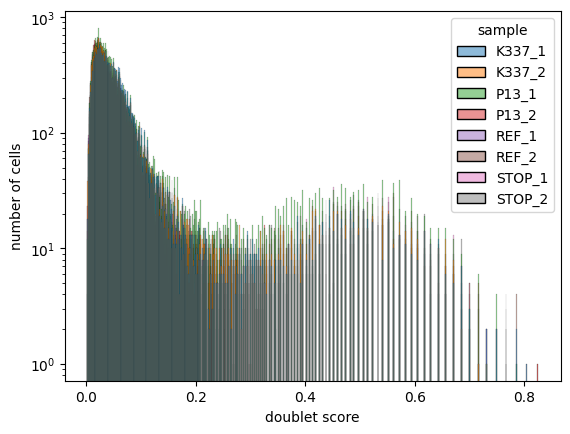

In [37]:
sns.histplot(data=adata.obs, x='scrublet', hue='sample')

plt.yscale('log')
plt.xlabel('doublet score')
plt.ylabel('number of cells')

#### sclDblFinder

In [38]:
!mkdir -p NOBACKUP
tmpadata = sc.AnnData(X=adata.layers['X'], obs=adata.obs, var=adata.var)
tmpadata.layers['rawX'] = adata.layers['X'].toarray()
tmpadata.write('NOBACKUP/adata_for_scDblFinder.h5ad')

In [39]:
outfile = 'data/scdblfinder_out_clusters_samples_no_dbr.txt'
cmd=f' R --vanilla --args --infile NOBACKUP/adata_for_scDblFinder.h5ad --outfile {outfile} --clusters --samples sample < run_scDblFinder.R'
print(cmd)

 R --vanilla --args --infile NOBACKUP/adata_for_scDblFinder.h5ad --outfile data/scdblfinder_out_clusters_samples_no_dbr.txt --clusters --samples sample < run_scDblFinder.R


__NOTE__: The command above was run in a different docker environment, containing R v 4.6.0 and scDblFinder version 1.26.2

The outfile is included in this repository, so you do not need to re-run scDblFinder to continue the notebook.

To reproduce, run this command (from the command-line in linux, in the directory containing run_scDblFinder.R):

```
docker pull biohpc/scdblfinder:0.1
docker run --rm -i \
  -v "$PWD":/work -w /work \
  biohpc/scdblfinder:0.1 \
  R --vanilla --args \
  --infile NOBACKUP/adata_for_scDblFinder.h5ad \
  --outfile data/scdblfinder_out_clusters_samples_no_dbr.txt \
  --clusters --samples sample \
  < run_scDblFinder.R
```

In [40]:
output_dir = os.getcwd() + '/doublet_plots'
!mkdir -p {output_dir}


 scDbl_class
singlet    149323
doublet     11451
Name: count, dtype: int64 



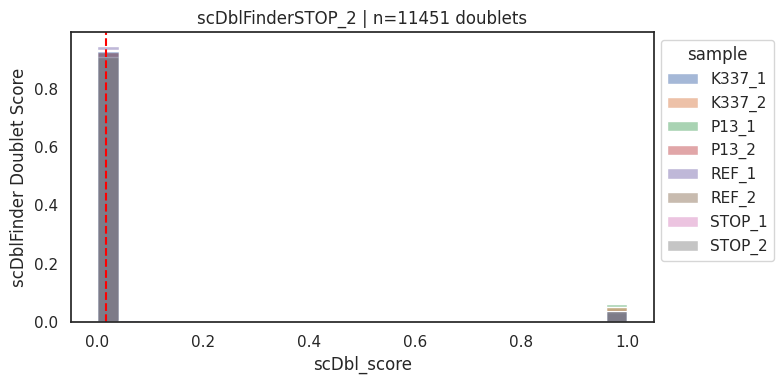

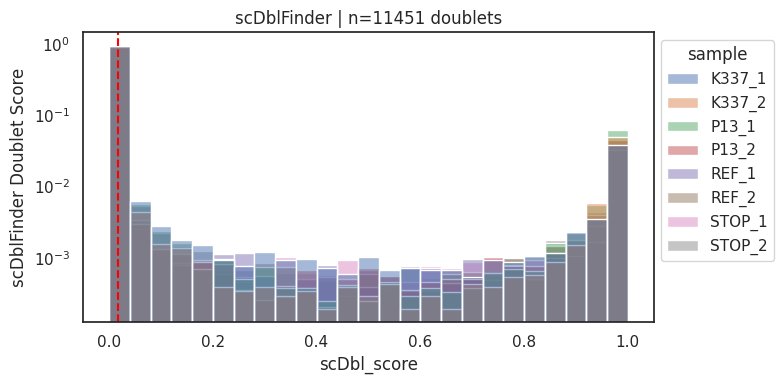

In [41]:
if not os.path.exists(outfile):
    print(f'{outfile} does not exist, cannot read scDblFinder results')
else:
    scdbl_results = pd.read_csv(outfile)
    scdbl_thr = scdbl_results[scdbl_results['scDblFinder.class'] == 'doublet']['scDblFinder.score'].min()
    adata.obs['scDbl_score'] = scdbl_results['scDblFinder.score'].values.tolist()
    adata.obs['scDbl_class'] = scdbl_results['scDblFinder.class'].values.tolist()
    
    n=adata.obs['scDbl_class'].value_counts().reindex(['singlet', 'doublet']).fillna(0).astype(int)['doublet']
    sns.set(style='white')
    fig, ax = plt.subplots(figsize=(8,4))
    #plt.hist(adata.obs[f'scDbl{s}_score'].values, bins=50)
    sns.histplot(data=adata.obs, x='scDbl_score', hue='sample', ax=ax, bins=25, stat='probability', common_norm=False)
    sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
    plt.axvline(scdbl_thr, color='red', linestyle='--')
    plt.ylabel('Frequency')
    plt.ylabel('scDblFinder Doublet Score')
    plt.title(f'scDblFinder{s} | n={n} doublets')
    fn = output_dir + f'/scDblFinder{s}_distribution.png'
    plt.tight_layout()
    plt.savefig(fn, dpi=400, transparent=True, bbox_inches='tight')
    
    fig, ax = plt.subplots(figsize=(8,4))
    plt.yscale('log')
    sns.histplot(data=adata.obs, x='scDbl_score', hue='sample', ax=ax, bins=25, stat='probability', common_norm=False)
    sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
    #plt.hist(adata.obs[f'scDbl{s}_score'].values, bins=50)
    plt.axvline(scdbl_thr, color='red', linestyle='--')
    plt.ylabel('Frequency')
    plt.ylabel('scDblFinder Doublet Score')
    plt.title(f'scDblFinder | n={n} doublets')
    fn = output_dir + '/scDblFinder_distribution_log.png'
    plt.tight_layout()
    plt.savefig(fn, dpi=400, transparent=True, bbox_inches='tight')
    
    print('\n', adata.obs['scDbl_class'].value_counts().reindex(['singlet', 'doublet']).fillna(0).astype(int), '\n') 

In [42]:
adata.obs.columns

Index(['sample', 'library_size', 'mt_frac', 'totReads', 'cellAssign_0.8',
       'cellAssign_maxprob', 'scrublet', 'scDbl_score', 'scDbl_class'],
      dtype='object')

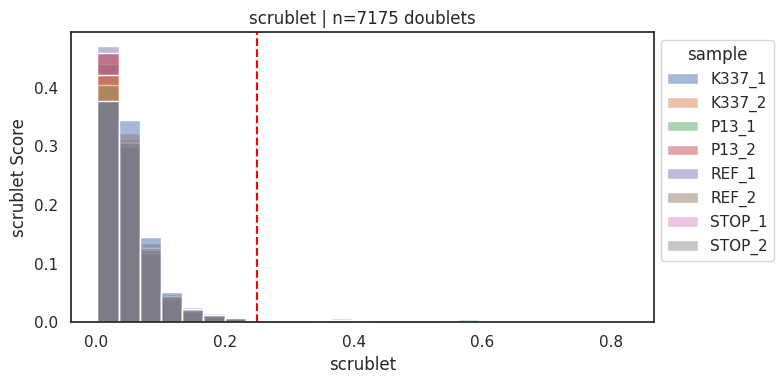

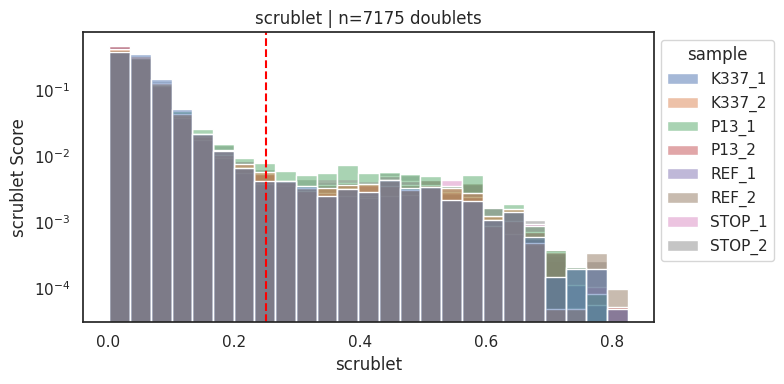

In [43]:
fig, ax = plt.subplots(figsize=(8,4))
scdbl_thr=0.25
n = sum(adata.obs['scrublet'] > scdbl_thr)
#plt.hist(adata.obs[f'scDbl{s}_score'].values, bins=50)
sns.histplot(data=adata.obs, x='scrublet', hue='sample', ax=ax, bins=25, stat='probability', common_norm=False)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.axvline(scdbl_thr, color='red', linestyle='--')
plt.ylabel('Frequency')
plt.ylabel('scrublet Score')
plt.title(f'scrublet | n={n} doublets')
fn = output_dir + '/scrublet_distribution.png'
plt.tight_layout()
plt.savefig(fn, dpi=400, transparent=True, bbox_inches='tight')

fig, ax = plt.subplots(figsize=(8,4))
plt.yscale('log')
sns.histplot(data=adata.obs, x='scrublet', hue='sample', ax=ax, bins=25, stat='probability', common_norm=False)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
#plt.hist(adata.obs[f'scDbl{s}_score'].values, bins=50)
plt.axvline(scdbl_thr, color='red', linestyle='--')
plt.ylabel('Frequency')
plt.ylabel('scrublet Score')
plt.title(f'scrublet | n={n} doublets')
fn = output_dir + '/scrublet_distribution_log.png'
plt.tight_layout()
plt.savefig(fn, dpi=400, transparent=True, bbox_inches='tight')

In [44]:
scols=['scDbl_score', 'scrublet']
adata.obs[scols].corr()

,scDbl_score,scrublet
scDbl_score,1.000000,0.721878
scrublet,0.721878,1.000000


In [45]:
adata.obs['scDbl_class'].value_counts()

scDbl_class
singlet    149323
doublet     11451
Name: count, dtype: int64

In [46]:
print('Removing doublets:')
print('Pre-doublet filter adata:', adata.shape)
adata = adata[(adata.obs['scDbl_class'] != 'doublet')]
print('Post-doublet filter adata:', adata.shape)

Removing doublets:
Pre-doublet filter adata: (160774, 32245)
Post-doublet filter adata: (149323, 32245)


## HVG / PCA / neighbors / UMAP

extracting highly variable genes


/usr/local/lib/python3.10/dist-packages/scanpy/preprocessing/_highly_variable_genes.py:258: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  disp_grouped = df.groupby("mean_bin")["dispersions"]
/usr/local/lib/python3.10/dist-packages/scanpy/preprocessing/_highly_variable_genes.py:258: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  disp_grouped = df.groupby("mean_bin")["dispersions"]
/usr/local/lib/python3.10/dist-packages/scanpy/preprocessing/_highly_variable_genes.py:258: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to r

    finished (0:00:07)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)


/usr/local/lib/python3.10/dist-packages/scanpy/preprocessing/_highly_variable_genes.py:258: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  disp_grouped = df.groupby("mean_bin")["dispersions"]
/usr/local/lib/python3.10/dist-packages/scanpy/preprocessing/_highly_variable_genes.py:508: FutureWarning: The provided callable <function nanmean at 0x7ff0800f9fc0> is currently using SeriesGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  df = df.groupby("gene").agg(
/usr/local/lib/python3.10/dist-packages/scanpy/preprocessing/_highly_variable_genes.py:508: FutureWarning: The provided callable <function nanmean at 0x7ff0800f9fc0> is currently using SeriesGroupBy.mean. In a future version of pandas, the provided

Found 4733 highly variable genes


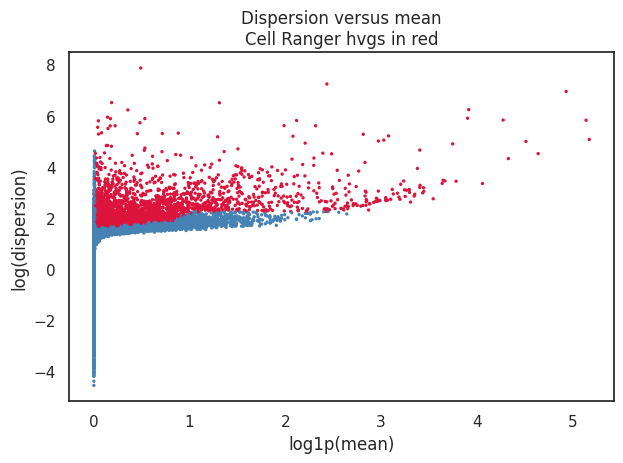

In [47]:
boolean_to_color = {True:'crimson',False:'steelblue'}
sc.settings.verbosity=4
adata.var.drop(columns=['highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatch', 'highly_variable_intersection'],
              inplace=True, errors='ignore')
sc.pp.highly_variable_genes(adata, flavor='cell_ranger', batch_key='sample', n_bins=20, max_mean=np.inf, layer='X')

colors_cell_ranger = [boolean_to_color[True] if x >0 else boolean_to_color[False]
                      for x in adata.var['highly_variable']]
plt.scatter(np.log1p(adata.var['means']), np.log(adata.var['dispersions']),
            s=2, c=colors_cell_ranger)
plt.xlabel('log1p(mean)')
plt.ylabel('log(dispersion)')
plt.title('Dispersion versus mean\nCell Ranger hvgs in red')
print(f'Found {sum(adata.var["highly_variable"])} highly variable genes')
plt.tight_layout()
plt.show()

(array([2410.,    0.,    0., 1288.,    0.,    0.,    0.,  781.,    0.,
           0.,  591.,    0.,    0.,    0.,  538.,    0.,    0.,  487.,
           0.,    0.,    0.,  610.,    0.,    0., 2553.]),
 array([1.  , 1.28, 1.56, 1.84, 2.12, 2.4 , 2.68, 2.96, 3.24, 3.52, 3.8 ,
        4.08, 4.36, 4.64, 4.92, 5.2 , 5.48, 5.76, 6.04, 6.32, 6.6 , 6.88,
        7.16, 7.44, 7.72, 8.  ]),
 <BarContainer object of 25 artists>)

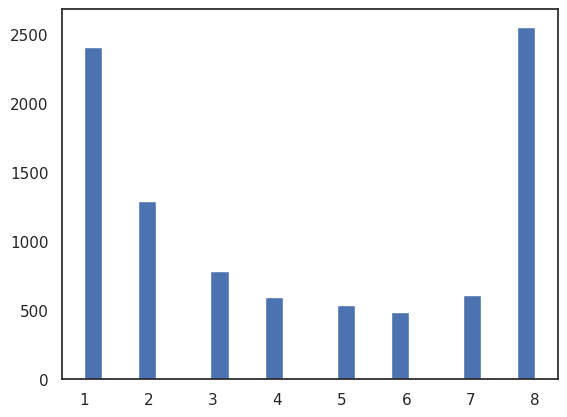

In [48]:
plt.hist(adata.var.loc[adata.var['highly_variable_nbatches'] > 0,'highly_variable_nbatches'], bins=25)

In [49]:
sum(adata.var['highly_variable'])

4733

In [50]:
sum(adata.var['highly_variable_nbatches'] > 1)

6848

In [51]:
adata.var['highly_variable'] = adata.var['highly_variable_nbatches'] > 1

In [52]:
adata.X = adata.layers['logX']
sc.tl.pca(adata, n_comps=100)

computing PCA
    on highly variable genes
    with n_comps=100
    finished (0:01:48)
    and added
    'X_pca', the PCA coordinates (adata.obs)
    'PC1', 'PC2', ..., the loadings (adata.var)
    'pca_variance', the variance / eigenvalues (adata.uns)
    'pca_variance_ratio', the variance ratio (adata.uns)


    finished (0:01:46)


    and added
    'X_pca', the PCA coordinates (adata.obs)
    'PC1', 'PC2', ..., the loadings (adata.var)
    'pca_variance', the variance / eigenvalues (adata.uns)
    'pca_variance_ratio', the variance ratio (adata.uns)


0.001
Optimal nPCs = 6
Optimal PCs index = 5
Deviation = 0.0003699919864789125


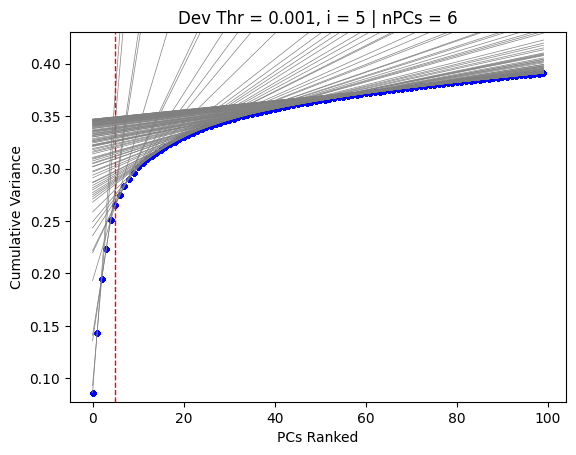

0.0009
Optimal nPCs = 6
Optimal PCs index = 5
Deviation = 0.0003699919864789125


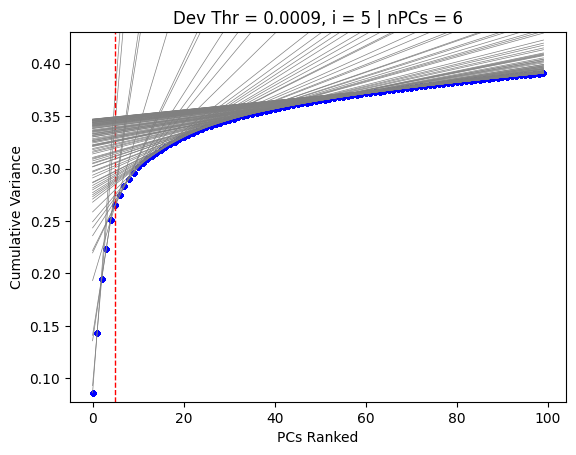

0.0008
Optimal nPCs = 6
Optimal PCs index = 5
Deviation = 0.0003699919864789125


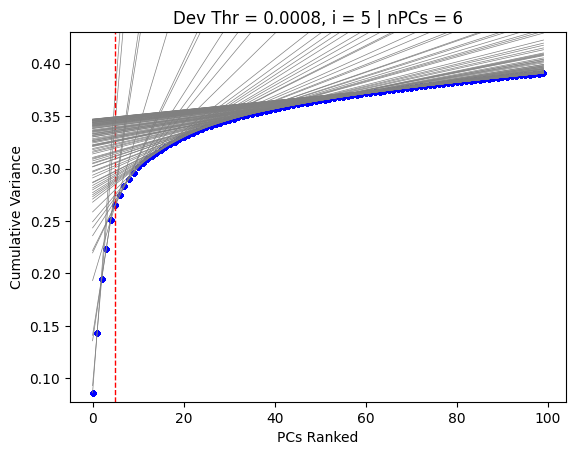

0.0007
Optimal nPCs = 6
Optimal PCs index = 5
Deviation = 0.0003699919864789125


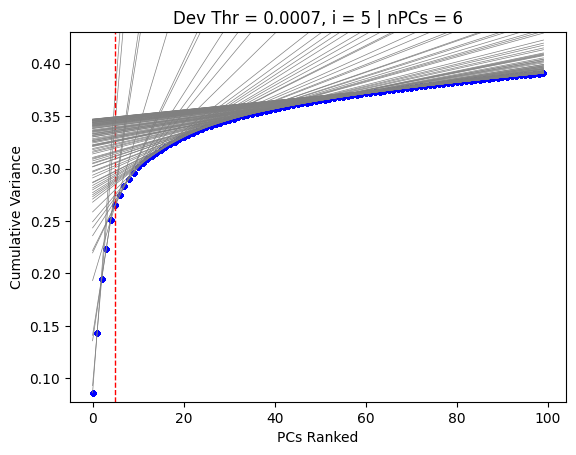

0.0006
Optimal nPCs = 6
Optimal PCs index = 5
Deviation = 0.0003699919864789125


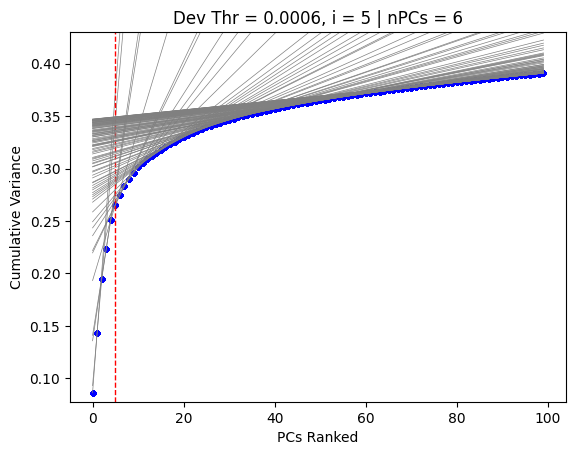

0.0005
Optimal nPCs = 6
Optimal PCs index = 5
Deviation = 0.0003699919864789125


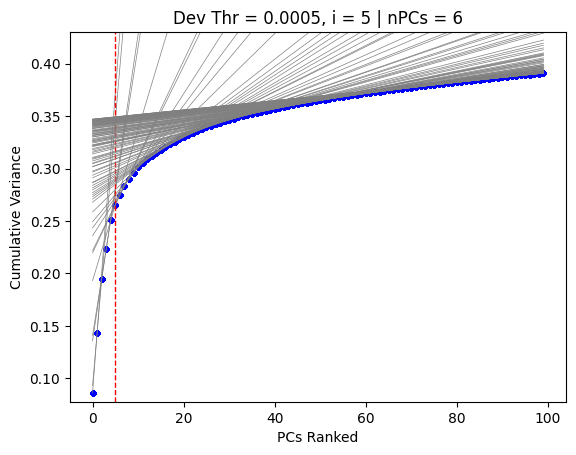

0.0004
Optimal nPCs = 6
Optimal PCs index = 5
Deviation = 0.0003699919864789125


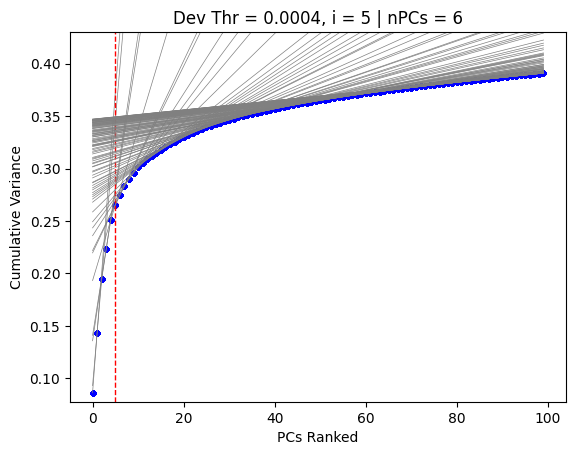

0.0003
Optimal nPCs = 12
Optimal PCs index = 11
Deviation = 0.0002490627936754253


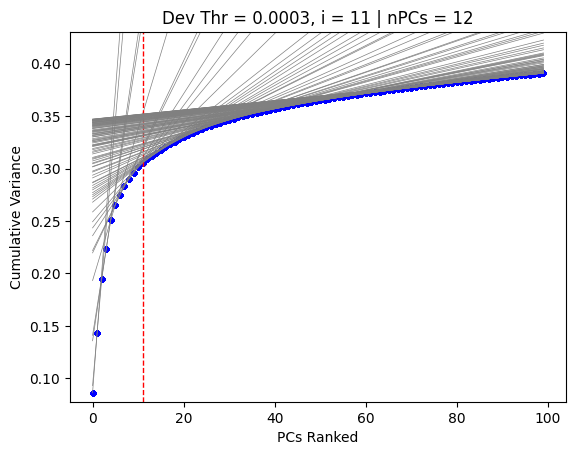

0.0002
Optimal nPCs = 13
Optimal PCs index = 12
Deviation = 0.00017587954415160256


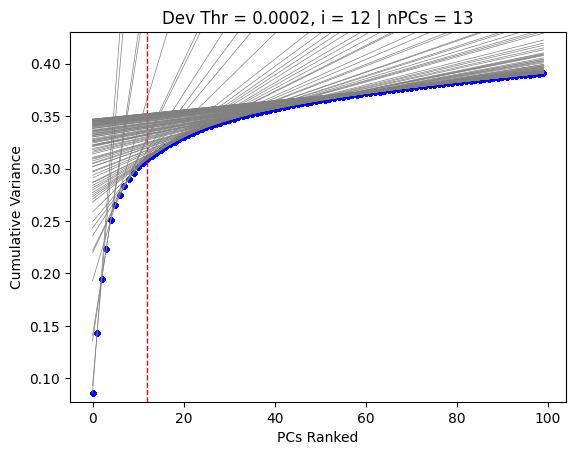

0.0001
Optimal nPCs = 20
Optimal PCs index = 19
Deviation = 2.7667619125648635e-05


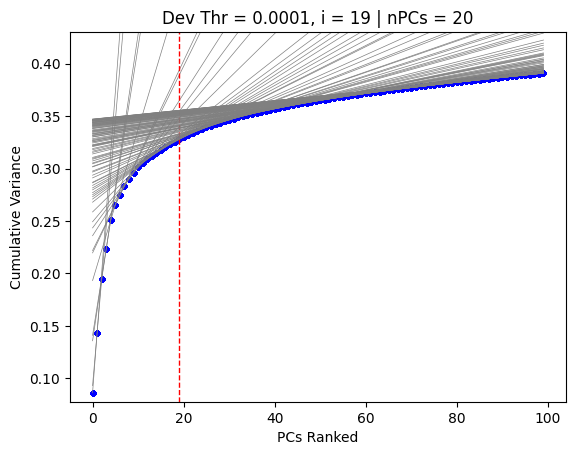

9e-05
Optimal nPCs = 20
Optimal PCs index = 19
Deviation = 2.7667619125648635e-05


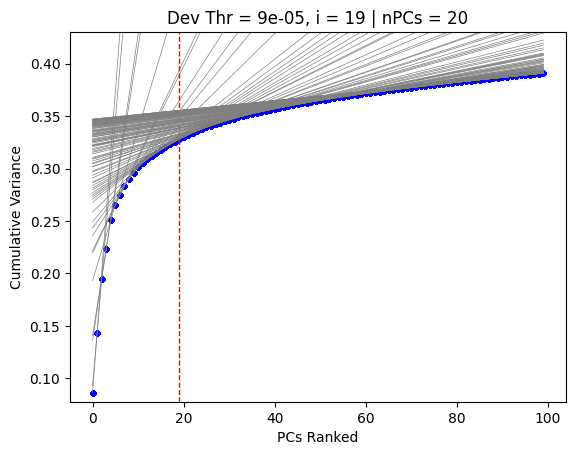

8e-05
Optimal nPCs = 20
Optimal PCs index = 19
Deviation = 2.7667619125648635e-05


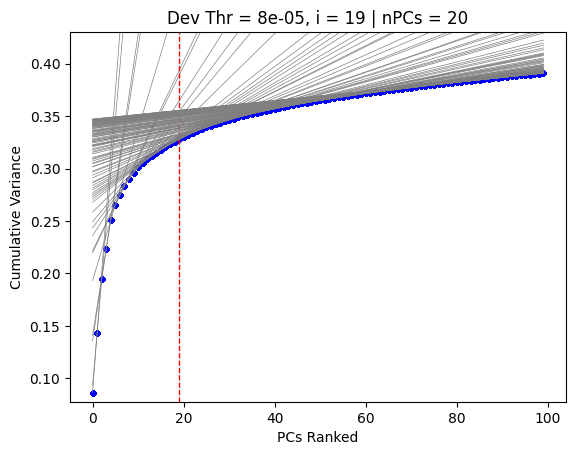

7e-05
Optimal nPCs = 20
Optimal PCs index = 19
Deviation = 2.7667619125648635e-05


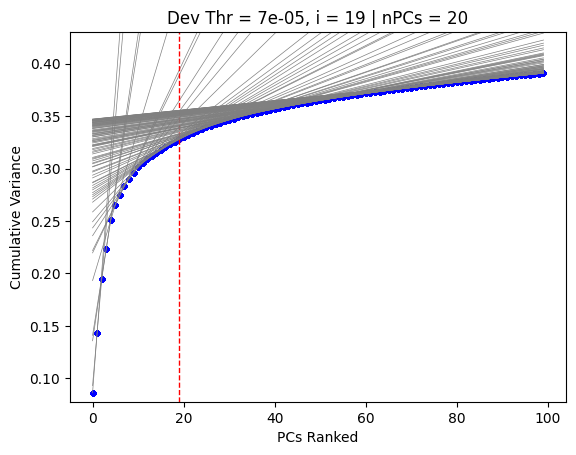

6e-05
Optimal nPCs = 20
Optimal PCs index = 19
Deviation = 2.7667619125648635e-05


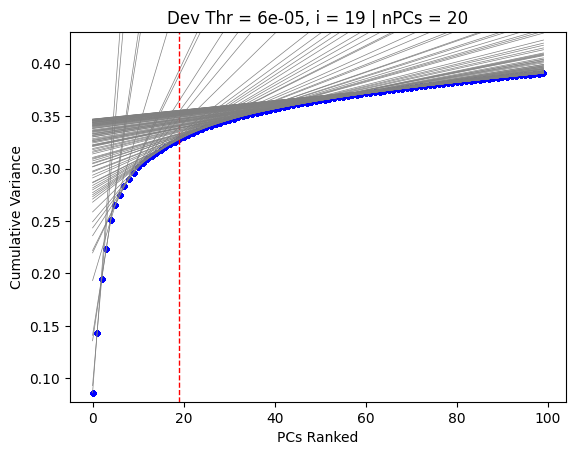

5e-05
Optimal nPCs = 20
Optimal PCs index = 19
Deviation = 2.7667619125648635e-05


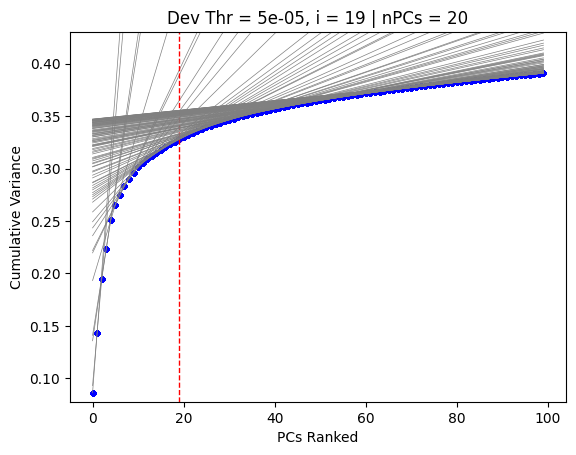

4e-05
Optimal nPCs = 20
Optimal PCs index = 19
Deviation = 2.7667619125648635e-05


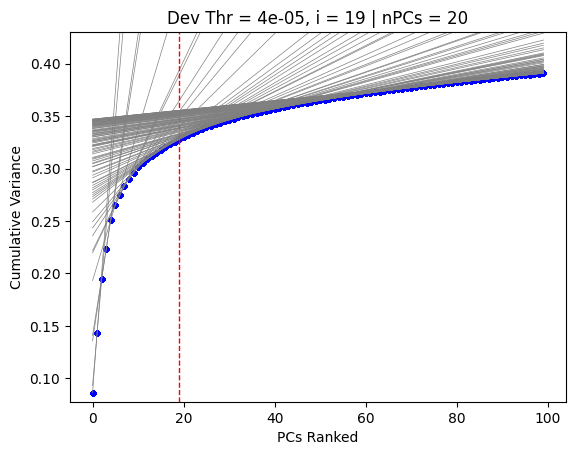

3e-05
Optimal nPCs = 20
Optimal PCs index = 19
Deviation = 2.7667619125648635e-05


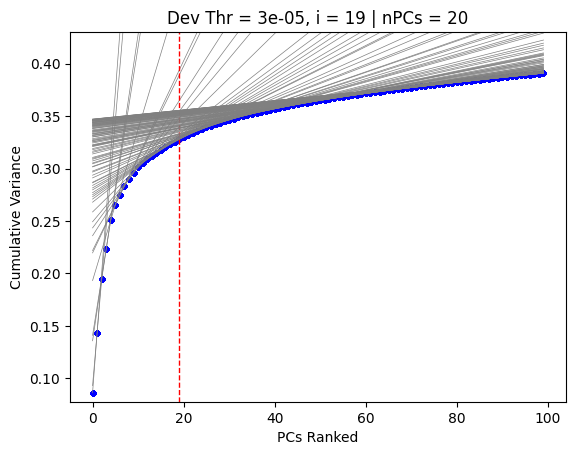

2e-05
Optimal nPCs = 26
Optimal PCs index = 25
Deviation = 1.496876117074164e-05


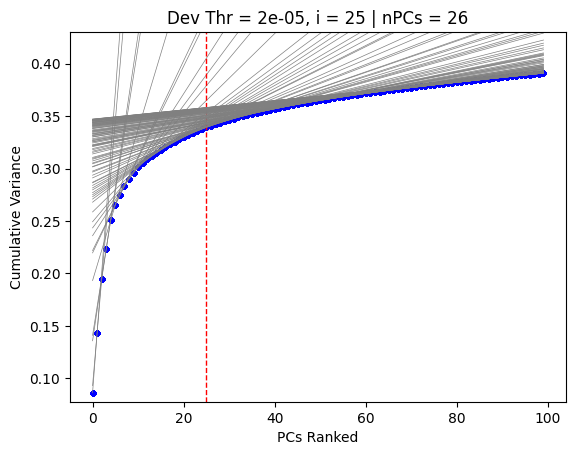

1e-05
Optimal nPCs = 41
Optimal PCs index = 40
Deviation = 8.599364894279482e-06


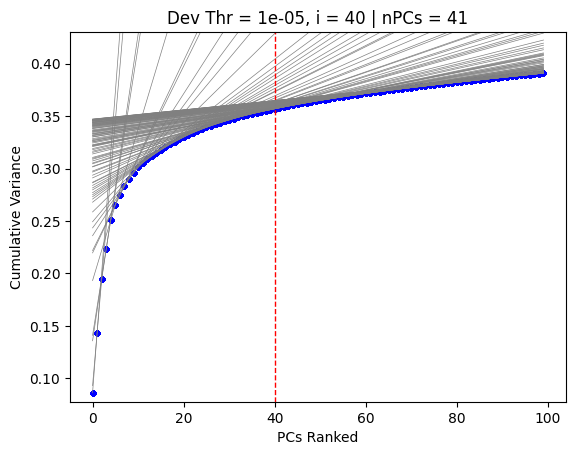

9e-06
Optimal nPCs = 41
Optimal PCs index = 40
Deviation = 8.599364894279482e-06


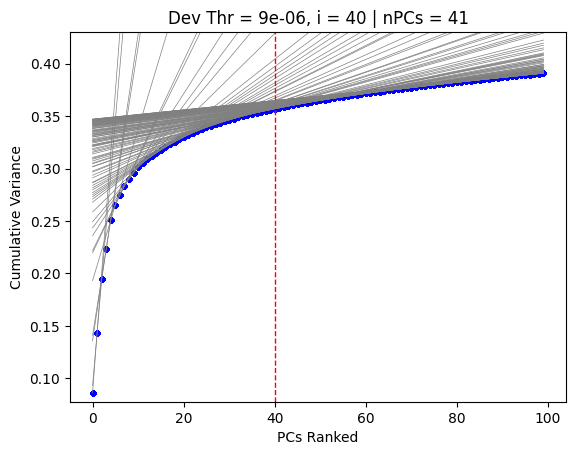

8e-06
Optimal nPCs = 45
Optimal PCs index = 44
Deviation = 6.43635558122968e-06


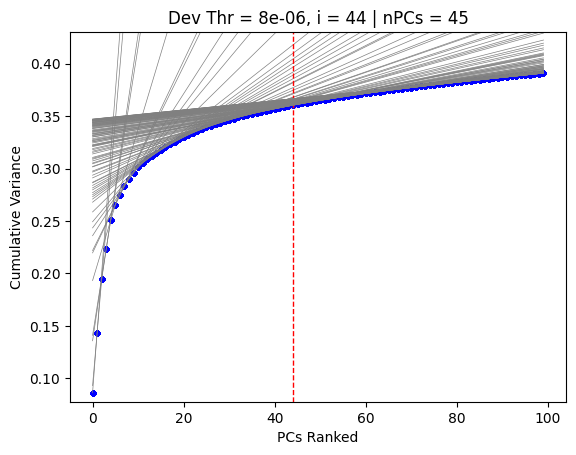

7e-06
Optimal nPCs = 45
Optimal PCs index = 44
Deviation = 6.43635558122968e-06


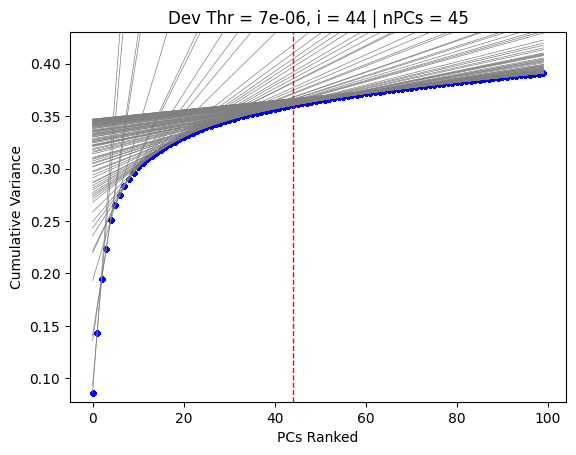

6e-06
Optimal nPCs = 51
Optimal PCs index = 50
Deviation = 3.7063007938820114e-06


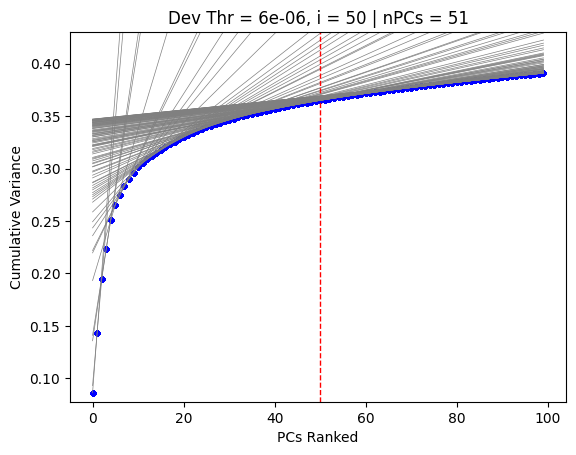

5e-06
Optimal nPCs = 51
Optimal PCs index = 50
Deviation = 3.7063007938820114e-06


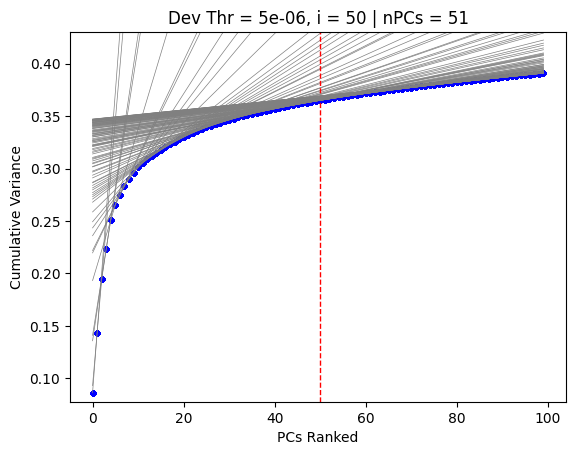

4e-06
Optimal nPCs = 51
Optimal PCs index = 50
Deviation = 3.7063007938820114e-06


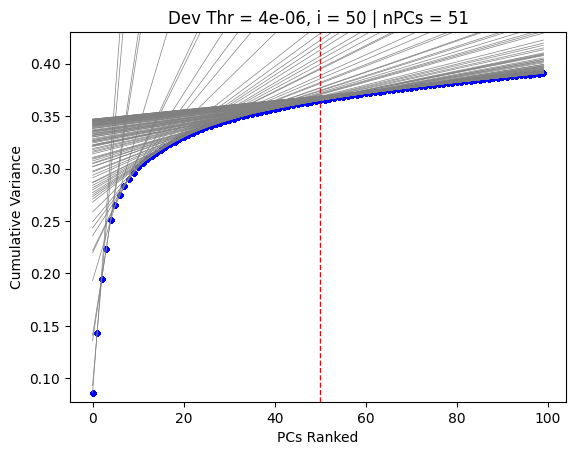

3e-06
Optimal nPCs = 54
Optimal PCs index = 53
Deviation = 1.2039764952787024e-06


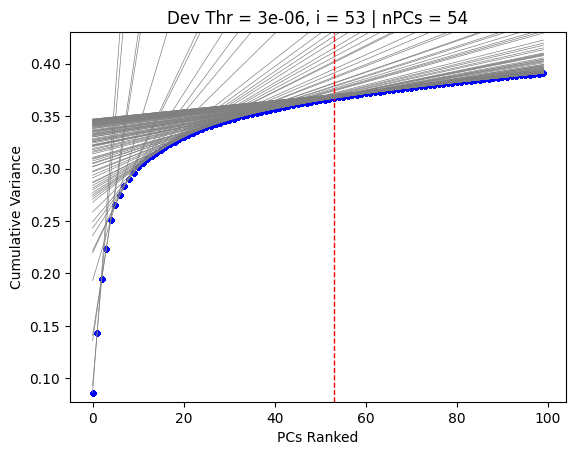

2e-06
Optimal nPCs = 54
Optimal PCs index = 53
Deviation = 1.2039764952787024e-06


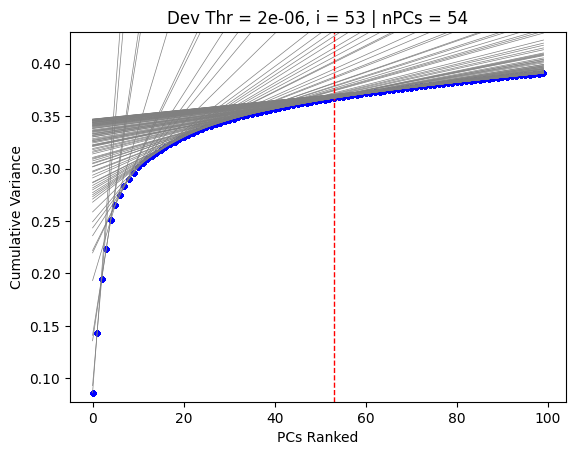

1e-08
Optimal nPCs = 100
Optimal PCs index = 99
Deviation = 1.0304675515104833e-06


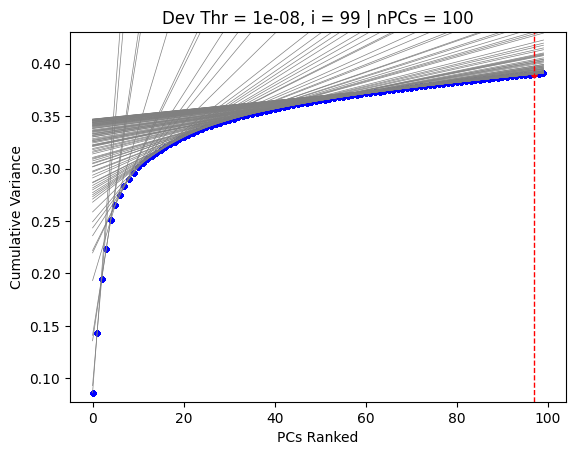

1e-09
Optimal nPCs = 100
Optimal PCs index = 99
Deviation = 1.0304675515104833e-06


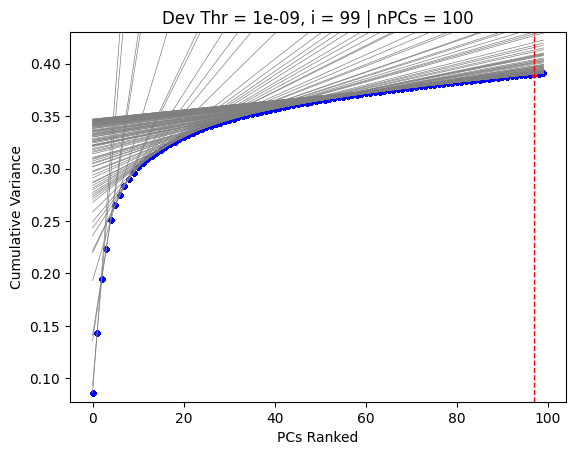

1e-10
Optimal nPCs = 100
Optimal PCs index = 99
Deviation = 1.0304675515104833e-06


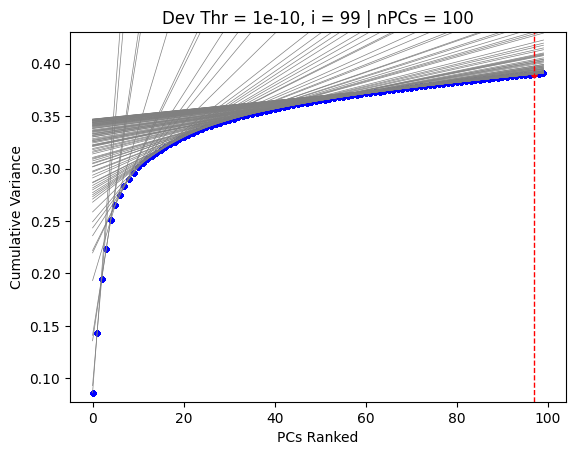

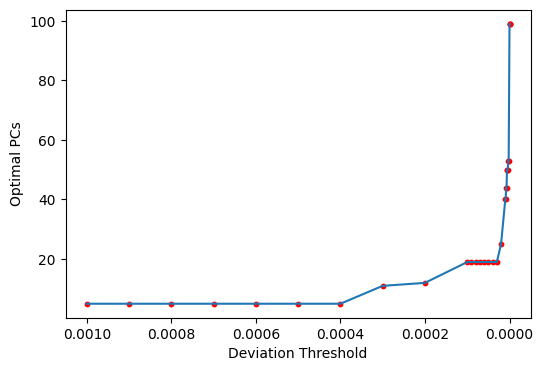

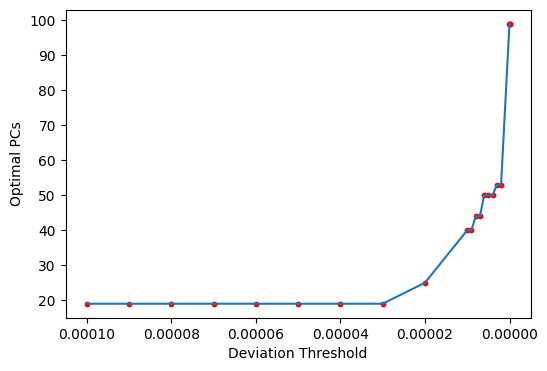

In [53]:
tmp = scrpr.optimize_dev_thr(adata, 'pca')

npc_plots/PCA_linear_deviation_optimization.png


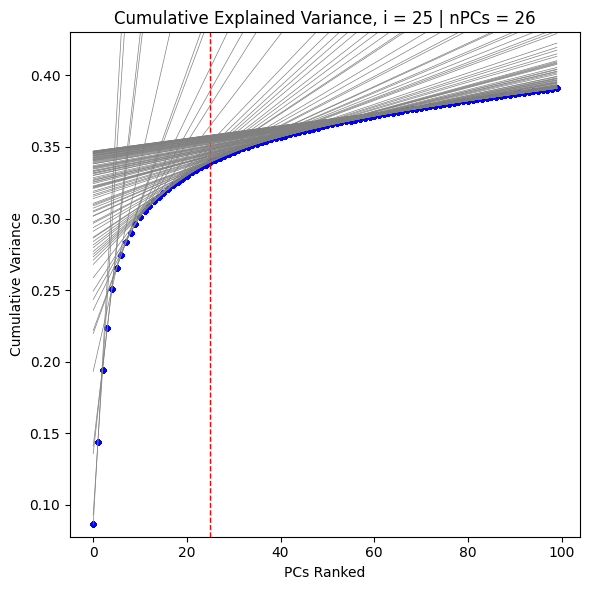

In [54]:
n_pcs = scrpr.optimize_pcs(adata, dev_thr=2e-5, output_dir='npc_plots')

In [55]:
n_pcs

26

In [56]:
sc.pp.neighbors(adata, n_pcs=n_pcs, n_neighbors=30)

computing neighbors
    computing neighbors
    using 'X_pca' with n_pcs = 26


/usr/local/lib/python3.10/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


    computed neighbors (0:00:36)
    computed connectivities (0:00:16)
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:53)


    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:53)


In [57]:
sc.tl.umap(adata, min_dist=0.5, spread=2.0)

computing UMAP


  2% 3/200 [00:01<01:10,  2.78it/s]

	completed  0  /  200 epochs


 11% 22/200 [00:11<01:47,  1.66it/s]

	completed  20  /  200 epochs


 21% 42/200 [00:24<01:35,  1.65it/s]

... (163 outputs left out)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████ | 199/200 [01:56<00:00,  1.70it/s]

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 200/200 [01:57<00:00,  1.69it/s]

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 200/200 [01:57<00:00,  1.71it/s]

    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:02:35)


__Note: due to (presumably) random number differences, the UMAP calculated by this notebook differs slightly from the published UMAP__

I will read in the UMAP originally used for published data for purposes of replication of figures.

The code below reads it in and uses 'trustworthiness' metric to demonstrate that they are extremely similar

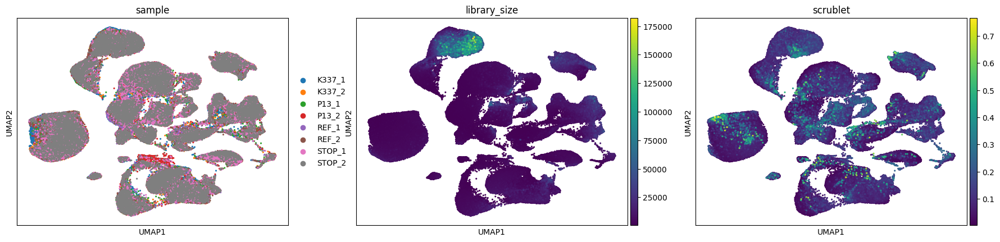

In [58]:
sc.pl.umap(adata, color=['sample', 'library_size', 'scrublet'], s=20)

In [59]:
adata.obsm['X_umap_this_session'] = adata.obsm['X_umap'].copy()

In [60]:
adata.obsm['X_umap'] = np.array(pd.read_csv('data/adata_umap.txt', sep='\t', index_col=None))

In [61]:

k = 30

rng = np.random.default_rng(123)
idx = rng.choice(adata.n_obs, size=min(5000, adata.n_obs),
                 replace=False)
X = adata.obsm['X_pca'][idx, :n_pcs]
umap_orig = adata.obsm['X_umap'][idx]
umap_new = adata.obsm['X_umap_this_session'][idx]

t_orig = trustworthiness(X, umap_orig, n_neighbors=k)
t_new = trustworthiness(X, umap_new, n_neighbors=k)

print(f"Original UMAP: {t_orig:.5f}")
print(f"New UMAP:      {t_new:.5f}")

Original UMAP: 0.98683
New UMAP:      0.98629


Explanation about trustworthiness metric and UMAP computation:

The UMAP embedding was recomputed using the same parameters as the original analysis. Small differences in the resulting coordinates were observed, likely due to differences in software versions or numerical implementations. However, the original and recomputed embeddings showed nearly identical trustworthiness scores (evaluated on the same 5,000 randomly sampled cells), indicating comparable preservation of local neighborhood structure. The archived UMAP coordinates were therefore used to reproduce the exact visualization presented in the manuscript.

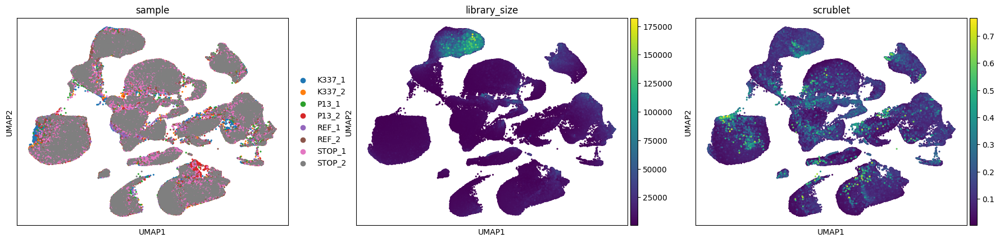

In [62]:
sc.pl.umap(adata, color=['sample', 'library_size', 'scrublet'], s=20)

In [63]:
adata.obs['log_library_size'] = np.log10(adata.obs['library_size'])
adata.obs['log_reads'] = np.log10(adata.obs['totReads'])

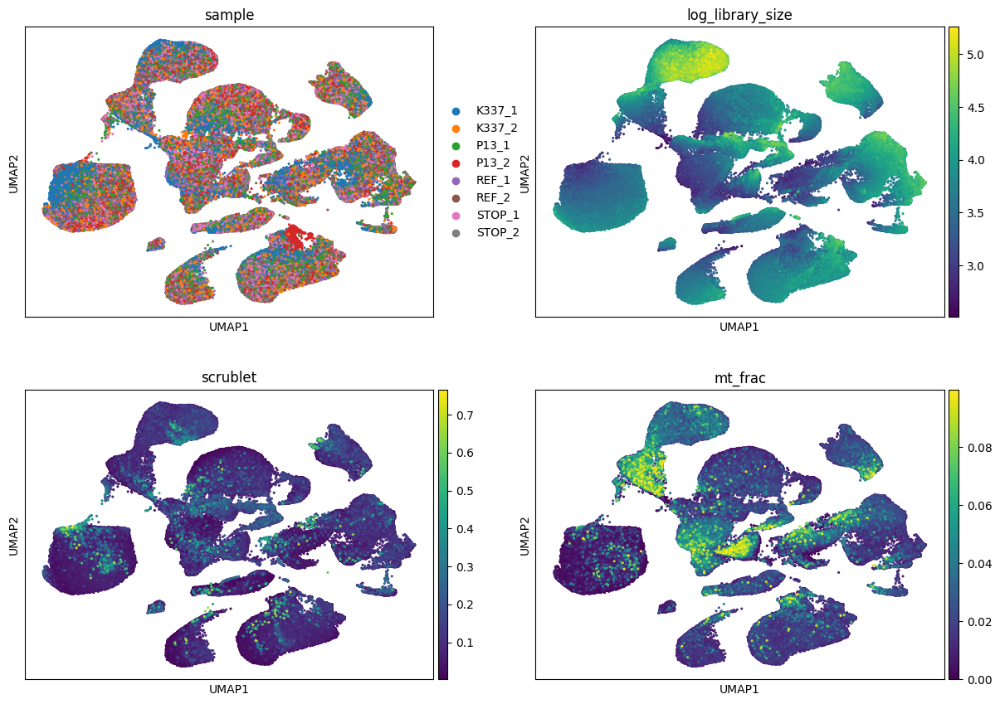

In [64]:
randidx = random.sample(list(adata.obs.index), adata.shape[0])
sc.pl.umap(adata[randidx], color=['sample', 'log_library_size', 'scrublet', 'mt_frac'], s=20, ncols=2)

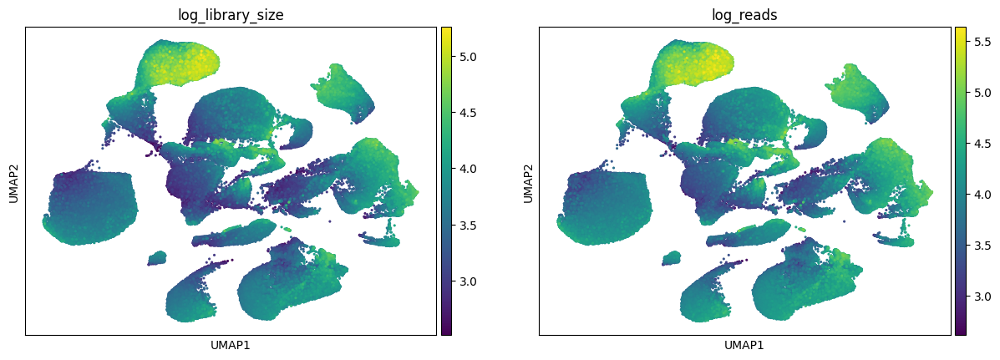

In [65]:
sc.pl.umap(adata, color=['log_library_size', 'log_reads'], s=20)

In [66]:
sum(adata.obs['cellAssign_0.8'] == 'PNEC')

1254

## Cell type refinement

Credit to Ethan Earlie for most of the code in this section

In [67]:
output_dir='celltype_refinement_plots'
!mkdir -p {output_dir}

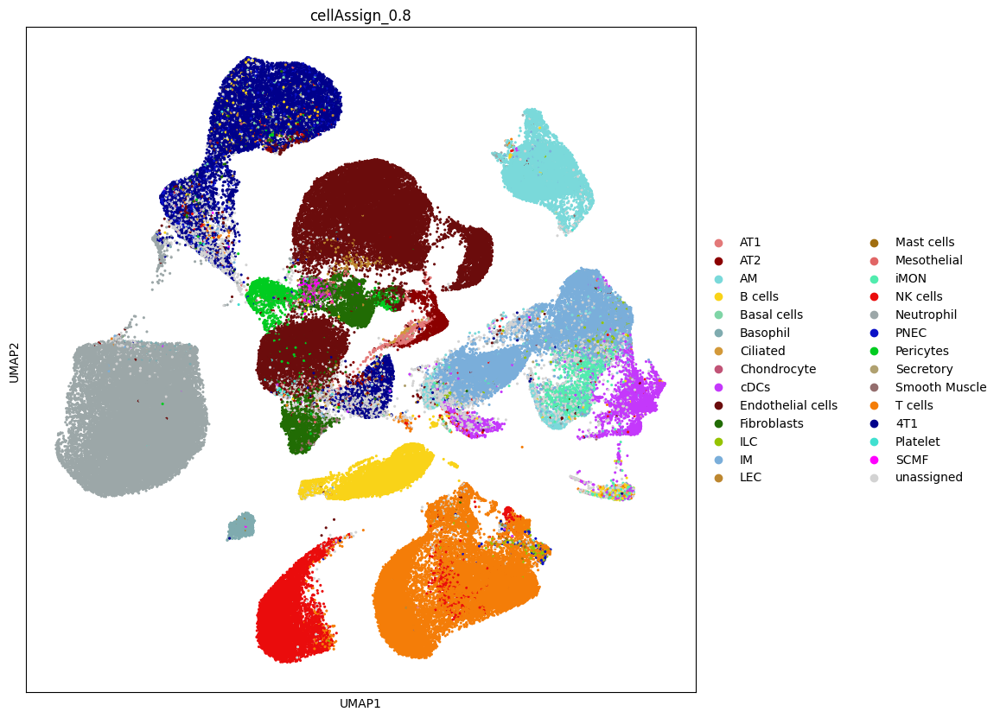

In [68]:
fig, ax = plt.subplots(figsize=(10,10))
sc.pl.umap(adata, color='cellAssign_0.8', s=20, ax= ax)

In [69]:
adata

AnnData object with n_obs × n_vars = 149323 × 32245
    obs: 'sample', 'library_size', 'mt_frac', 'totReads', 'cellAssign_0.8', 'cellAssign_maxprob', 'scrublet', 'scDbl_score', 'scDbl_class', 'log_library_size', 'log_reads'
    var: 'gene_ids', 'feature_types', 'genome', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'log1p', 'cellAssign_0.8_colors', 'hvg', 'pca', 'neighbors', 'umap', 'sample_colors'
    obsm: 'X_pca', 'X_umap', 'X_umap_this_session'
    varm: 'PCs'
    layers: 'read_matrix', 'X_orig', 'X', 'logX'
    obsp: 'distances', 'connectivities'

In [70]:
cluster_col='leiden_r1.5'
celltype_col='cellAssign_0.8'

In [71]:
# for reproducibility, read leiden groups from stored values. THey were computed with:
# ! pip3 install leidenalg
# sc.tl.leiden(adata, resolution=1.5, key_added='leiden_r1.5')

adata.obs[cluster_col] = pd.read_csv(f'data/adata_{cluster_col}.txt', sep='\t', index_col=0)
adata.obs[cluster_col] = pd.Categorical(adata.obs[cluster_col].astype(str), categories=[str(i) for i in np.arange(0, np.max(adata.obs[cluster_col])+1)])

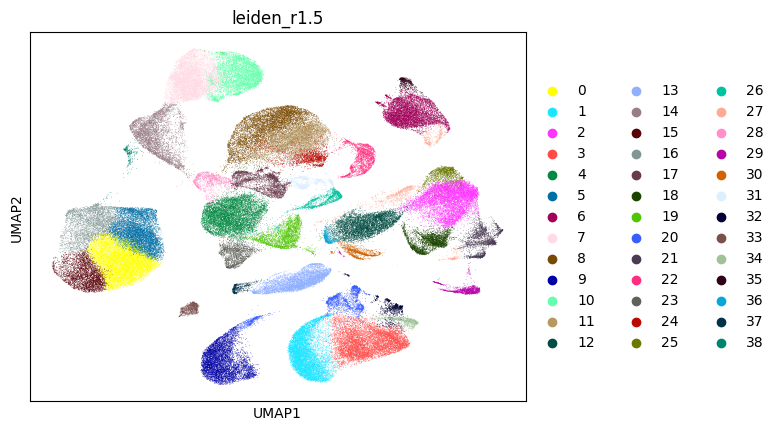

In [72]:
sc.pl.umap(adata, color=cluster_col)

In [73]:
frac_unassigned_dict2 = {}

for cluster in sorted(adata.obs[cluster_col].unique()):
    
    tmp = adata[adata.obs[cluster_col] == cluster,:].copy()
    frac_unassigned_dict2[cluster] = tmp.obs[celltype_col].value_counts(normalize=True).reindex(adata.obs[celltype_col].unique(), 
                                                                                                     fill_value=0)['unassigned']
    
adata.obs['frac_unassigned'] = adata.obs[cluster_col].map(frac_unassigned_dict2)

celltype_refinement_plots/frac_Unassigned_vs_mtFrac_mixed_wnn_leiden_log_library_size.png


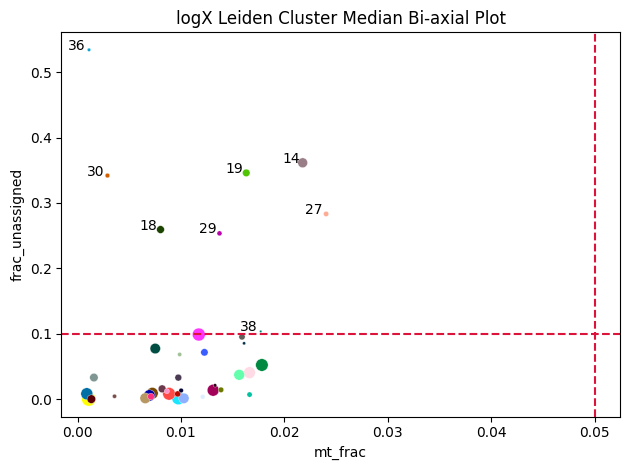

In [74]:
matplotlib.style.use('default')
fig, ax = plt.subplots()

df = adata.obs[[cluster_col, 'mt_frac']].groupby(cluster_col, observed=False).median().reset_index().copy()
df['frac_unassigned'] = df[cluster_col].map(frac_unassigned_dict2)
df = df.set_index(cluster_col).loc[adata.obs[cluster_col].value_counts().index,:]

x_thr=0.05
y_thr=0.1

sns.scatterplot(data=df,
                x='mt_frac', y='frac_unassigned', 
                hue=cluster_col,
                palette=list(adata.uns[f'{cluster_col}_colors']),
                s=0.01*adata.obs[cluster_col].value_counts().values,
                legend=None)

label = [x if ((df.loc[x,:]['mt_frac'] > x_thr) or (df.loc[x,:]['frac_unassigned'] > y_thr))
         else ''
         for x in df.index]

for i, txt in enumerate(label):
    tmp_pheno = df.index[i]
    ax.annotate(txt, (df.loc[tmp_pheno,:]['mt_frac']-0.002, 
                      df.loc[tmp_pheno,:]['frac_unassigned']))

plt.axvline(x_thr, color='crimson', linestyle='--')
plt.axhline(y_thr, color='crimson', linestyle='--')

plt.title('logX Leiden Cluster Median Bi-axial Plot')

fn = output_dir + '/frac_Unassigned_vs_mtFrac_mixed_wnn_leiden_log_library_size.png'
plt.tight_layout()

plt.gca().invert_yaxis()

print(fn)
plt.savefig(fn, dpi=400)

celltype_refinement_plots/frac_Unassigned_vs_log_library_size_mixed_wnn_leiden_log_library_size.png


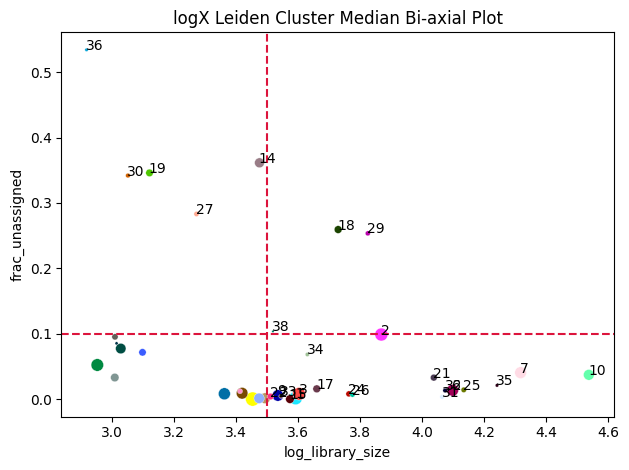

In [75]:
matplotlib.style.use('default')
fig, ax = plt.subplots()

df = adata.obs[[cluster_col, 'log_library_size']].groupby(cluster_col, observed=False).median().reset_index().copy()
df['frac_unassigned'] = df[cluster_col].map(frac_unassigned_dict2)
df = df.set_index(cluster_col).loc[adata.obs[cluster_col].value_counts().index,:]

x_thr=3.5
y_thr=0.1

sns.scatterplot(data=df,
                x='log_library_size', y='frac_unassigned', 
                hue=cluster_col,
                palette=list(adata.uns[f'{cluster_col}_colors']),
                s=0.01*adata.obs[cluster_col].value_counts().values,
                legend=None)

label = [x if ((df.loc[x,:]['log_library_size'] > x_thr) or (df.loc[x,:]['frac_unassigned'] > y_thr))
         else ''
         for x in df.index]

for i, txt in enumerate(label):
    tmp_pheno = df.index[i]
    ax.annotate(txt, (df.loc[tmp_pheno,:]['log_library_size']-0.002, 
                      df.loc[tmp_pheno,:]['frac_unassigned']))

plt.axvline(x_thr, color='crimson', linestyle='--')
plt.axhline(y_thr, color='crimson', linestyle='--')

plt.title('logX Leiden Cluster Median Bi-axial Plot')

fn = output_dir + '/frac_Unassigned_vs_log_library_size_mixed_wnn_leiden_log_library_size.png'
plt.tight_layout()

plt.gca().invert_yaxis()

print(fn)
plt.savefig(fn, dpi=400)

In [76]:
f = adata.obs[cluster_col]  == '36'
print(sum(f))
print(adata.obs.loc[f,celltype_col].astype(str).value_counts(normalize=True).iloc[:10])
print(adata.obs.loc[f,'sample'].astype(str).value_counts(normalize=True).iloc[:5])

614
cellAssign_0.8
unassigned           0.534202
AM                   0.400651
Endothelial cells    0.021173
4T1                  0.011401
IM                   0.006515
NK cells             0.004886
iMON                 0.004886
Fibroblasts          0.003257
Neutrophil           0.003257
B cells              0.003257
Name: proportion, dtype: float64
sample
P13_1     0.254072
STOP_2    0.164495
REF_2     0.153094
K337_2    0.112378
K337_1    0.089577
Name: proportion, dtype: float64


In [77]:
adata.obs

,sample,library_size,mt_frac,totReads,cellAssign_0.8,cellAssign_maxprob,scrublet,scDbl_score,scDbl_class,log_library_size,log_reads,leiden_r1.5,frac_unassigned
AAACCATTCAGCATAT-K337_1,K337_1,451.0,0.015521,655,Endothelial cells,1.000000,0.026312,0.000378,singlet,2.654176,2.816241,4,0.052199
AAACCATTCCAGCTCC-K337_1,K337_1,2314.0,0.003025,3485,Secretory,0.994072,0.021566,0.000072,singlet,3.364363,3.542203,30,0.341873
AAACCATTCCATATCC-K337_1,K337_1,755.0,0.009272,1297,Neutrophil,1.000000,0.296875,0.000331,singlet,2.877947,3.112940,16,0.033006
AAACCATTCGTCTCAT-K337_1,K337_1,468.0,0.017094,702,unassigned,0.464838,0.087405,0.000328,singlet,2.670246,2.846337,4,0.052199
AAACCATTCTAGGCCG-K337_1,K337_1,1864.0,0.008584,2761,T cells,1.000000,0.022791,0.000134,singlet,3.270446,3.441066,1,0.001555
...,...,...,...,...,...,...,...,...,...,...,...,...,...
TGTGTTAGTTGCGGTC-STOP_2,STOP_2,3072.0,0.000651,8243,Basophil,1.000000,0.021053,0.000201,singlet,3.487421,3.916085,33,0.004367
TGTGTTAGTTTGACGT-STOP_2,STOP_2,1865.0,0.000000,4801,Neutrophil,1.000000,0.019224,0.000139,singlet,3.270679,3.681332,5,0.008170
TGTGTTGAGAAGCGGC-STOP_2,STOP_2,3020.0,0.004636,8519,Endothelial cells,1.000000,0.026896,0.000040,singlet,3.480007,3.930389,11,0.001371
TGTGTTGAGGATTGAA-STOP_2,STOP_2,3566.0,0.008974,9554,T cells,1.000000,0.046673,0.000138,singlet,3.552181,3.980185,3,0.008153


celltype_refinement_plots/scrublet_score_vs_log_library_size_mixed_wnn_leiden_log_library_size.png


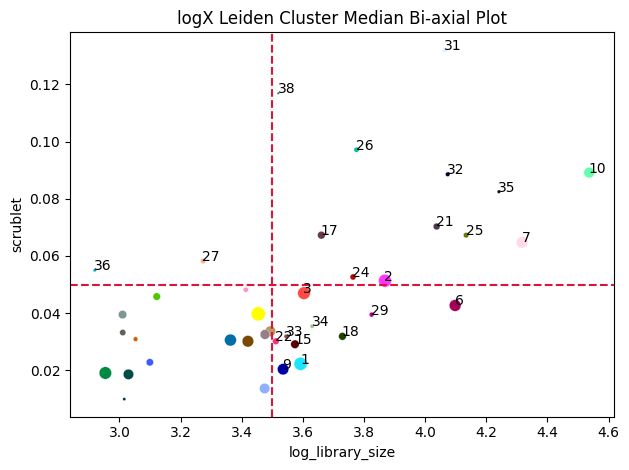

In [78]:
matplotlib.style.use('default')

fig, ax = plt.subplots()

doublet_column='scrublet'

df = adata.obs[[cluster_col, doublet_column, 'log_library_size']].groupby(cluster_col, observed=False).median().reset_index().copy()
df['frac_unassigned'] = df[cluster_col].map(frac_unassigned_dict2)
df = df.set_index(cluster_col).loc[adata.obs[cluster_col].value_counts().index,:]

x_thr=3.5
y_thr=0.05

sns.scatterplot(data=df,
                x='log_library_size', y=doublet_column, 
                hue=cluster_col,
                palette=list(adata.uns[f'{cluster_col}_colors']),
                s=0.01*adata.obs[cluster_col].value_counts().values,
                legend=None)

clabel = [x if ((df.loc[x,:]['log_library_size'] > x_thr) or (df.loc[x,:][doublet_column] > y_thr))
         else ''
         for x in df.index]

for i, txt in enumerate(clabel):
    tmp_pheno = df.index[i]
    ax.annotate(txt, (df.loc[tmp_pheno,:]['log_library_size']-0.002, 
                      df.loc[tmp_pheno,:][doublet_column]))

plt.axvline(x_thr, color='crimson', linestyle='--')
plt.axhline(y_thr, color='crimson', linestyle='--')

plt.title('logX Leiden Cluster Median Bi-axial Plot')

fn = f'{output_dir}/{doublet_column}_score_vs_log_library_size_mixed_wnn_leiden_log_library_size.png'
plt.tight_layout()

#plt.gca().invert_yaxis()

print(fn)
plt.savefig(fn, dpi=400)

In [79]:
f = adata.obs[cluster_col]  == '10'
print(sum(f))
adata.obs.loc[f,celltype_col].astype(str).value_counts(normalize=True).iloc[:5]

5922


cellAssign_0.8
4T1                  0.813408
PNEC                 0.051841
unassigned           0.037150
Endothelial cells    0.028875
Neutrophil           0.012834
Name: proportion, dtype: float64

In [80]:
f = adata.obs[cluster_col]  == '31'
print(sum(f))
adata.obs.loc[f,celltype_col].astype(str).value_counts(normalize=True).iloc[:5]

1129


cellAssign_0.8
Endothelial cells    0.372896
AT2                  0.324181
Pericytes            0.155890
Fibroblasts          0.108946
AT1                  0.030115
Name: proportion, dtype: float64

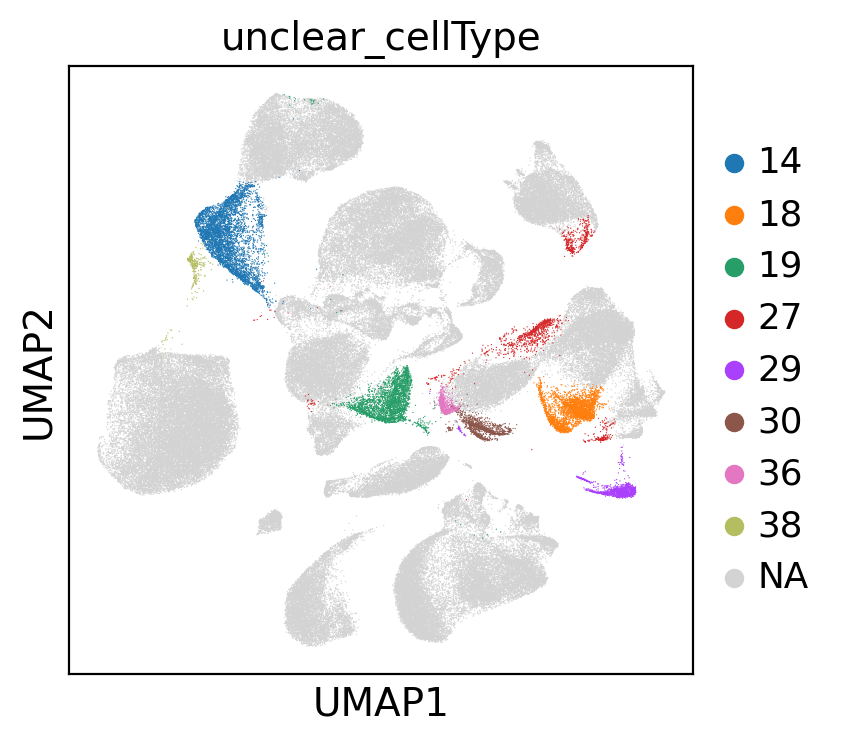

In [81]:
df = adata.obs[[cluster_col]].groupby(cluster_col, observed=False).median().reset_index().copy()
df['frac_unassigned'] = df[cluster_col].map(frac_unassigned_dict2)
df = df.set_index(cluster_col).loc[adata.obs[cluster_col].value_counts().index,:]

tmp = [str(x) for x in df.index if df.loc[x,:]['frac_unassigned'] > 0.1]

adata.obs['unclear_cellType'] = [x if x in tmp else np.nan for x in adata.obs[cluster_col].values]

sc.settings.verbosity = 4
sc.set_figure_params(dpi=100, dpi_save=300)

sc.pl.umap(adata, color='unclear_cellType', save='_unclear_cellType.png')

### Merge Unassigned Cells

#### Raw cellaAssign results

In [82]:
cluster_col

'leiden_r1.5'

In [83]:
# Cluster var defined above

shannonD = lambda x: np.nansum(-x*np.log(x))

cluster_shannon_dict = {}

for cluster in sorted(adata.obs[cluster_col].unique()):
    
    print(f'Cluster {cluster}')
    
    print(adata[adata.obs[cluster_col] == cluster,:].obs[celltype_col].value_counts(normalize=True))
    
    tmp = shannonD(adata[adata.obs[cluster_col] == cluster,:].obs[celltype_col].value_counts(normalize=True).values)
    
    cluster_shannon_dict[cluster] = tmp
    
    print('--------------------', '\n')

Cluster 0
cellAssign_0.8
Neutrophil    0.999612
AT2           0.000097
Basophil      0.000097
Platelet      0.000097
unassigned    0.000097
Name: proportion, dtype: float64
-------------------- 

Cluster 1
cellAssign_0.8
T cells          0.996890
unassigned       0.001555
B cells          0.000444
NK cells         0.000444
LEC              0.000222
AT1              0.000111
Neutrophil       0.000111
Smooth Muscle    0.000111
4T1              0.000111
Name: proportion, dtype: float64
-------------------- 

Cluster 10
cellAssign_0.8
4T1                  0.813408
PNEC                 0.051841
unassigned           0.037150
Endothelial cells    0.028875
Neutrophil           0.012834
Basal cells          0.009963
AT2                  0.007261
B cells              0.006754
Fibroblasts          0.006586
LEC                  0.006079
IM                   0.003715
T cells              0.003208
Pericytes            0.002871
NK cells             0.002026
AT1                  0.001689
Basophil     

In [84]:
cluster_shannon_dict.values()

dict_values([0.003973451760116964, 0.025931235493893912, 0.9022542168711933, 0.017034566980869845, 0.43897972916919575, 0.020866986017227834, 1.3682191320919794, 0.0, 0.23585174914985574, 0.8578339038462637, 1.4884204511898997, 1.2209044357320717, 0.9266036478199497, 0.8347091754984604, 0.3566634003015363, 0.04062751519607402, 0.7411869678044397, 0.26432174772294564, 0.26420194961723625, 0.9312883334478372, 1.5661807536889685, 0.36888058380640293, 1.7273886577129707, 0.2856502829698505, 1.1241324076799388, 1.4179685615011783, 0.7461509105019333, 0.18716349873583188, 1.286036592969408, 0.26585063484699695, 1.0166049145647393, 0.4070484298973494, 0.918037041350275, 0.5378271660949626, 0.12221387590512568, 0.23090607482327483, 0.8388625494040252, 0.08677351446789722, 0.13873317108981473])

celltype_refinement_plots/CellType_Fraction_cutoff.png
celltype_refinement_plots/Cluster_CellType_ShannonD_cutoff.png


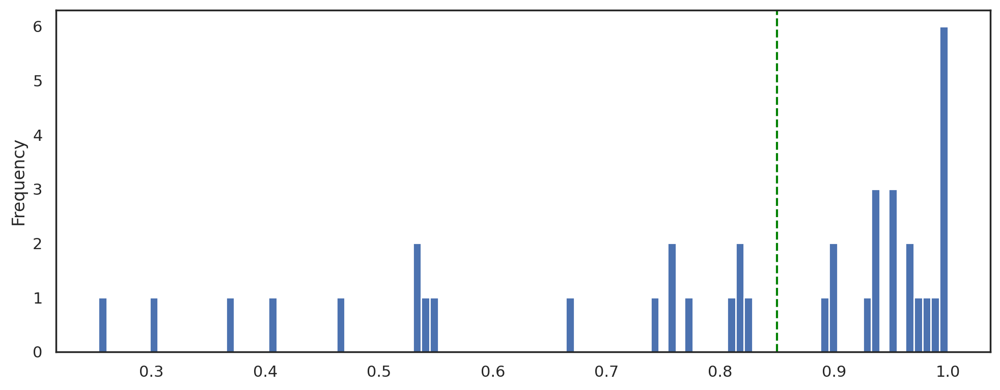

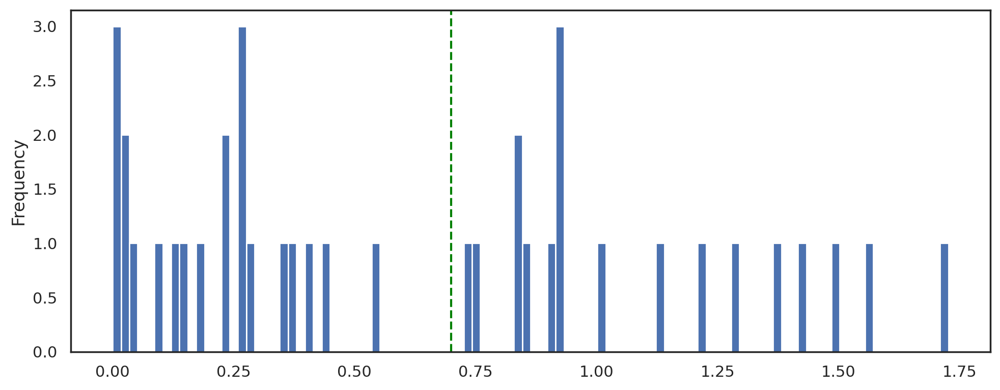

In [85]:
sns.set(style='white')

max_assignment_list = []

cluster_list = [str(x) for x in sorted([int(x) for x in adata.obs[cluster_col].unique()])]

for cluster in cluster_list:
    max_assignment_list.append(adata[adata.obs[cluster_col] == cluster].obs[celltype_col].value_counts(normalize=True).iloc[0])

fig, ax = plt.subplots(figsize=(10,4))

x_thr = 0.85
y_thr = 0.7

plt.hist(max_assignment_list, bins=100, edgecolor='white')
plt.axvline(x_thr, color='green', linestyle='--')

plt.ylabel('Frequency')

fn = output_dir + '/CellType_Fraction_cutoff.png'
plt.tight_layout()

print(fn)
plt.savefig(fn, dpi=400)

fig, ax = plt.subplots(figsize=(10,4))

plt.hist(cluster_shannon_dict.values(), bins=100, edgecolor='white')
plt.axvline(y_thr, color='green', linestyle='--')

plt.ylabel('Frequency')

fn = output_dir + '/Cluster_CellType_ShannonD_cutoff.png'
plt.tight_layout()

print(fn)
plt.savefig(fn, dpi=400)

i = 2 | max_prob = 0.76005 | SDI = 0.9266
i = 7 | max_prob = 0.82333 | SDI = 0.83886
i = 10 | max_prob = 0.81341 | SDI = 0.90225
i = 14 | max_prob = 0.46915 | SDI = 1.36822
i = 17 | max_prob = 0.77407 | SDI = 0.85783
i = 18 | max_prob = 0.4079 | SDI = 1.48842
i = 19 | max_prob = 0.5462 | SDI = 1.2209
i = 20 | max_prob = 0.74392 | SDI = 0.83471
i = 23 | max_prob = 0.81904 | SDI = 0.74119
i = 26 | max_prob = 0.6662 | SDI = 0.93129
i = 27 | max_prob = 0.30376 | SDI = 1.56618
i = 29 | max_prob = 0.25347 | SDI = 1.72739
i = 30 | max_prob = 0.54064 | SDI = 1.12413
i = 31 | max_prob = 0.3729 | SDI = 1.41797
i = 32 | max_prob = 0.8115 | SDI = 0.74615
i = 34 | max_prob = 0.53304 | SDI = 1.28604
i = 36 | max_prob = 0.5342 | SDI = 1.0166
i = 38 | max_prob = 0.76052 | SDI = 0.91804

celltype_refinement_plots/SDI_by_Max_Fraction_per_Cluster.png


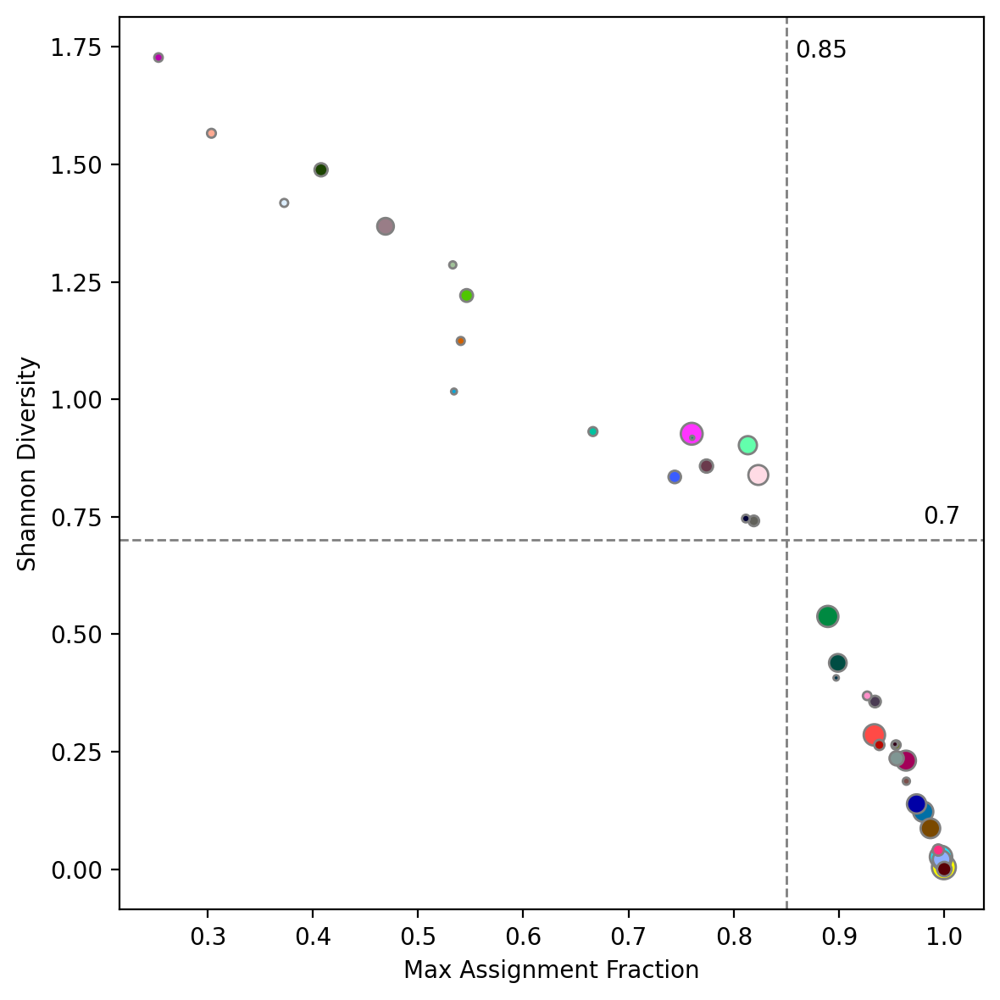

In [86]:
cluster_list = [str(x) for x in sorted([int(x) for x in adata.obs[cluster_col].unique()])]

x = max_assignment_list
y = [cluster_shannon_dict[x] for x in cluster_list]

ambig_clusters_uncorr = []

for i in range(len(x)):
    if ((x[i] < x_thr) & (y[i] > y_thr)):
        print(f'i = {cluster_list[i]} | max_prob = {round(x[i], 5)} | SDI = {round(y[i],5)}')
        ambig_clusters_uncorr.append(cluster_list[i])

print()
        
matplotlib.style.use('default')

fig, ax = plt.subplots(figsize=(6,6))

plt.scatter(x, y, 
            c=adata.uns[f'{cluster_col}_colors'], 
            s=0.01*adata.obs[cluster_col].value_counts().values,
            edgecolors='grey')

plt.axvline(x_thr, color='grey', linestyle='--', linewidth=1)
plt.axhline(y_thr, color='grey', linestyle='--', linewidth=1)

plt.text(0.98, y_thr*1.05, f'{y_thr}')
plt.text(x_thr*1.01, max(y), f'{x_thr}')

plt.xlabel('Max Assignment Fraction')
plt.ylabel('Shannon Diversity')

fn = output_dir + '/SDI_by_Max_Fraction_per_Cluster.png'
plt.tight_layout()

print(fn)
plt.savefig(fn, dpi=400)

In [87]:
len(ambig_clusters_uncorr)

18

In [88]:
len(adata.obs[cluster_col].cat.categories)

39

celltype_refinement_plots/cellAssign_0.8_Fraction_by_Cluster_Linear.png





In [89]:
n_cols=5

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    
    sns.set(font_scale=0.5, style='whitegrid')

    n_rows = len(cluster_list) // ncols
    
    if len(cluster_list) % 5 != 0:
        n_rows += 1
        
    fig, axs = plt.subplots(n_rows, ncols, figsize=(n_cols*3,n_rows*2.5))
    
    for i, ax in enumerate(fig.axes):
        
        if i < len(cluster_list):
            cluster = cluster_list[i]
            cluster_size = adata.obs[cluster_col].value_counts()[cluster]
            tmp = pd.DataFrame(adata[adata.obs[cluster_col] == cluster,:].obs[celltype_col].value_counts(normalize=True).reset_index())
            tmp = tmp.sort_values(by=celltype_col, ascending=True)
            
            sns.barplot(data=tmp,
                        x=celltype_col,
                        y='proportion',
                        hue=celltype_col,
                        palette=celltype_colors,
                        #width=0.5,
                        order=tmp[celltype_col].values.tolist(),
                        ax=ax)
            
            ax.axhline(0.05, color='red', linestyle='--')
            ax.axhline(x_thr, color='green', linestyle='--')
            ax.set_ylim([0,1.05])
            ax.legend([],[])
            ax.set_xticklabels(tmp[celltype_col].values, rotation = 90)
            ax.set_title(f'{cluster} | n = {cluster_size} | SDI = {round(cluster_shannon_dict[cluster], 4)}')
            
            if i >= (n_rows-1)*4:
                ax.set_xlabel('')
            else:
                ax.set_xlabel('')
            
        if i%4==0:
            ax.set_ylabel('Fraction')        
        else:
            ax.set_ylabel('')
        
        ax.set_yticks([])

    celltype_col_save = celltype_col.replace(' ', '_')
    
    fn = output_dir + f'/{celltype_col_save}_Fraction_by_Cluster_Linear.png'
    plt.tight_layout()
    print(fn)
    plt.savefig(fn, dpi=400)

#### Merge non-ambiguous clusters

In [90]:
len(ambig_clusters_uncorr)

18

In [91]:
cell_type_cmap = celltype_colors

In [92]:
output_dir

'celltype_refinement_plots'

In [93]:
adata.obs

,sample,library_size,mt_frac,totReads,cellAssign_0.8,cellAssign_maxprob,scrublet,scDbl_score,scDbl_class,log_library_size,log_reads,leiden_r1.5,frac_unassigned,unclear_cellType
AAACCATTCAGCATAT-K337_1,K337_1,451.0,0.015521,655,Endothelial cells,1.000000,0.026312,0.000378,singlet,2.654176,2.816241,4,0.052199,NaN
AAACCATTCCAGCTCC-K337_1,K337_1,2314.0,0.003025,3485,Secretory,0.994072,0.021566,0.000072,singlet,3.364363,3.542203,30,0.341873,30
AAACCATTCCATATCC-K337_1,K337_1,755.0,0.009272,1297,Neutrophil,1.000000,0.296875,0.000331,singlet,2.877947,3.112940,16,0.033006,NaN
AAACCATTCGTCTCAT-K337_1,K337_1,468.0,0.017094,702,unassigned,0.464838,0.087405,0.000328,singlet,2.670246,2.846337,4,0.052199,NaN
AAACCATTCTAGGCCG-K337_1,K337_1,1864.0,0.008584,2761,T cells,1.000000,0.022791,0.000134,singlet,3.270446,3.441066,1,0.001555,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TGTGTTAGTTGCGGTC-STOP_2,STOP_2,3072.0,0.000651,8243,Basophil,1.000000,0.021053,0.000201,singlet,3.487421,3.916085,33,0.004367,NaN
TGTGTTAGTTTGACGT-STOP_2,STOP_2,1865.0,0.000000,4801,Neutrophil,1.000000,0.019224,0.000139,singlet,3.270679,3.681332,5,0.008170,NaN
TGTGTTGAGAAGCGGC-STOP_2,STOP_2,3020.0,0.004636,8519,Endothelial cells,1.000000,0.026896,0.000040,singlet,3.480007,3.930389,11,0.001371,NaN
TGTGTTGAGGATTGAA-STOP_2,STOP_2,3566.0,0.008974,9554,T cells,1.000000,0.046673,0.000138,singlet,3.552181,3.980185,3,0.008153,NaN


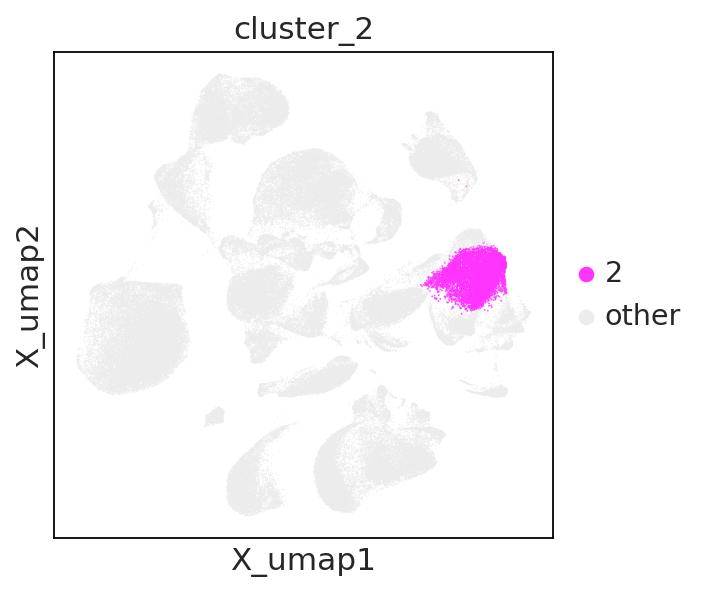

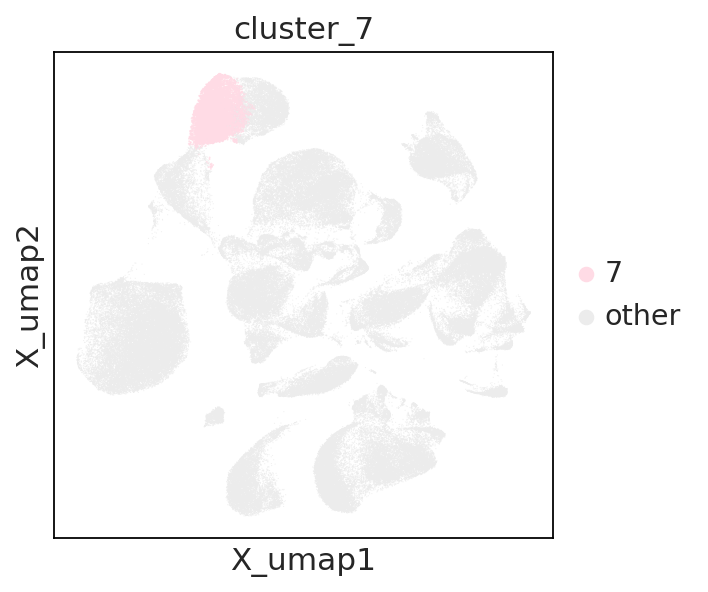

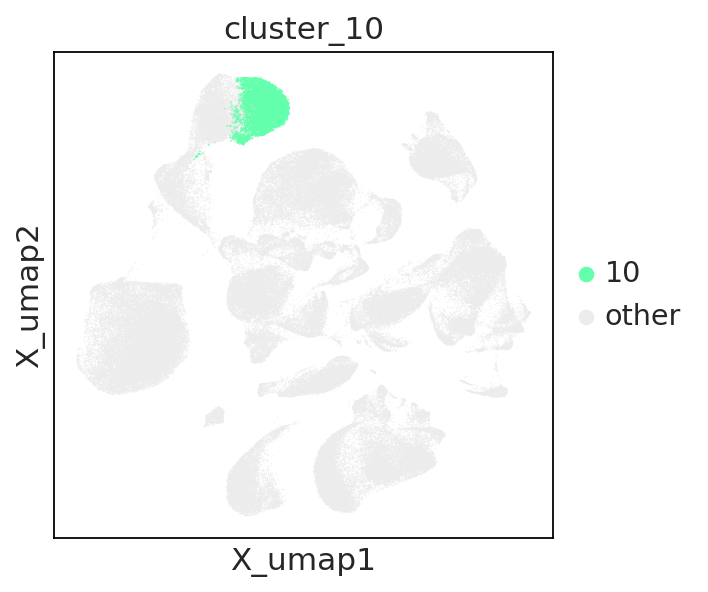

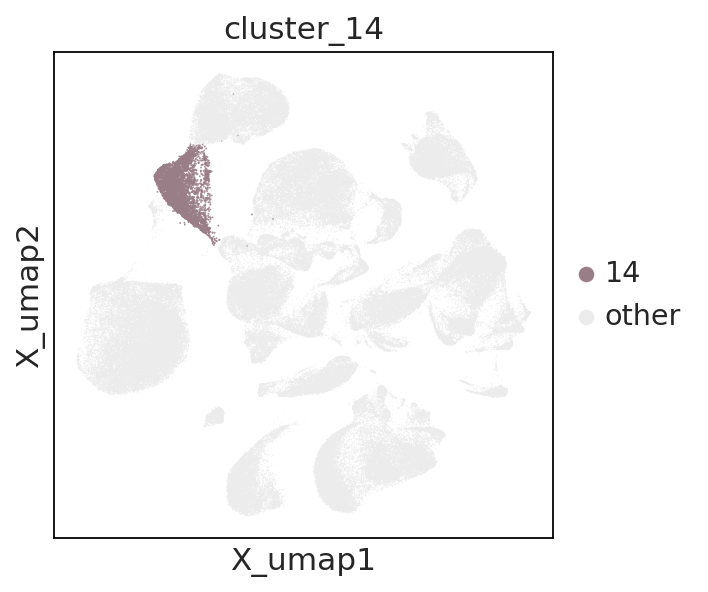

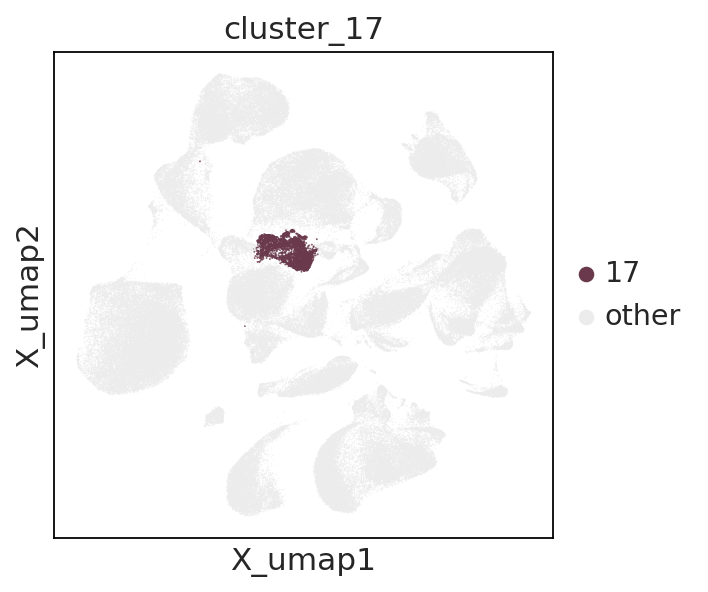

...

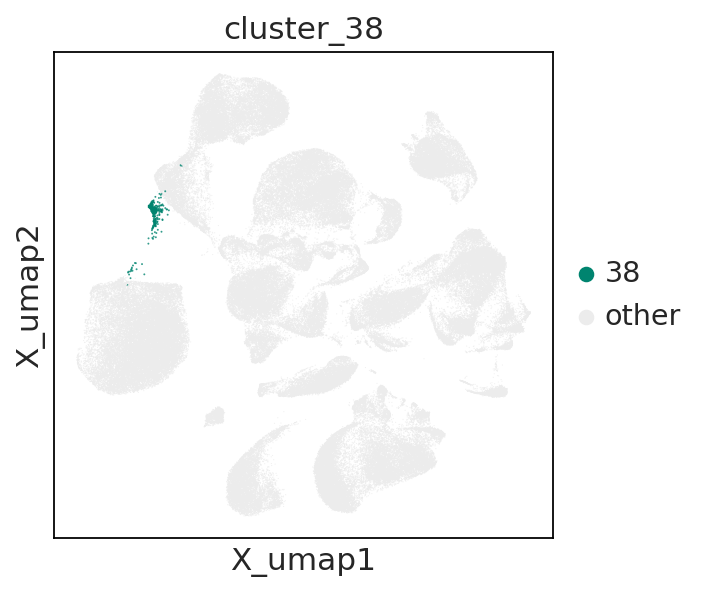

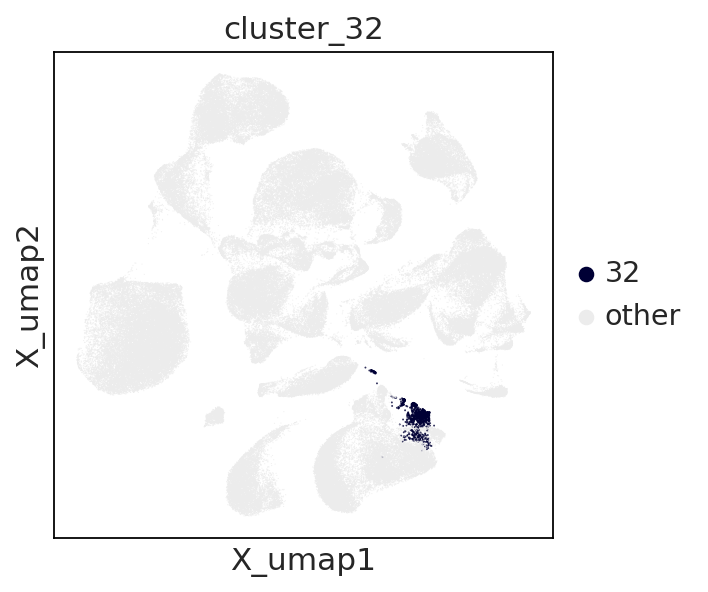

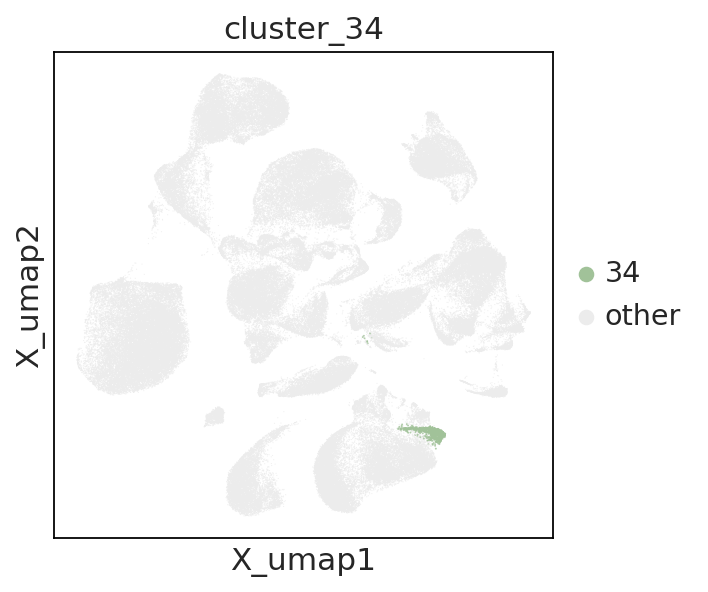

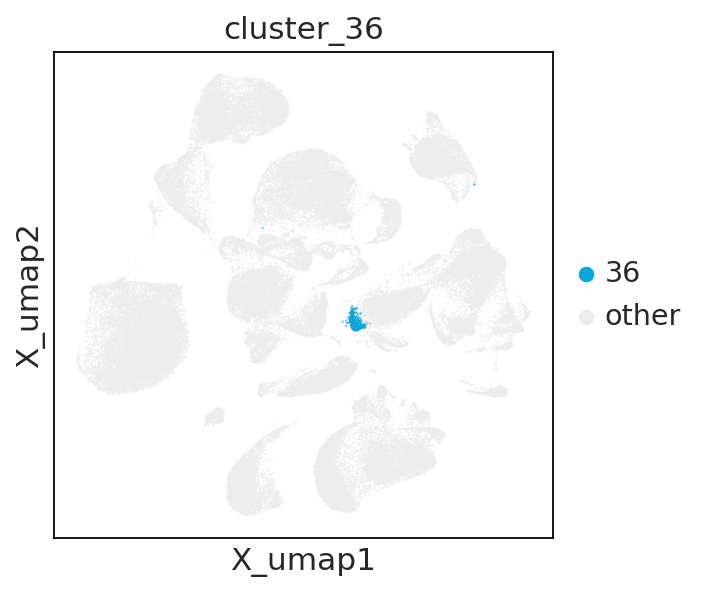

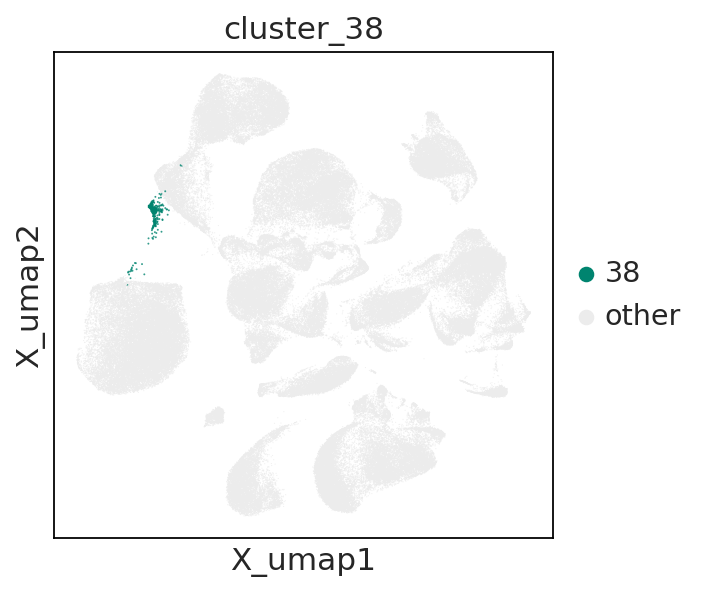

In [94]:
output_dir = os.getcwd() + '/celltype_refinement_plots/Ambiguous_Clusters'
!mkdir -p {output_dir}

sc.settings.figdir = output_dir

basis='X_umap'

cluster_cmap = dict(zip([str(x) for x in sorted([int(x) for x in adata.obs[cluster_col].unique()])],
                        adata.uns[f'{cluster_col}_colors']))
cluster_cmap['other'] = '#ECECEC'

cell_type_cmap['unassigned'] = '#000000'

sc.settings.verbosity = 4
sc.set_figure_params(dpi=80, dpi_save=300)

for c in ambig_clusters_uncorr:
    
    adata.obs[f'cluster_{c}'] = [c if x == c else 'other' for x in adata.obs[cluster_col].values]

    adata.uns[f'cluster_{c}_colors'] = [cluster_cmap[c], cluster_cmap['other']]
    
    adata.obs[f'cluster_{c}_max_prob'] = [adata.obs['cellAssign_maxprob'].values[x] 
                                               if adata.obs[cluster_col].values[x] == c else np.nan for x in range(len(adata.obs))]
    
    adata.obs[f'cluster_{c}_celltype'] = [adata.obs[celltype_col].values[x] 
                                                         if adata.obs[cluster_col].values[x] == c 
                                                         else np.nan for x in range(len(adata.obs))]
    
    adata.uns[f'cluster_{c}_celltype_colors'] = [cell_type_cmap[x] 
                                                                for x in sorted(adata[adata.obs[cluster_col]
                                                                                           == c].obs[celltype_col].unique())]
    
    
    sc.pl.embedding(adata, basis=basis, color=[f'cluster_{c}'], s=[3 if x == c else 1 for x in adata.obs[cluster_col].values], alpha=0.8,
               save=f'_cluster_{c}_corr.png')
    
    sc.pl.embedding(adata, basis=basis, color=[f'cluster_{c}_max_prob'], 
               s=[3 if x == c else 1 for x in adata.obs[cluster_col].values], 
               alpha=0.8,
               cmap='viridis', vmin=0.9, vmax=1,
               show=False,
               save=f'_cluster_{c}_max_prob.png')
    
    sc.pl.embedding(adata, basis=basis, color=[f'cluster_{c}_celltype'], 
               s=[3 if x == c else 1 for x in adata.obs[cluster_col].values], alpha=0.8,
               show=False,
               save=f'_cluster_{c}_cellAssign_results.png') 
    
    sc.pl.embedding(adata, basis=basis, color=[f'cluster_{c}_celltype'], 
               s=[3 if x == c else 1 for x in adata.obs[cluster_col].values], alpha=0.8,
               show=False,
               save=f'_cluster_{c}_cellAssign_results.png')
    
cell_type_cmap['unassigned'] = '#DEDEDE'

output_dir = os.getcwd() + '/celltype_refinement'
sc.settings.figdir = output_dir

In [95]:
for cluster in cluster_list:
    if cluster not in ambig_clusters_uncorr:
        print(cluster)

0
1
3
4
5
6
8
9
11
12
13
15
16
21
22
24
25
28
33
35
37


In [96]:
# For all non-ambiguous clusters, merge all cells to mode cell type:

index_celltype_dict = dict(zip(adata.obs.index.tolist(), adata.obs[celltype_col].values.tolist()))
update_dict = {}

for cluster in cluster_list:
    
    if cluster not in ambig_clusters_uncorr:
        # The mode should not be unassigned for a non-ambiguous cluster:
        cellType = adata[adata.obs[cluster_col] == cluster].obs[celltype_col].value_counts().index[0]
        
        tmp = dict(zip(adata[adata.obs[cluster_col] == cluster].obs.index.tolist(), 
                       [cellType for x in range(len(adata[adata.obs[cluster_col] == cluster]))]))
        update_dict.update(tmp)

# Check that only un-ambiguous clusters are being update:
if sum(adata[pd.Series(list(update_dict.keys()))].obs[cluster_col].map(lambda x: x in ambig_clusters_uncorr)) > 0:
    print('ERROR: Cells from and Ambiguous Cluster are being updated.')

# Update index-to-cellType dictionary with the cluster-to-cellType dictionary:
index_celltype_dict_1 = index_celltype_dict
index_celltype_dict_1.update(update_dict)

adata.obs['Macro Cell Type 1'] = adata.obs.index.map(index_celltype_dict_1)

adata.uns['Macro Cell Type 1_colors'] = [cell_type_cmap[x] for x in sorted(adata.obs['Macro Cell Type 1'].unique())]

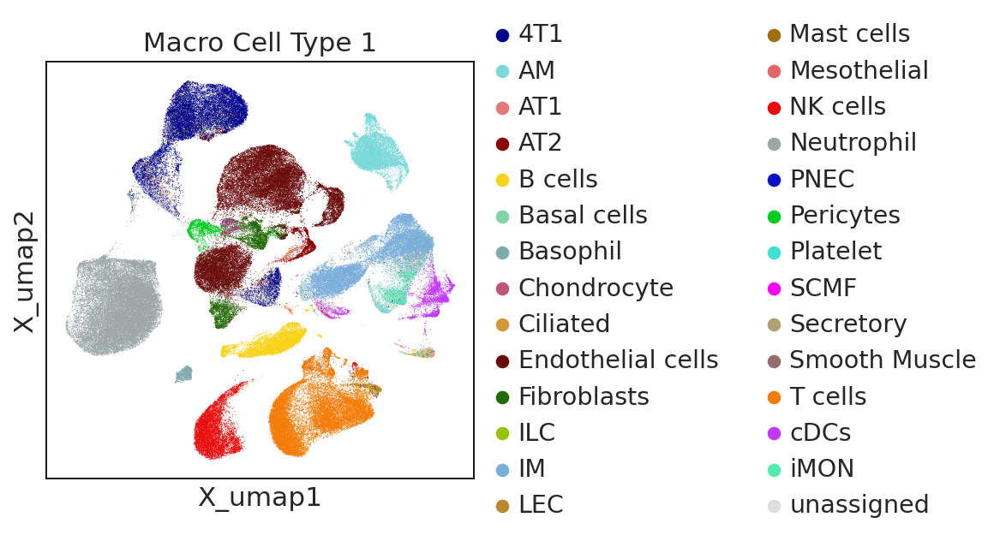

In [97]:
sc.settings.verbosity = 4
sc.set_figure_params(dpi=80, dpi_save=300)

sc.pl.embedding(adata, basis=basis, color='Macro Cell Type 1', alpha=1, save='_Macro_Cell_Type_1.png')

/data/satseq_processing/SatSeq_10x_lung_mets/celltype_refinement/Macro_Cell_Type_1_Fraction_by_Cluster_Linear.png


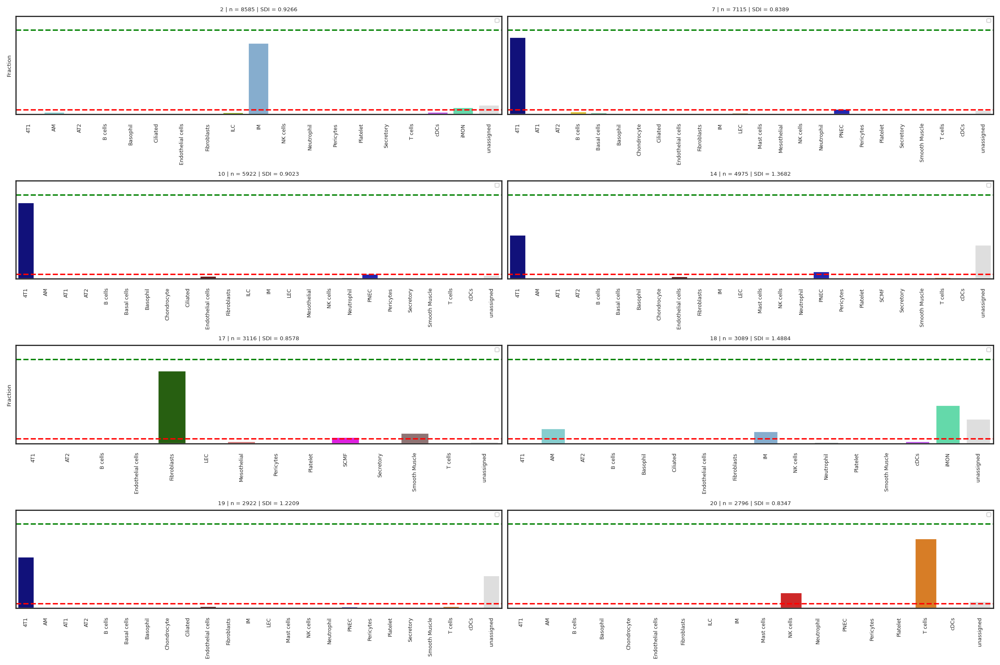

In [98]:
cellType_var = 'Macro Cell Type 1'

n_cols=5
cluster_list = ambig_clusters_uncorr

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    
    sns.set(font_scale=0.5, style='white')
    n_rows = len(cluster_list) // 5
    
    if len(cluster_list) % 5 != 0:
        n_rows += 1
        
    fig, axs = plt.subplots(n_rows, ncols, figsize=(n_cols*3,n_rows*2.5))
    for i, ax in enumerate(fig.axes):
        
        if i < len(cluster_list):
            cluster = cluster_list[i]
            
            cluster_size = adata.obs[cluster_col].value_counts()[cluster]
            
            tmp = pd.DataFrame(adata[adata.obs[cluster_col] == cluster,:].obs[cellType_var].value_counts(normalize=True).reset_index())
            tmp = tmp.sort_values(by=cellType_var, ascending=True)
            
            sns.barplot(data=tmp,
                        x=cellType_var,
                        y='proportion',
                        #color=[matplotlib.colors.to_rgb(cell_type_cmap[x]) for x in tmp['index'].values.tolist()],
                        hue=cellType_var,
                        palette=cell_type_cmap,
                        #width=0.5,
                        order=tmp[cellType_var].values.tolist(),
                        ax=ax)
            
            ax.axhline(0.05, color='red', linestyle='--')
            ax.axhline(0.9, color='green', linestyle='--')
            ax.set_ylim([0,1.05])
            
            ax.legend([],[])
            ax.set_xticklabels(tmp[cellType_var].values, rotation = 90)
            ax.set_title(f'{cluster} | n = {cluster_size} | SDI = {round(cluster_shannon_dict[cluster], 4)}')
            
            if i >= (n_rows-1)*4:
                ax.set_xlabel('')
            else:
                ax.set_xlabel('')
                
        if i%4==0:
            ax.set_ylabel('Fraction')        
        else:
            ax.set_ylabel('')
        
        ax.set_yticks([])

    cellType_var_save = cellType_var.replace(' ', '_')
    
    fn = output_dir + f'/{cellType_var_save}_Fraction_by_Cluster_Linear.png'
    plt.tight_layout()
    
    print(fn)
    plt.savefig(fn, dpi=400)

#### Type 1 - One cell type, slightly ambiguous

In [99]:
#current_clusters = ['6', '7', '10', '19', '20', '21', '22', '24', '25', '27',
#                    '30', '31', '32', '33', '34', '35', '37', '42', '43'] # note: tumor clusters are clearly tumor but have high unassigned fraction, merge

current_clusters = ['7', '10', '14', '19']

# Merge simply by cluster mode

index_celltype_dict = dict(zip(adata.obs.index.tolist(), adata.obs['Macro Cell Type 1'].values.tolist()))
update_dict = {}

for cluster in current_clusters:
    
    # The mode should not be unassigned for a non-ambiguous cluster:
    tmp = adata[adata.obs[cluster_col] == cluster].obs['Macro Cell Type 1'].value_counts()
    cellType = tmp[tmp.index!='unassigned'].index[0]
        
    tmp = dict(zip(adata[adata.obs[cluster_col] == cluster].obs.index.tolist(), 
                   [cellType for x in range(len(adata[adata.obs[cluster_col] == cluster]))]))
    
    update_dict.update(tmp)

# Check that only un-ambiguous clusters are being update:
if sum(adata[pd.Series(list(update_dict.keys()))].obs[cluster_col].map(lambda x: x not in current_clusters)) > 0:
    print('ERROR: Cells from Incorrect Cluster(s) are being updated.')

# Update index-to-cellType dictionary with the cluster-to-cellType dictionary:
index_celltype_dict_2 = index_celltype_dict
index_celltype_dict_2.update(update_dict)

adata.obs['Macro Cell Type 2'] = adata.obs.index.map(index_celltype_dict_2)

adata.uns['Macro Cell Type 2_colors'] = [cell_type_cmap[x] for x in sorted(adata.obs['Macro Cell Type 2'].unique())]

In [100]:
adata.obs['Macro Cell Type 2'].value_counts()

Macro Cell Type 2
Endothelial cells    25428
Neutrophil           25401
4T1                  21006
T cells              20853
IM                   14502
AM                    9069
NK cells              7324
B cells               6483
Fibroblasts           4196
unassigned            3654
cDCs                  3585
iMON                  2153
Pericytes             1534
AT2                   1344
Basophil               943
Smooth Muscle          441
AT1                    397
ILC                    369
SCMF                   215
PNEC                   158
Mesothelial             84
Ciliated                75
Secretory               46
Mast cells              29
Platelet                25
LEC                      6
Basal cells              2
Chondrocyte              1
Name: count, dtype: int64

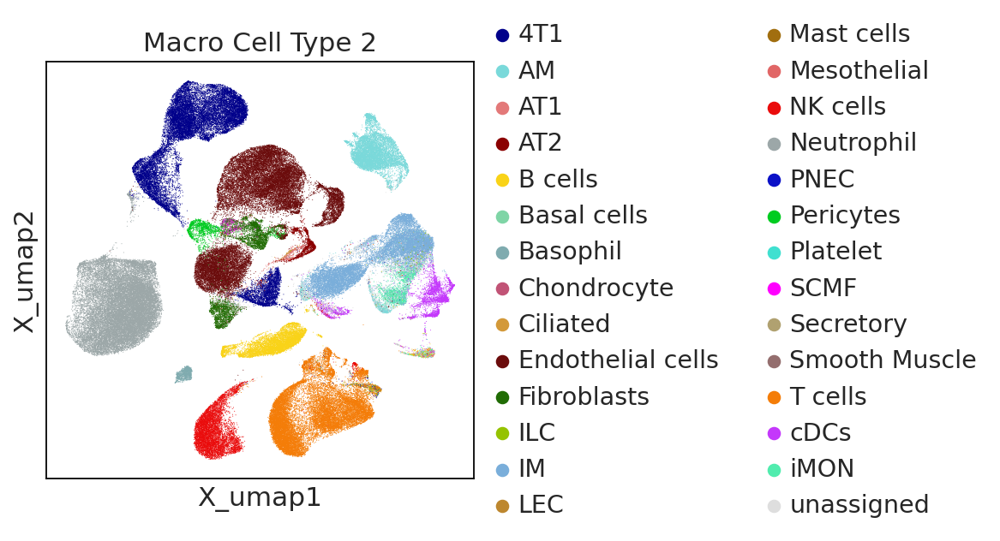

In [101]:
sc.settings.verbosity = 4
sc.set_figure_params(dpi=80, dpi_save=300)

sc.pl.embedding(adata, basis=basis, color='Macro Cell Type 2', alpha=1, save='_Macro_Cell_Type_2.png')

In [102]:
cluster_list = [x for x in cluster_list if x not in current_clusters]

/data/satseq_processing/SatSeq_10x_lung_mets/celltype_refinement/Macro_Cell_Type_2_Fraction_by_Cluster_Linear.png


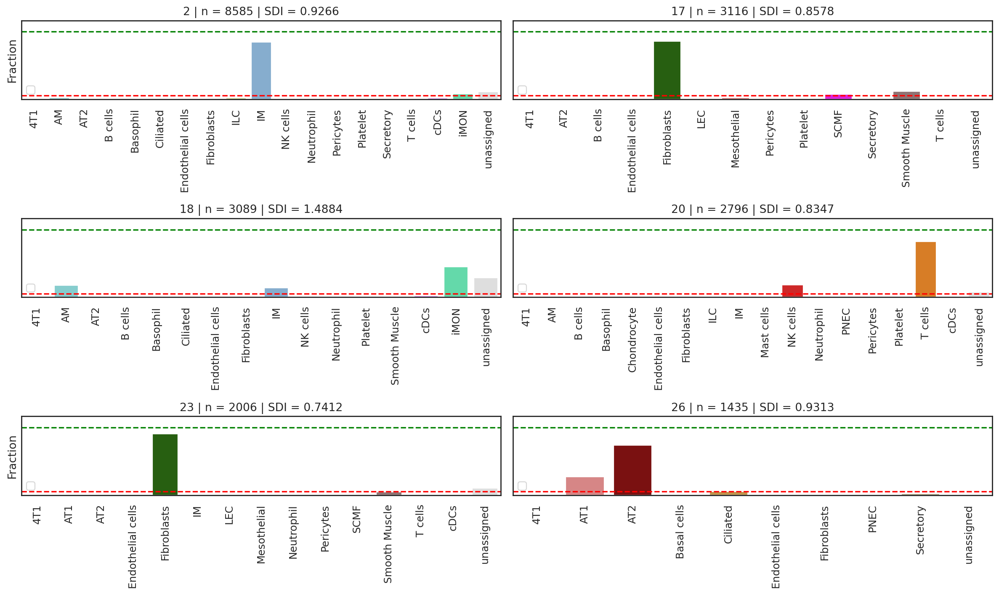

In [103]:
cellType_var = 'Macro Cell Type 2'

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    
    sns.set(font_scale=1, style='white')
    n_rows = len(cluster_list) // 5
    
    if len(cluster_list) % 5 != 0:
        n_rows += 1
        
    fig, axs = plt.subplots(n_rows, ncols, figsize=(n_cols*3,n_rows*3))
    for i, ax in enumerate(fig.axes):
        
        if i < len(cluster_list):
            cluster = cluster_list[i]
            cluster_size = adata.obs[cluster_col].value_counts()[cluster]
            
            tmp = pd.DataFrame(adata[adata.obs[cluster_col] == cluster,:].obs[cellType_var].value_counts(normalize=True).reset_index())
            tmp = tmp.sort_values(by=cellType_var, ascending=True)
            
            sns.barplot(data=tmp,
                        x=cellType_var,
                        y='proportion',
                        #color=[matplotlib.colors.to_rgb(cell_type_cmap[x]) for x in tmp['index'].values.tolist()],
                        hue=cellType_var,
                        palette=cell_type_cmap,
                        #width=0.5,
                        order=tmp[cellType_var].values.tolist(),
                        ax=ax)
            
            ax.axhline(0.05, color='red', linestyle='--')
            ax.axhline(0.9, color='green', linestyle='--')
            ax.set_ylim([0,1.05])
            ax.legend([],[])
            
            ax.set_xticklabels(tmp[cellType_var].values, rotation = 90)
            ax.set_title(f'{cluster} | n = {cluster_size} | SDI = {round(cluster_shannon_dict[cluster], 4)}')
            
            if i >= (n_rows-1)*4:
                ax.set_xlabel('')
            else:
                ax.set_xlabel('')
                
        if i%4==0:
            ax.set_ylabel('Fraction')        
        else:
            ax.set_ylabel('')
        
        ax.set_yticks([])

    cellType_var_save = cellType_var.replace(' ', '_')
    
    fn = output_dir + f'/{cellType_var_save}_Fraction_by_Cluster_Linear.png'
    plt.tight_layout()
    print(fn)
    plt.savefig(fn, dpi=400)

In [104]:
f = adata.obs['Macro Cell Type 1'] != adata.obs[celltype_col]
adata.obs.loc[f,cluster_col].astype(str).value_counts()

leiden_r1.5
4     888
12    565
3     546
6     260
9     175
16    166
21    158
5     147
24    116
28     97
8      91
25     71
37     53
33     33
35     29
1      28
13     14
22     13
11     12
0       4
Name: count, dtype: int64

In [105]:
f = adata.obs['Macro Cell Type 1'] != adata.obs['Macro Cell Type 2']
adata.obs.loc[f,cluster_col].astype(str).value_counts()

leiden_r1.5
14    2641
19    1326
7     1257
10    1105
Name: count, dtype: int64

In [106]:
sum(pd.isna(adata.obs['Macro Cell Type 1']))

0

In [107]:
sum(pd.isna(adata.obs['Macro Cell Type 2']))

0

#### Visualization of ambiguous clusters

In [108]:
len(cluster_list)

14

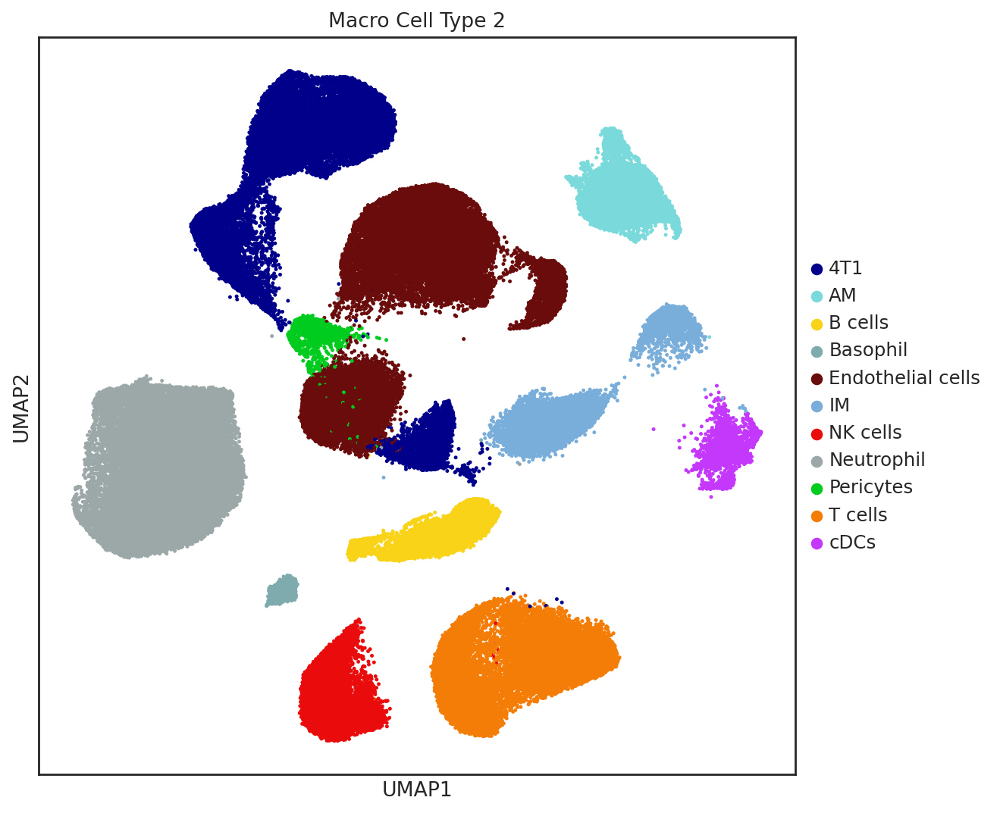

In [109]:
fig, ax = plt.subplots(figsize=(8,8))
f = ~adata.obs[cluster_col].isin(cluster_list)
sc.pl.umap(adata[f], color='Macro Cell Type 2', s=20, ax=ax)

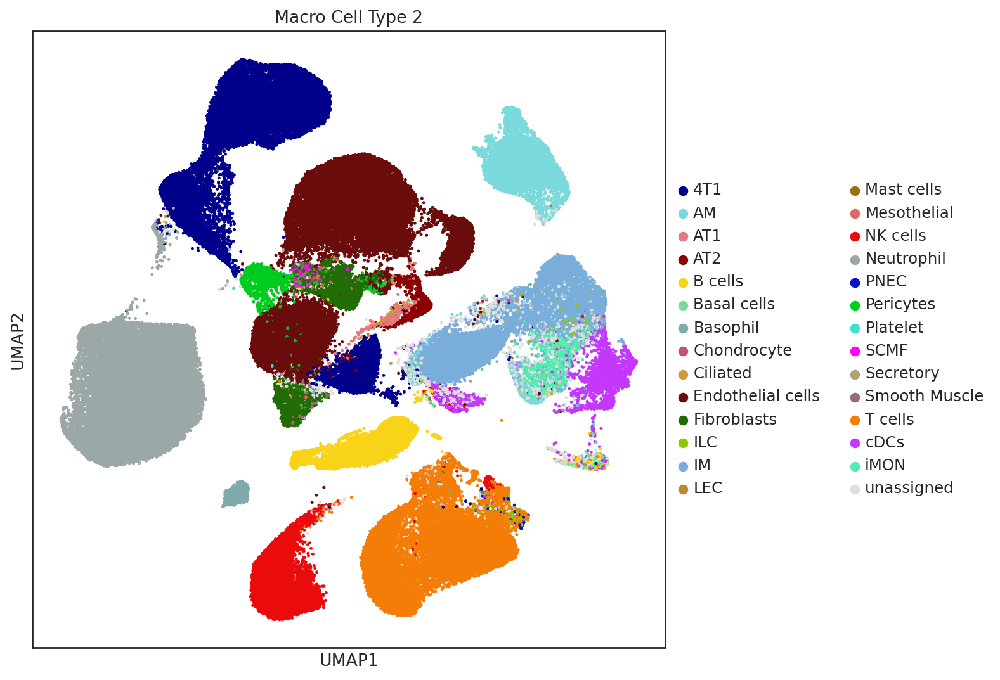

In [110]:
fig, ax = plt.subplots(figsize=(8,8))

sc.pl.umap(adata, color='Macro Cell Type 2', s=20, ax=ax)

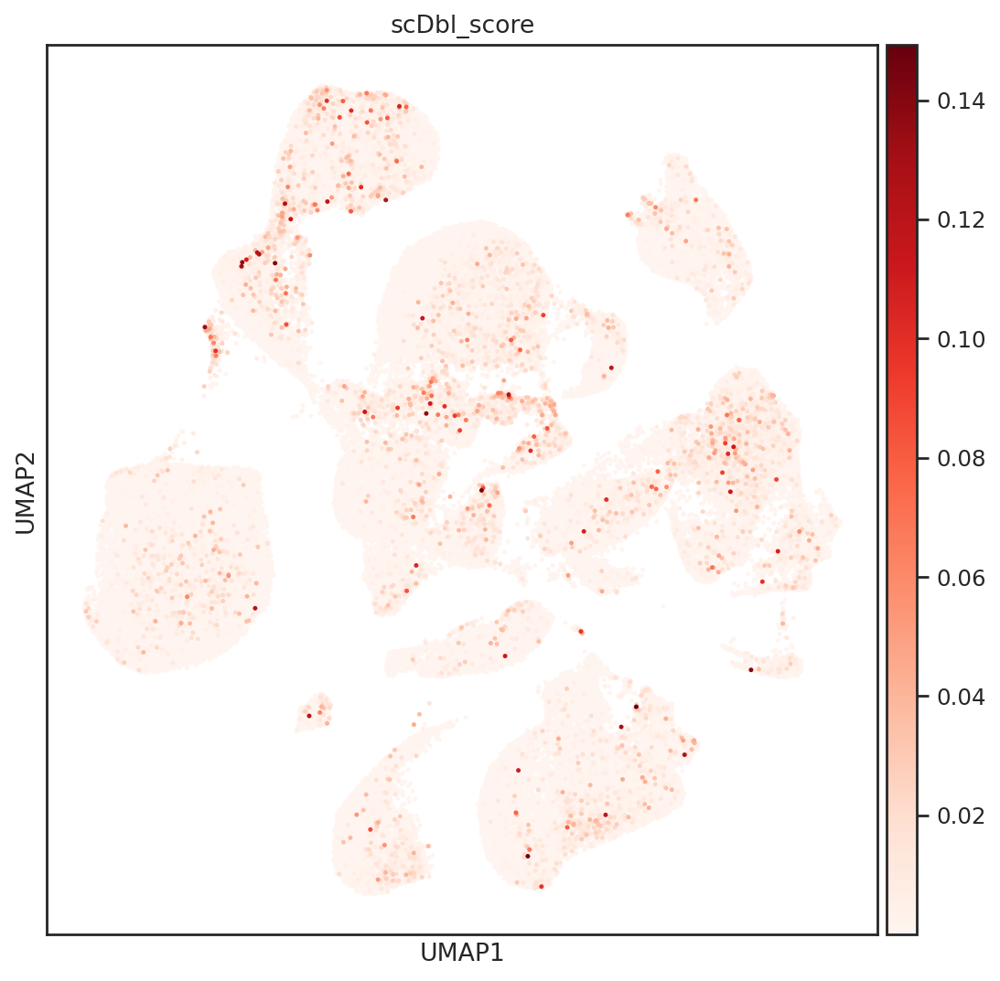

In [111]:
fig, ax = plt.subplots(figsize=(8,8))

sc.pl.umap(adata, color='scDbl_score',s=20, ax=ax, cmap='Reds')

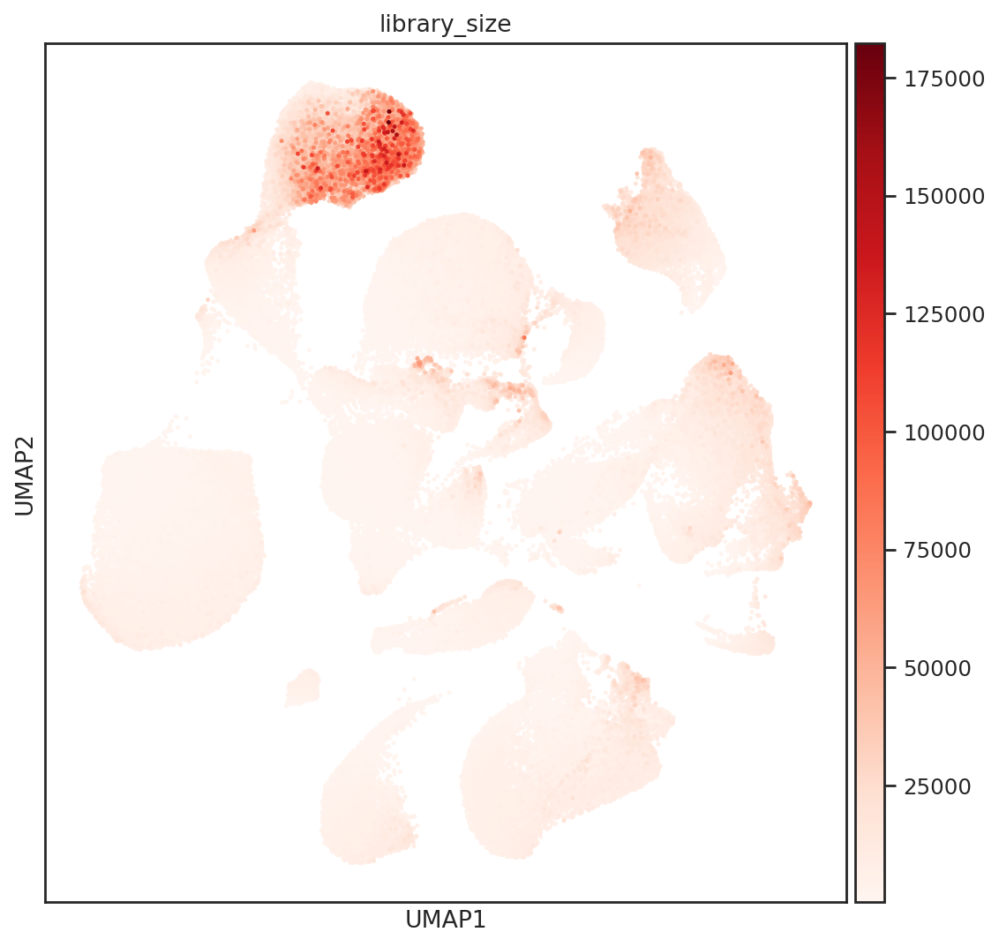

In [112]:
fig, ax = plt.subplots(figsize=(8,8))

sc.pl.umap(adata, color='library_size',s=20, ax=ax, cmap='Reds')

#### Type 2 - Small clusters of minor cell types

In [113]:
# Define functions for vmin and vmax of genes expression:
def get_vmin(values):
    p=0.05
    vmin=float(np.quantile(values, p))
    vmin = max(0, vmin)
    return float(vmin)

def get_vmax(values):
    p=0.95
    vmax=float(np.quantile(values, p))
    if vmax<=0:
        vmax=0.1
    return float(vmax)

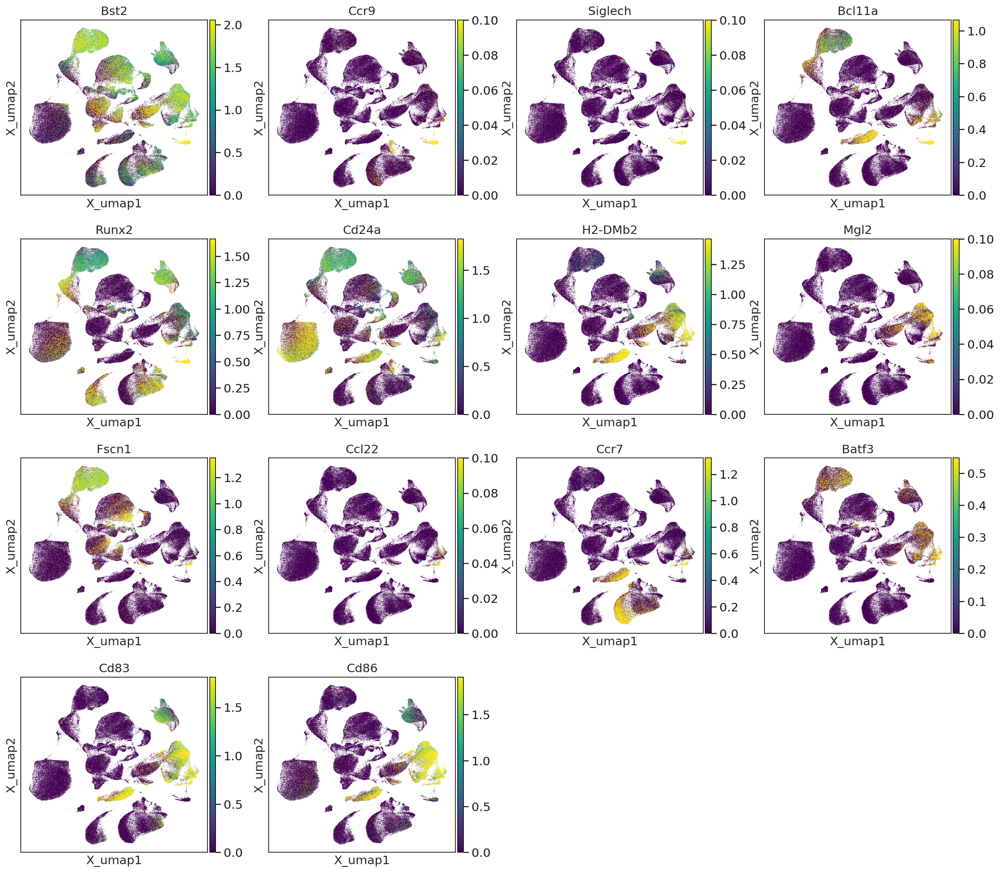

In [114]:
# Check dendritic cell markers
# These markers are from the dendritic cell dotplot of the CIN TME paper:

sc.settings.verbosity = 4
sc.set_figure_params(dpi=80, dpi_save=300)

adata.X = adata.layers['logX']

genes = ['Bst2', 'Ccr9', 'Siglech', 'Bcl11a', 'Runx2', # <-- pDC markers
         'Cd24a', 'H2-DMb2', 'Mgl2', 'Fscn1', 'Ccl22', 'Ccr7', 'Batf3', 'Cd83', 'Cd86']

sc.pl.embedding(adata, basis=basis, color=genes, cmap='viridis', vmin=get_vmin, vmax=get_vmax, ncols=4, save='_DC_markers_from_CINTME.png')

Missing Genes:  ['Igha2']


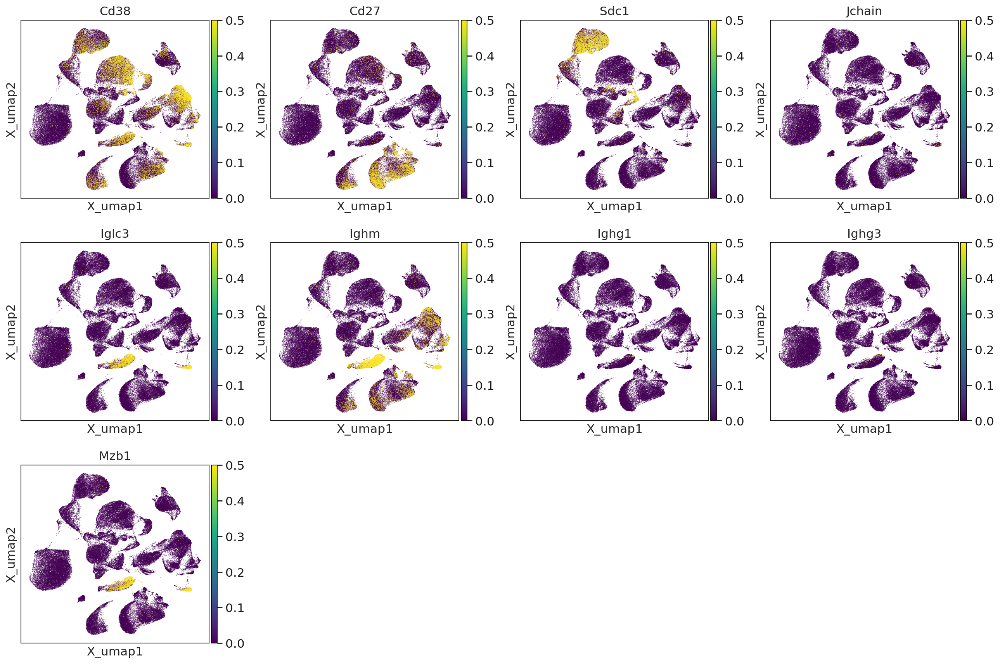

In [115]:
# Check Plasma B cells
# These markers are from the LungMAP paper for human markers

sc.settings.verbosity = 4
sc.set_figure_params(dpi=80, dpi_save=300)

adata.X = adata.layers['logX']

genes = ['CD38', 'CD27', 'SDC1', 'JCHAIN', 'IGLC3', 'IGHM', 'IGHG1', 'IGHG3', 'IGHA2', 'MZB1']
genes = [x.capitalize() for x in genes]
print('Missing Genes: ', [x for x in genes if x not in adata.var.index.tolist()])
genes = [x for x in genes if x in adata.var.index.tolist()]

sc.pl.embedding(adata, basis=basis, color=genes, cmap='viridis', vmin=0, vmax=0.5, ncols=4, save='_Plasma_Bcell_markers_from_LungMAP.png')

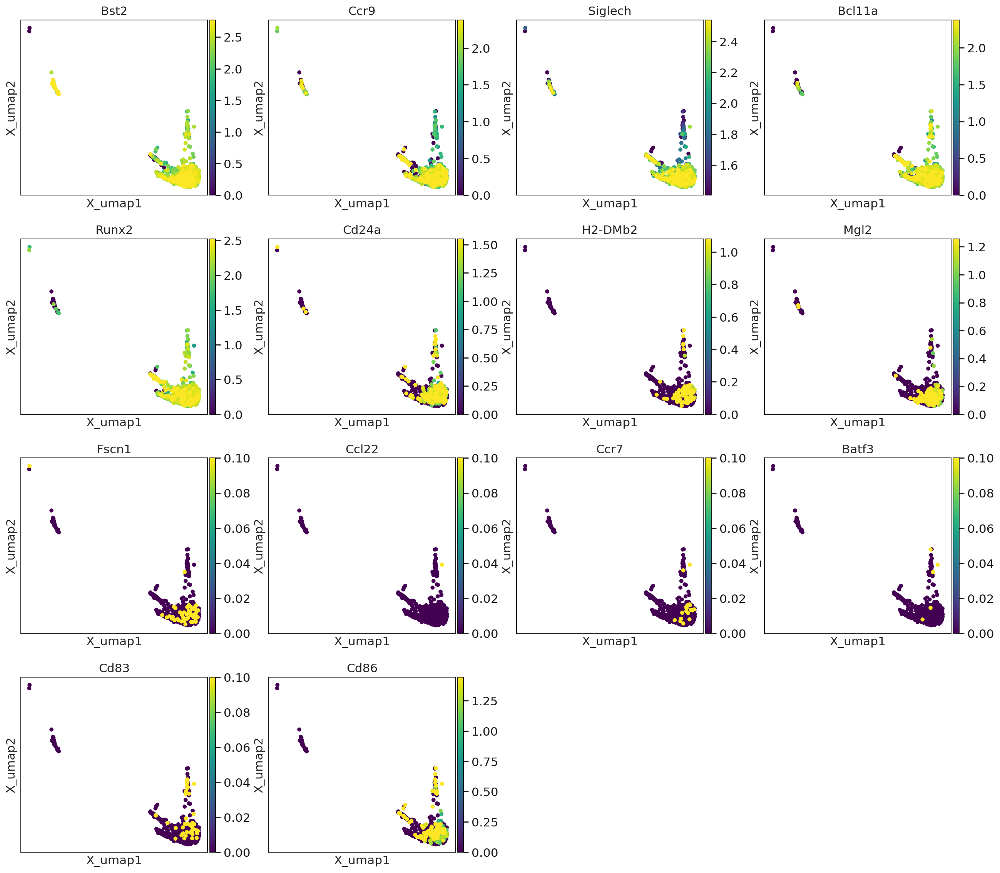

In [116]:
# Check dendritic cell markers
# These markers are from the dendritic cell dotplot of the CIN TME paper:

sc.settings.verbosity = 4
sc.set_figure_params(dpi=80, dpi_save=300)

adata.X = adata.layers['logX']

genes = ['Bst2', 'Ccr9', 'Siglech', 'Bcl11a', 'Runx2', # <-- pDC markers
         'Cd24a', 'H2-DMb2', 'Mgl2', 'Fscn1', 'Ccl22', 'Ccr7', 'Batf3', 'Cd83', 'Cd86']
f = adata.obs[cluster_col] == '29'
sc.pl.embedding(adata[f], basis=basis, color=genes, cmap='viridis', vmin=get_vmin, vmax=get_vmax, ncols=4, save='_DC_markers_from_CINTME_cluster29.png')

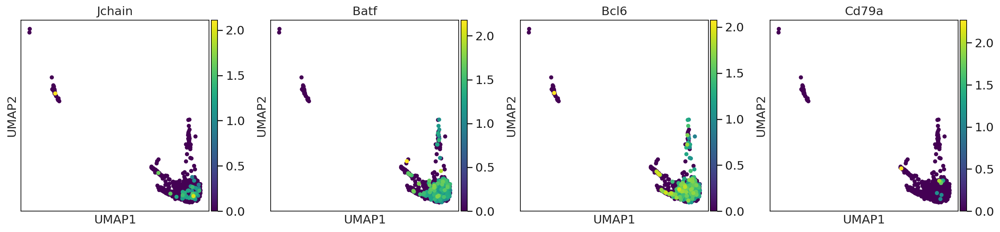

In [117]:
sc.pl.umap(adata[f], color=['Jchain', 'Batf', 'Bcl6', 'Cd79a'], cmap='viridis')

/usr/local/lib/python3.10/dist-packages/scanpy/plotting/_dotplot.py:168: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  obs_bool.groupby(level=0).sum() / obs_bool.groupby(level=0).count()
/usr/local/lib/python3.10/dist-packages/scanpy/plotting/_dotplot.py:178: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dot_color_df = self.obs_tidy.groupby(level=0).mean()


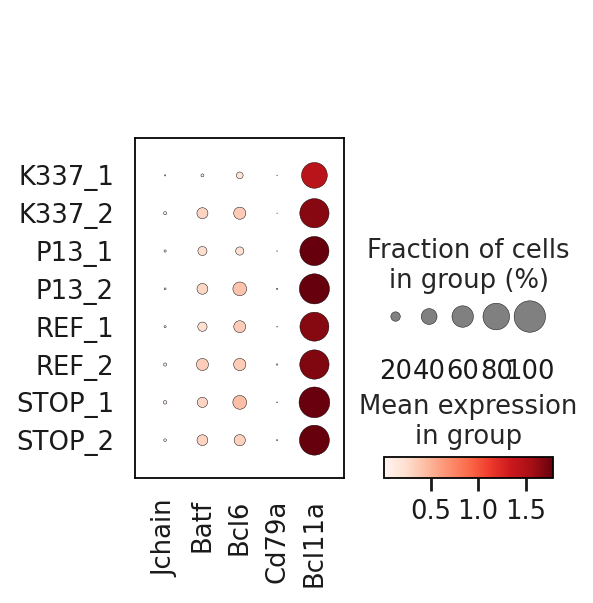

In [118]:
sc.pl.dotplot(adata[f], var_names=['Jchain', 'Batf', 'Bcl6', 'Cd79a', 'Bcl11a'], groupby='sample')

/usr/local/lib/python3.10/dist-packages/scanpy/plotting/_dotplot.py:168: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  obs_bool.groupby(level=0).sum() / obs_bool.groupby(level=0).count()
/usr/local/lib/python3.10/dist-packages/scanpy/plotting/_dotplot.py:178: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dot_color_df = self.obs_tidy.groupby(level=0).mean()


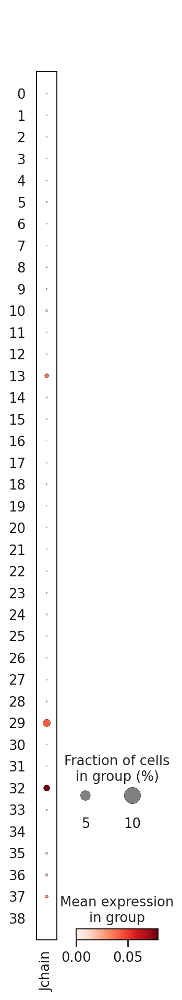

In [119]:
sc.pl.dotplot(adata, var_names='Jchain', groupby=cluster_col)

Missing Genes:  ['Igha2']


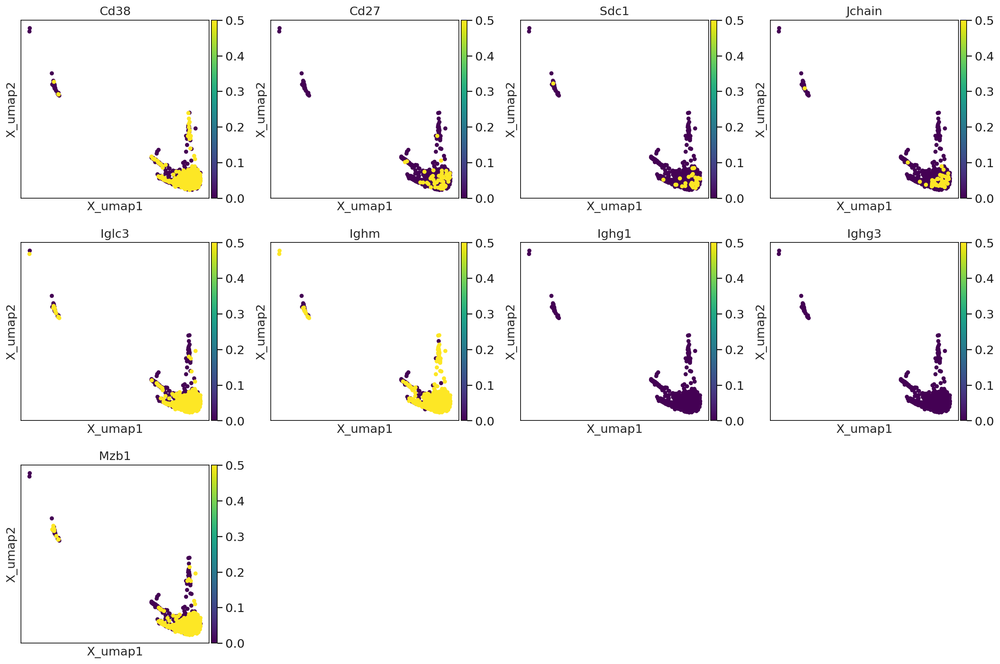

In [120]:
# Check Plasma B cells
# These markers are from the LungMAP paper for human markers

sc.settings.verbosity = 4
sc.set_figure_params(dpi=80, dpi_save=300)

adata.X = adata.layers['logX']

genes = ['CD38', 'CD27', 'SDC1', 'JCHAIN', 'IGLC3', 'IGHM', 'IGHG1', 'IGHG3', 'IGHA2', 'MZB1']
genes = [x.capitalize() for x in genes]
print('Missing Genes: ', [x for x in genes if x not in adata.var.index.tolist()])
genes = [x for x in genes if x in adata.var.index.tolist()]
f = adata.obs[cluster_col] == '29'
sc.pl.embedding(adata[f], basis=basis, color=genes, cmap='viridis', vmin=0, vmax=0.5, ncols=4, save='_Plasma_Bcell_markers_from_LungMAP_cluster29.png')

In [121]:
markers=pd.read_csv('data/lung_markers_with_4T1.csv', index_col=0)
markers

,Endothelial cells,Fibroblasts,AM,Smooth Muscle,AT1,AT2,B cells,Basal cells,Basophil,T cells,...,Mast cells,Platelet,Mesothelial,Neutrophil,NK cells,Pericytes,PNEC,SCMF,Secretory,4T1
AU040972,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
AW112010,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
Abca3,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Abcg1,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Acan,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Wt1,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
Xcr1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Xlr,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Zbtb46,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [122]:
ilc_markers = list(markers.loc[markers['ILC'] != 0].index)
ilc_markers

['Arg1',
 'Ccr2',
 'Cxcr6',
 'Gata3',
 'Il5',
 'Il7r',
 'Klrg1',
 'Rora',
 'S100a4',
 'Thy1']

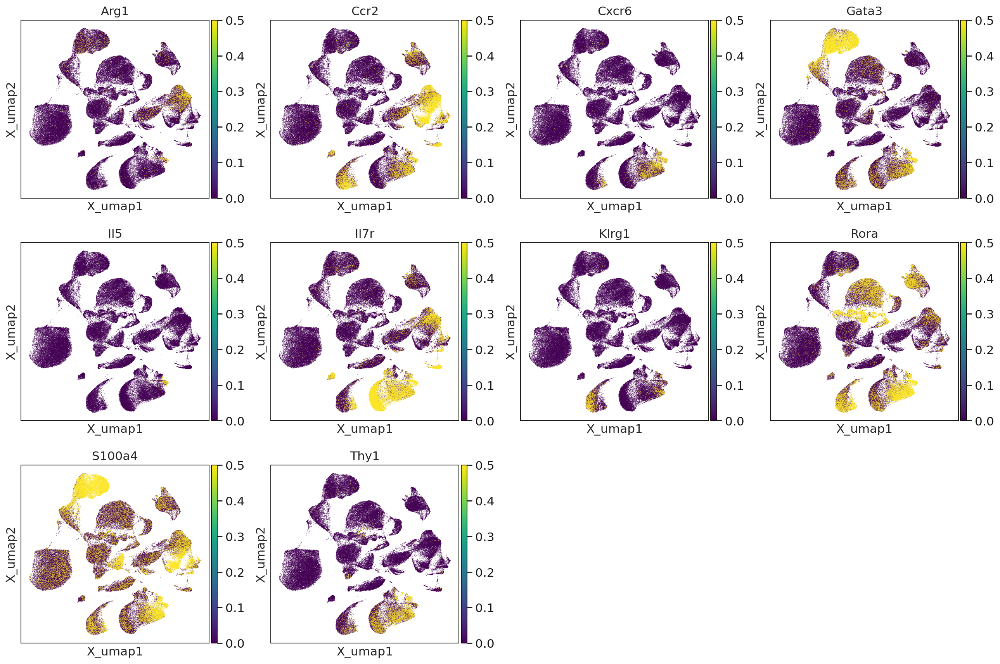

In [123]:
sc.pl.embedding(adata, basis=basis, color=ilc_markers, cmap='viridis', vmin=0, vmax=0.5, ncols=4, save='_ILC_markers_from_LungMAP.png')

In [124]:
tcell_markers = list(markers.loc[markers['T cells'] != 0].index)
tcell_markers

['Cd2',
 'Cd3d',
 'Cd3e',
 'Cd3g',
 'Cd4',
 'Cd8a',
 'Cd8b1',
 'Ctla4',
 'Foxp3',
 'Icos',
 'Ikzf2',
 'Il2ra',
 'Izumo1r',
 'Klrg1',
 'Lef1',
 'Ms4a4b',
 'Ms4a6b',
 'Tcf7',
 'Thy1',
 'Trbc1',
 'Trbc2']

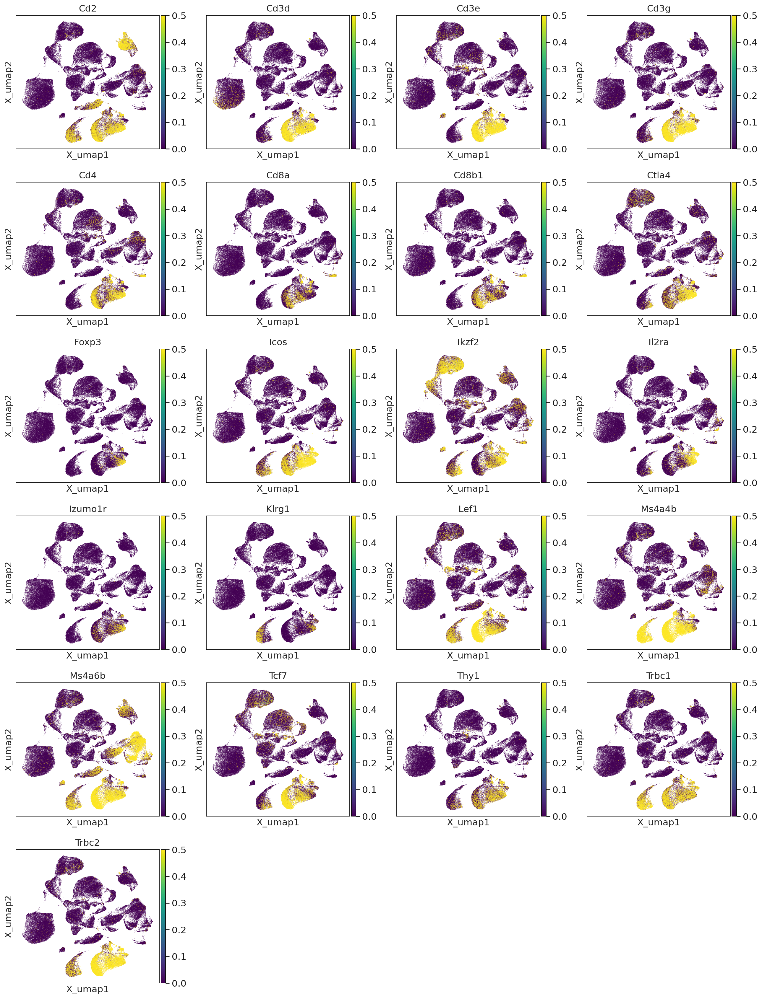

In [125]:
sc.pl.embedding(adata, basis=basis, color=tcell_markers, cmap='viridis', vmin=0, vmax=0.5, ncols=4, save='_Tcell_markers_from_LungMAP.png')

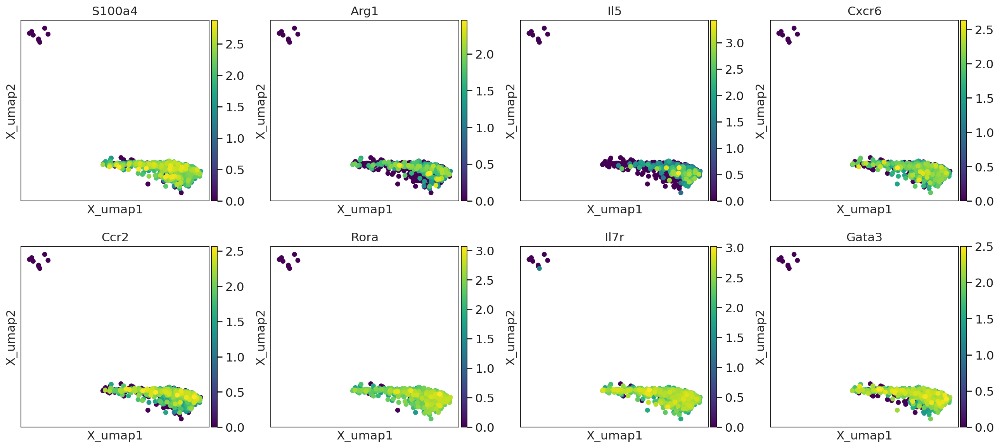

In [126]:
f = adata.obs[cluster_col] == '34'
genes = list(set(ilc_markers).difference(set(tcell_markers)))

sc.pl.embedding(adata[f], basis=basis, color=genes, cmap='viridis', ncols=4,  save='_ILC_markers_from_LungMAP_cluster34.png')

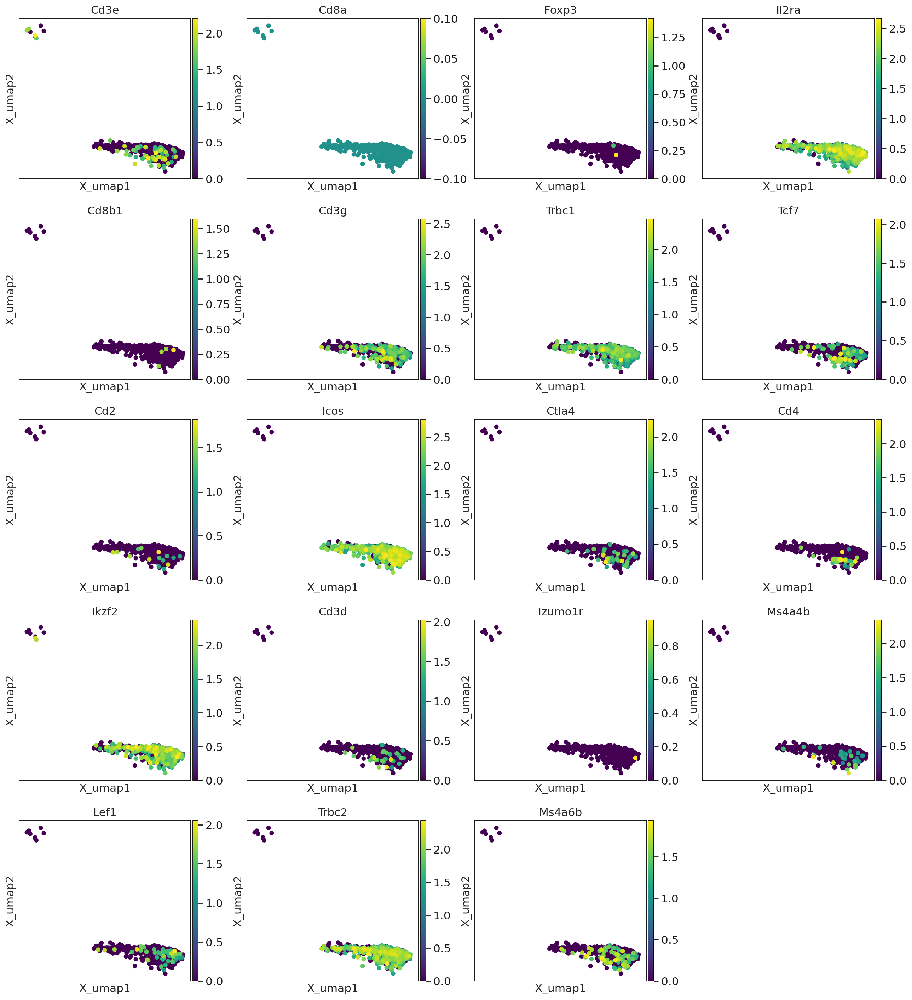

In [127]:
f = adata.obs[cluster_col] == '34'
genes = list(set(tcell_markers).difference(set(ilc_markers)))
sc.pl.embedding(adata[f], basis=basis, color=genes, cmap='viridis', ncols=4,  save='_Tcell_markers_from_LungMAP_cluster34.png')

In [128]:
f0 = adata.obs[cluster_col]=='34'
sum(adata.obs.loc[f0,celltype_col] == 'Mast cells')

19

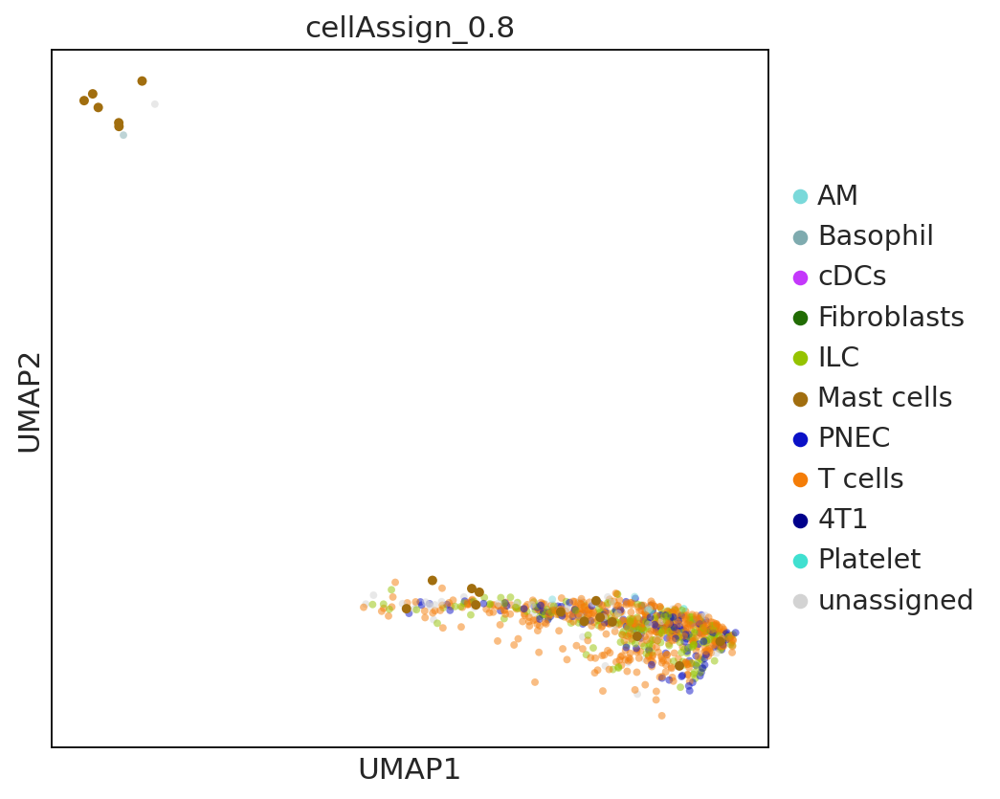

In [129]:
fig, ax = plt.subplots(figsize=(6,6))
sc.pl.umap(adata[f0], color=celltype_col, s=50, ax=ax, show=False, alpha=0.5)
f1 = (f0) & (adata.obs[celltype_col] == 'Mast cells')
sc.pl.umap(adata[f1], color=celltype_col, s=80, ax=ax, legend_loc=None)


/usr/local/lib/python3.10/dist-packages/scanpy/plotting/_dotplot.py:168: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  obs_bool.groupby(level=0).sum() / obs_bool.groupby(level=0).count()
/usr/local/lib/python3.10/dist-packages/scanpy/plotting/_dotplot.py:178: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dot_color_df = self.obs_tidy.groupby(level=0).mean()


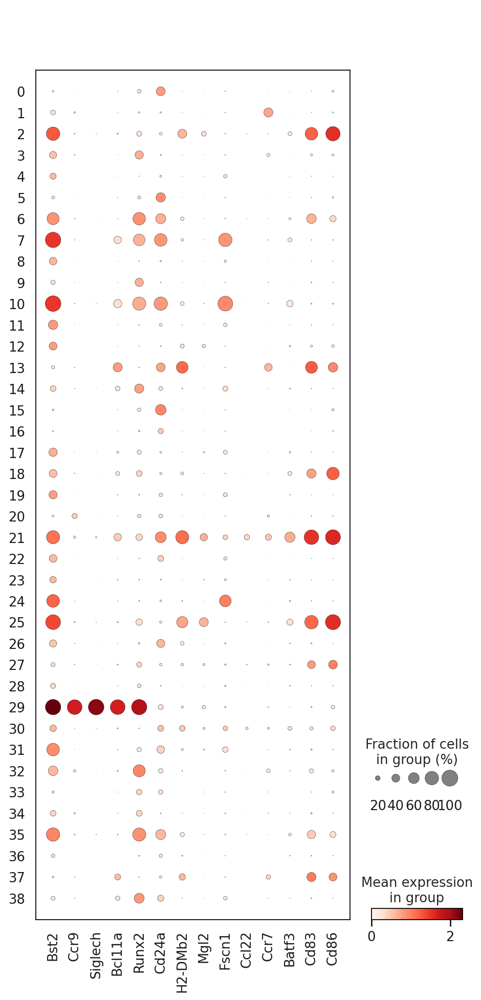

In [130]:
sc.pl.dotplot(adata, var_names=['Bst2', 'Ccr9', 'Siglech', 'Bcl11a', 'Runx2', # <-- pDC markers
         'Cd24a', 'H2-DMb2', 'Mgl2', 'Fscn1', 'Ccl22', 'Ccr7', 'Batf3', 'Cd83', 'Cd86'], groupby=cluster_col)

In [131]:
# Sometimes less common cell types look like another major cell type and get overshadowed in the cellAssigned predictions.

# Example: Plasma B cells will often be called B cells, but form a specific cluster with elevated Jchain expression.

# Often DCs fall into this chategory, but in this dataset they are actually well defined

# Many tumor cells in this dataset are coming from lower quality libraries and aren't confidently assigned by cellAssign


#current_clusters_cellType_dict = {'23': 'Basal cells',
#                                  '40': 'pDCs', 
#                                  '38': 'Adipocytes'} # Unique expression of adipose markers from rank_genes_groups: Cfd, Car3, Plin1, *Adipoq*, Pck1
current_clusters_cellType_dict = {'29':'pDCs'}
current_clusters = sorted(current_clusters_cellType_dict.keys())

# Update minor cell type clusters:

index_celltype_dict = dict(zip(adata.obs.index.tolist(), adata.obs['Macro Cell Type 2'].values.tolist()))
update_dict = {}

for cluster in current_clusters:
    
    # The mode should not be unassigned for a non-ambiguous cluster:

    cellType = current_clusters_cellType_dict[cluster]
        
    tmp = dict(zip(adata[adata.obs[cluster_col] == cluster].obs.index.tolist(), 
                   [cellType for x in range(len(adata[adata.obs[cluster_col] == cluster]))]))
    
    update_dict.update(tmp)

# Check that only un-ambiguous clusters are being update:
if sum(adata[pd.Series(list(update_dict.keys()))].obs[cluster_col].map(lambda x: x not in current_clusters)) > 0:
    print('ERROR: Cells from Incorrect Cluster(s) are being updated.')

# Update index-to-cellType dictionary with the cluster-to-cellType dictionary:
index_celltype_dict_3 = index_celltype_dict
index_celltype_dict_3.update(update_dict)


adata.obs['Macro Cell Type 3'] = adata.obs.index.map(index_celltype_dict_3)

adata.uns['Macro Cell Type 3_colors'] = [cell_type_cmap[x] for x in sorted(adata.obs['Macro Cell Type 3'].unique())]

In [132]:
adata.obs['Macro Cell Type 3']

AAACCATTCAGCATAT-K337_1    Endothelial cells
AAACCATTCCAGCTCC-K337_1            Secretory
AAACCATTCCATATCC-K337_1           Neutrophil
AAACCATTCGTCTCAT-K337_1    Endothelial cells
AAACCATTCTAGGCCG-K337_1              T cells
                                 ...        
TGTGTTAGTTGCGGTC-STOP_2             Basophil
TGTGTTAGTTTGACGT-STOP_2           Neutrophil
TGTGTTGAGAAGCGGC-STOP_2    Endothelial cells
TGTGTTGAGGATTGAA-STOP_2              T cells
TGTGTTGAGGCTGTAC-STOP_2                   IM
Name: Macro Cell Type 3, Length: 149323, dtype: object

In [133]:
cell_type_cmap['Endothelial cells'] =  '#6B0C0C'

In [134]:
cell_type_cmap['AT2'] = '#C70B0B'

In [135]:
cell_type_cmap['Endothelial cells']

'#6B0C0C'

#### Type 4 - More than one cell type

In [136]:
files=glob.glob('data/cellAssign/cellAssign_*assignments.txt*')
probs=[]
for f in files:
    tmp = pd.read_csv(f, sep='\t', index_col=0)
    tmpf = f.replace('assignments', 'probs')
    tmp2 = pd.read_csv(tmpf, sep='\t')
    tmp2.index = tmp.index
    tmp = tmp.loc[tmp.index.isin(adata.obs.index)]
    tmp2 = tmp2.loc[tmp2.index.isin(adata.obs.index)]
    probs.append(tmp2)
probs = pd.concat(probs)

In [137]:
# Often similar cell types (monocytes + macrophages, T cells + NK cells) will group together in some clusters
# For these clusters, assign each cell to the most likely cell type of the options

current_clusters_cellType_dict = {'2': ['AM', 'iMON', 'IM', 'cDCs'],
                                  '17':['Fibroblasts', 'Smooth Muscle', 'SCMF', 'Mesothelial'],
                                 '18': ['AM', 'iMON', 'IM', 'cDCs'],
                                 '20':['T cells', 'NK cells'],
                                  '23':['Fibroblasts', 'Smooth Muscle', 'Mesothelial', 'SCMF'],
                                  '26':['AT2', 'AT1','Ciliated', 'Secretory'],
                                  '27':['AM', 'iMON', 'IM', 'cDCs'],
                                  '30':['cDCs', 'B cells'],
                                  '31':['Endothelial cells', 'AT2', 'Pericytes', 'Fibroblasts', 'AT1'],
                                  '32':['T cells', 'NK cells', 'B cells'],
                                  '34':['ILC','Mast cells'],  # not sure about this one?
                                  '36':['AM', 'Endothelial cells'],
                                  '38':['Neutrophil', '4T1']
                                 }

for k in current_clusters_cellType_dict.values():
    for j in k:
        if j not in probs.columns:
            print(j)
    

current_clusters = sorted(current_clusters_cellType_dict.keys())

# Merge all that aren't in top non-unassigned to top options by probability
index_celltype_dict = dict(zip(adata.obs.index.tolist(), adata.obs['Macro Cell Type 3'].values.tolist()))
update_dict = {}

for cluster in current_clusters:
    
    # The mode should not be unassigned for a non-ambiguous cluster:
    cellType = current_clusters_cellType_dict[cluster]
    tmp = dict(zip(adata[adata.obs[cluster_col] == cluster].obs.index.tolist(), 
                   probs.loc[adata[adata.obs[cluster_col] == cluster].obs.index.tolist(),
                             current_clusters_cellType_dict[cluster]].idxmax(axis=1)))
    
    update_dict.update(tmp)

# Check that only un-ambiguous clusters are being update:
if sum(adata[pd.Series(list(update_dict.keys()))].obs[cluster_col].map(lambda x: x not in current_clusters)) > 0:
    print('ERROR: Cells from Incorrect Cluster(s) are being updated.')

# Update index-to-cellType dictionary with the cluster-to-cellType dictionary:
index_celltype_dict_4 = index_celltype_dict
index_celltype_dict_4.update(update_dict)

adata.obs['Macro Cell Type 4'] = adata.obs.index.map(index_celltype_dict_4)
adata.uns['Macro Cell Type 4_colors'] = [cell_type_cmap[x] for x in sorted(adata.obs['Macro Cell Type 4'].unique())]

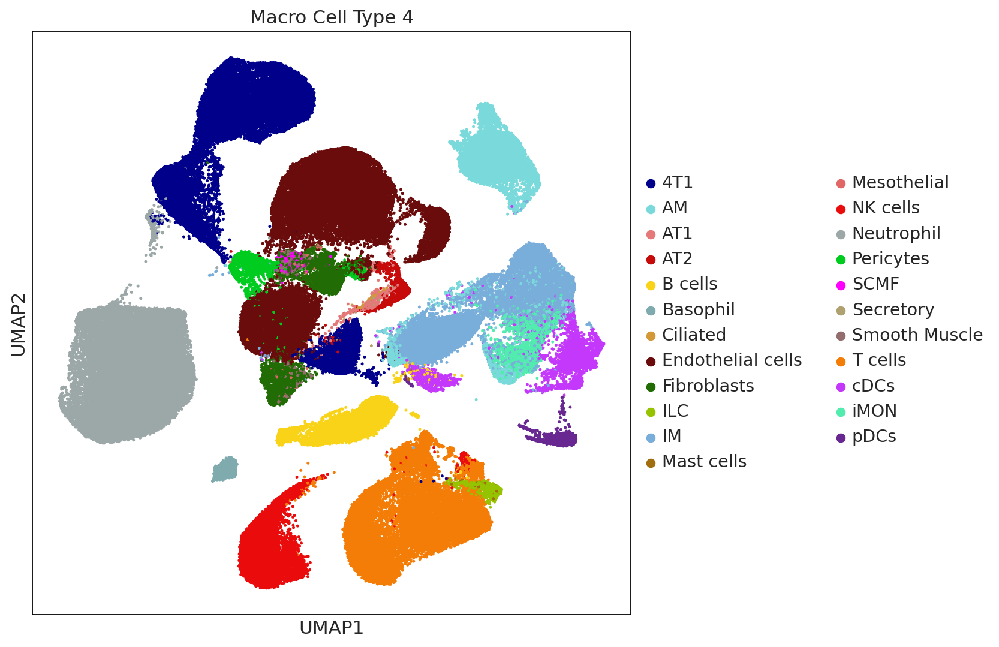

In [138]:
fig, ax = plt.subplots(figsize=(8,8))
sc.pl.umap(adata, color='Macro Cell Type 4', s=20, ax=ax)

In [139]:
adata.obs['Macro Cell Type 4'].value_counts()

Macro Cell Type 4
Endothelial cells    25357
Neutrophil           25356
4T1                  20975
T cells              20373
IM                   15346
AM                   10145
NK cells              7305
B cells               6328
Fibroblasts           4441
cDCs                  3841
iMON                  2591
Pericytes             1504
AT2                   1328
pDCs                  1298
Basophil               916
ILC                    853
Smooth Muscle          492
AT1                    401
SCMF                   218
Mesothelial             94
Ciliated                73
Mast cells              55
Secretory               33
Name: count, dtype: int64

In [140]:
adata.obs['celltype'] = adata.obs['Macro Cell Type 4'].copy()

### Look at T cell subtypes

In [141]:

# LINKAGE

genes = ['Cd8a', 'Cd8b1', 'Tcf7', 'Ccr7', 'Lef1', 'Cd4', 'Cd44', 'Cxcr6',
         'Pdcd1', 'Cxcr5', 'Havcr2', 'Foxp3', 'Tox',
         'Il2ra', 'Il1rl1', 'Clnk', 'Ifngr1', 'Trgc1', 'Trdc', 'Il23r',
         'Xcl1', 'Klrc1', 'Klrk1', 'Gzma', 'Gzmb', 'Nkg7', 'Gzmk']

adata_sub = adata[adata.obs['Macro Cell Type 4'].map(lambda x: x in ['T cells', 'NK cells', 'ILC'])].copy()

In [142]:
adata_sub.obs['Macro Cell Type 4'].value_counts()

Macro Cell Type 4
T cells     20373
NK cells     7305
ILC           853
Name: count, dtype: int64

In [143]:
# This is how pca/leiden/UMAP were computed.
sc.pp.pca(adata_sub)
sc.pp.neighbors(adata_sub)
sc.tl.leiden(adata_sub)
sc.tl.umap(adata_sub)

computing PCA
    on highly variable genes
    with n_comps=50
    finished (0:00:12)
    and added
    'X_pca', the PCA coordinates (adata.obs)
    'PC1', 'PC2', ..., the loadings (adata.var)
    'pca_variance', the variance / eigenvalues (adata.uns)
    'pca_variance_ratio', the variance ratio (adata.uns)
computing neighbors
        initialized `.distances` `.connectivities` 
    computing neighbors
    using 'X_pca' with n_pcs = 50
    computed neighbors (0:00:01)
    computed connectivities (0:00:01)
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:03)
running Leiden clustering
    finished: found 19 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:42)
computing UMAP


  3% 6/200 [00:00<00:22,  8.47it/s]

	completed  0  /  200 epochs


 13% 26/200 [00:02<00:12, 14.12it/s]

	completed  20  /  200 epochs


 23% 46/200 [00:03<00:10, 14.33it/s]

... (79 outputs left out)

 99%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████  | 198/200 [00:13<00:00, 14.68it/s]

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 200/200 [00:14<00:00, 14.69it/s]

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 200/200 [00:14<00:00, 14.18it/s]

    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:00:14)


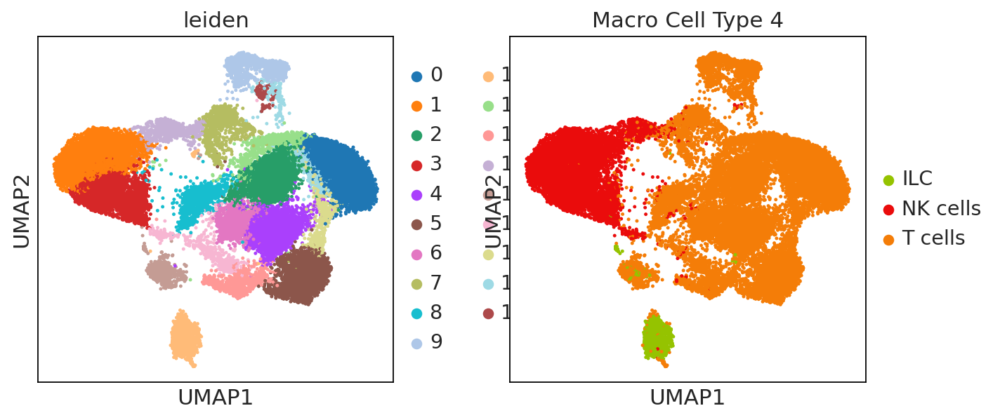

In [144]:
adata_sub.obs['Cell Subtype'] = adata_sub.obs['leiden']
sc.pl.umap(adata_sub, color=['leiden', 'Macro Cell Type 4'], s=20)

In [145]:
tmpadata = adata_sub

In [146]:
tmpadata.X = tmpadata.layers['logX']
#genes = [g for g in genes if g in adata.var.index]
genes = [g for g in ['Trgc1', 'Trgc2', 'Trdc', 'Trdj1', 'Trdv2-2', 'Trdv4', 'Trgv4', 'Trgv6', 'Trgv2', 'Trgv1', 'Trgc4'] if g in adata.var.index]
genes = genes + [g for g in adata.var.index if 'Tcr' in g]
print(genes)

['Trdc', 'Trdj1', 'Trdv2-2', 'Trdv4', 'Trgv2', 'Tcrg-V7', 'Tcrg-V4', 'Tcrg-V6', 'Tcrg-V5', 'Tcrg-C1', 'Tcrg-V3', 'Tcrg-C3', 'Tcrg-C2', 'Tcrg-V1', 'Tcrg-C4']


/tmp/ipykernel_58269/1425917027.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  heatmap_data = heatmap_data.reset_index().groupby('Cell Subtype').mean()
/usr/local/lib/python3.10/dist-packages/scanpy/plotting/_dotplot.py:168: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  obs_bool.groupby(level=0).sum() / obs_bool.groupby(level=0).count()
/usr/local/lib/python3.10/dist-packages/scanpy/plotting/_dotplot.py:178: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the futu

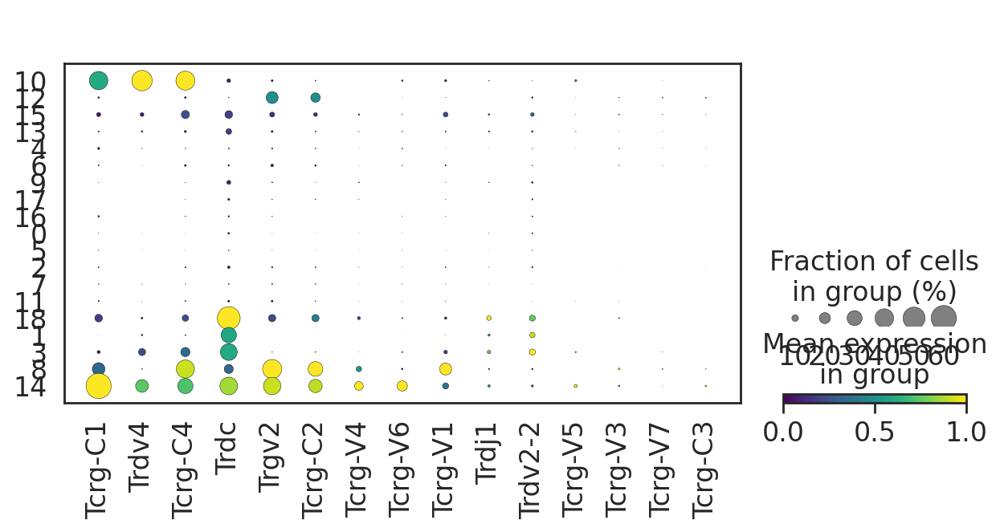

/usr/local/lib/python3.10/dist-packages/scanpy/plotting/_dotplot.py:168: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  obs_bool.groupby(level=0).sum() / obs_bool.groupby(level=0).count()
/usr/local/lib/python3.10/dist-packages/scanpy/plotting/_dotplot.py:178: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dot_color_df = self.obs_tidy.groupby(level=0).mean()


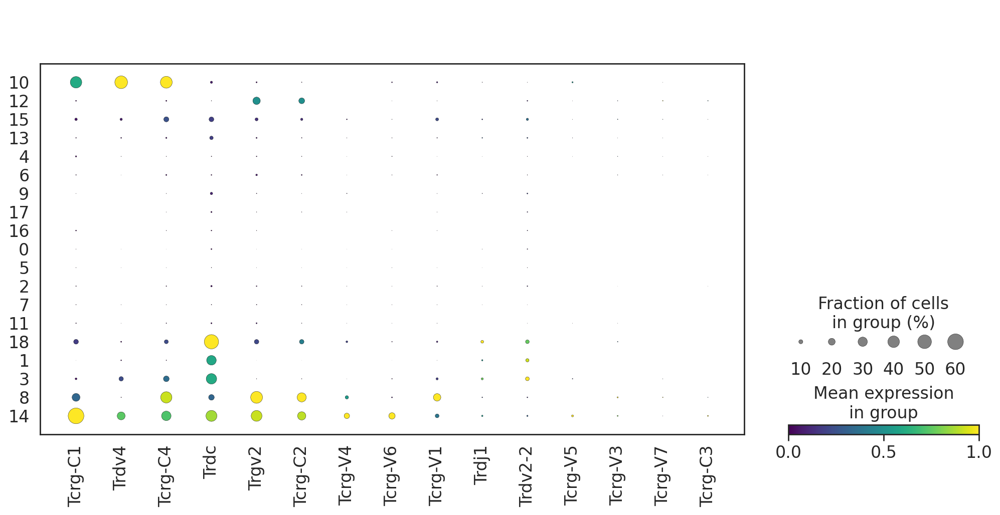

In [147]:
heatmap_data = pd.DataFrame(data = stats.zscore(pd.DataFrame(tmpadata[:,genes].X.toarray()), axis=0).values,
                            columns = genes,
                            index = tmpadata.obs['Cell Subtype'])

heatmap_data = heatmap_data.reset_index().groupby('Cell Subtype').mean()

method = 'complete' # average, single
metric = 'cityblock' # cosine
linkage = hc.linkage(heatmap_data, method=method, metric = metric)
row_linkage = linkage.copy()
linkage = hc.linkage(heatmap_data.T, method=method, metric = metric)
col_linkage = linkage.copy()

# REORDER HEATMAP ACCORDING TO LINKAGE (OPTIONAL, STILL SLOW)
r1 = hc.leaves_list(row_linkage)
c1 = hc.leaves_list(col_linkage)
mat = heatmap_data.iloc[r1,c1]

genes = mat.columns.tolist()
group_order = mat.index.tolist()

sc.settings.verbosity = 4
sc.set_figure_params(figsize=(12,12), dpi=80, dpi_save=600)

tmpadata.X = tmpadata.layers['logX']

sns.set(style='white', font_scale=1.5)
fig, ax = plt.subplots(figsize=(9,4))
sc.pl.dotplot(tmpadata, groupby='Cell Subtype', categories_order=group_order, var_names=genes, cmap='viridis', vmin=0, vmax=1,
              dot_max=0.6, standard_scale='var', ax=ax, save='_Tcell_subtype_marker_genes_dotplot.png')
plt.show()
sns.set(style='white', font_scale=1.5)

fig, ax = plt.subplots(figsize=(15,7))
sc.pl.dotplot(tmpadata, groupby='Cell Subtype', categories_order=group_order, var_names=genes, cmap='viridis', vmin=0, vmax=1,
              dot_max=0.6, standard_scale='var', ax=ax, save='_Tcell_subtype_marker_genes_dotplot_LEGEND.png')

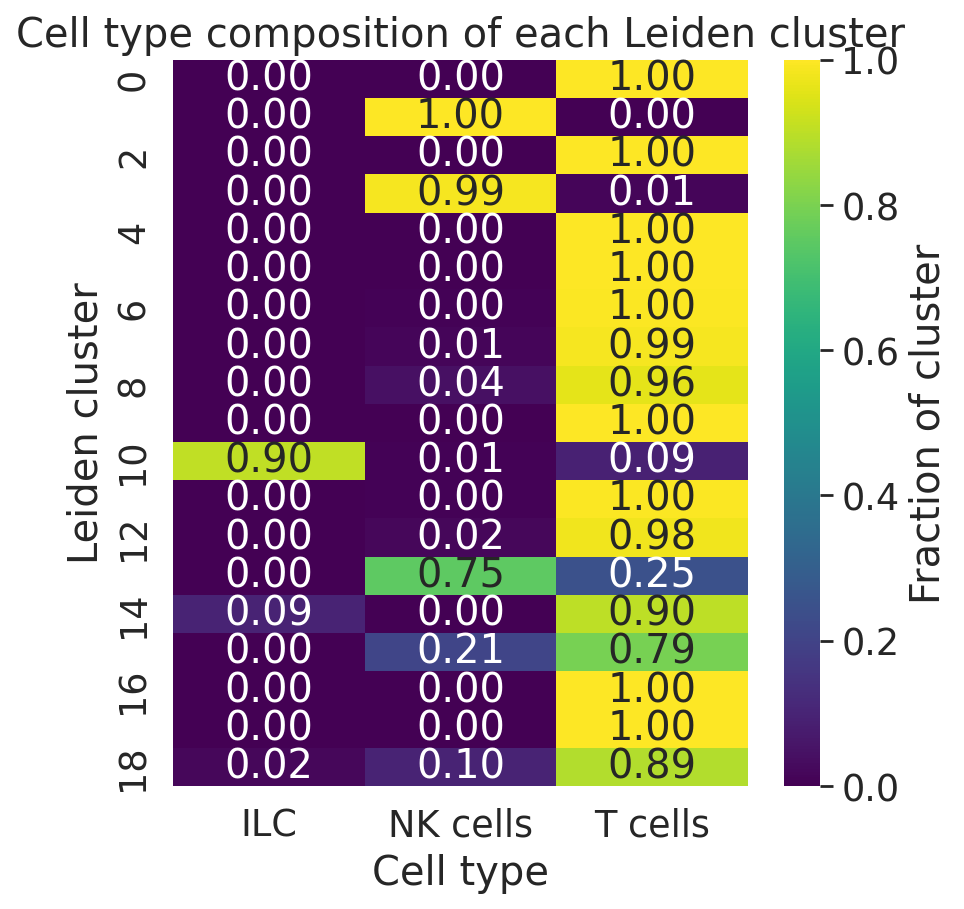

In [148]:
ct_col = 'Macro Cell Type 4'
cl_col = 'leiden'

# counts: rows = clusters, columns = cell types
tab = pd.crosstab(adata_sub.obs[cl_col], adata_sub.obs[ct_col])

# convert to fraction of each cluster
frac = tab.div(tab.sum(axis=1), axis=0)

plt.figure(figsize=(6, 6))
sns.heatmap(
    frac,
    cmap='viridis',
    annot=True,
    fmt='.2f',
    cbar_kws={'label': 'Fraction of cluster'}
)

plt.xlabel('Cell type')
plt.ylabel('Leiden cluster')
plt.title('Cell type composition of each Leiden cluster')
plt.tight_layout()
plt.show()

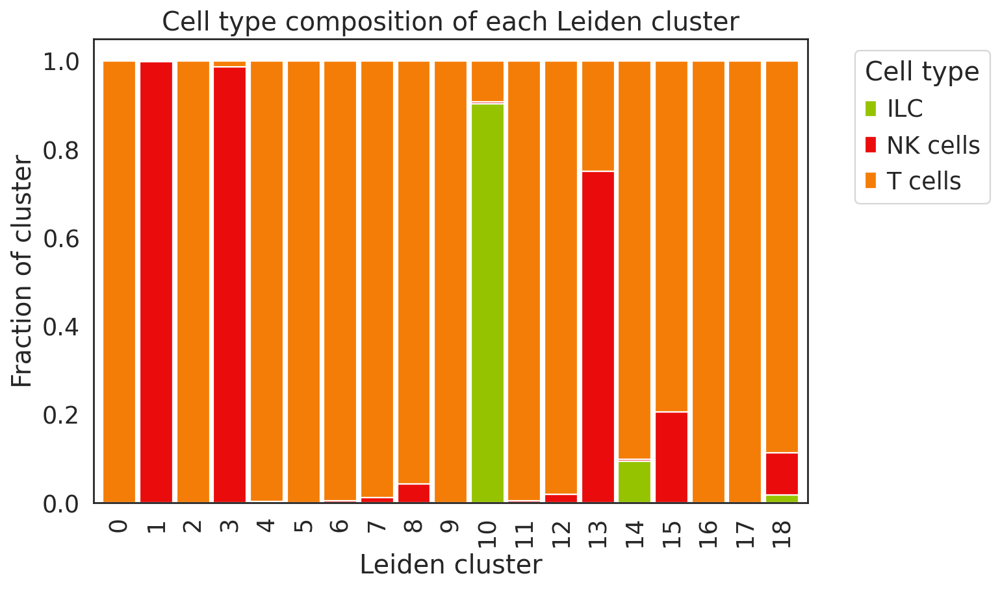

In [149]:
tmpcolors = [celltype_colors[ct] for ct in frac.columns]

frac.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6),
    width=0.9,
    color=tmpcolors
)

plt.ylabel('Fraction of cluster')
plt.xlabel('Leiden cluster')
plt.title('Cell type composition of each Leiden cluster')
plt.legend(title='Cell type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [150]:
genes = ['Trgc1', 'Trgc2', 'Trdc', 'Trdj1', 'Trdv2-2', 'Trdv4', 'Trgv4', 'Trgv6', 'Trgv2', 'Trgv1', 'Trgc4']
cell_subtype_cmap = {'Naive CD4+ T cells': '#ea9057',
                     'Activated CD4+ T cells': '#be9757',
                     'Naive CD8+ T cells': '#f98b89',
                     'Tregs': '#ffc902',
                     'γδ T cells': '#9569DA',
                     'NK cells': '#EA0C0C',
                     'NK2 cells': '#C4A3A3',
                     'NKT cells': '#FF8813',
                     'ILCs': '#95c300',
                     'Unclear T cells': '#A26931',
                     'Exhausted CD8+ T cells':'#825910'
                     }

In [151]:
cell_subtype_map = {
'0': 'Naive CD4+ T cells',
'1': 'NK cells',
'2': 'Naive CD8+ T cells',
'3': 'NK cells',
'4': 'Activated CD4+ T cells',
'5': 'Tregs',
'6': 'NKT cells',
'7': 'Naive CD4+ T cells',
'8': 'NK cells',
'9': 'Naive CD8+ T cells', # high CD4 expression is odd … may be double positive T cells or mixed cluster of CD4+ and CD8+ naive
'10': 'ILCs', # maybe ? always confusing by markers but should be clear from cellAssign
'11': 'Naive CD4+ T cells',
'12': 'Exhausted CD8+ T cells', # the most interesting population with cytotoxic / NK markers and immune-suppressive markers Pdcd1 and Havcr2
'13': 'NK cells',
'14': 'γδ T cells', # not confident here, need to check other γδ side chains
'15': 'NKT cells',
'16': 'Tregs', # either naive or Tregs … perhaps earlier differentiating or intermediate
'17': 'Naive CD4+ T cells',
'18': 'Naive CD8+ T cells',  # may be γδ T cells (Trdc). Check other γδ side chains
}

In [152]:
adata_sub.obs['T_cell_subtype'] = [cell_subtype_map[x] for x in adata_sub.obs['leiden']]
adata_sub.obs['T_cell_subtype'] = pd.Categorical(adata_sub.obs['T_cell_subtype'], categories=list(adata_sub.obs['T_cell_subtype'].value_counts().index))
adata_sub.uns['T_cell_subtype_colors'] = [cell_subtype_cmap[x] for x in adata_sub.obs['T_cell_subtype'].cat.categories]

In [153]:
adata_sub.obs['T_cell_subtype'].value_counts()

T_cell_subtype
NK cells                  8301
Naive CD4+ T cells        7397
Naive CD8+ T cells        3840
Tregs                     2726
Activated CD4+ T cells    2410
NKT cells                 1609
ILCs                       873
Exhausted CD8+ T cells     806
γδ T cells                 569
Name: count, dtype: int64

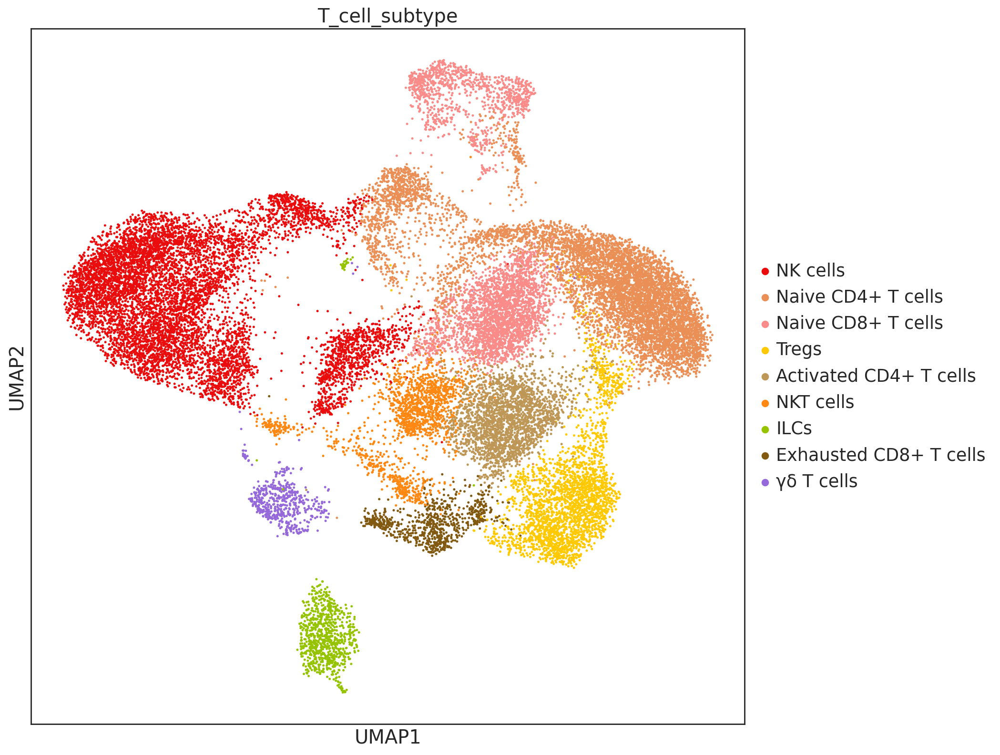

In [154]:
sc.pl.umap(adata_sub, color='T_cell_subtype', s=20, show=False)
plt.close()
rndidx = random.sample(list(adata_sub.obs.index), adata_sub.shape[0])
sc.pl.umap(adata_sub[rndidx], color='T_cell_subtype', s=20)

In [155]:
for k, value in celltype_colors.items():
    if k not in cell_subtype_cmap:
        cell_subtype_cmap[k] = value
    else:
        print(f'{k} already in map')

NK cells already in map


In [156]:
adata.obs['celltype_sub'] = adata.obs['Macro Cell Type 4'].astype(str).copy()
adata.obs.loc[adata_sub.obs.index,'celltype_sub'] = adata_sub.obs['T_cell_subtype'].astype(str).copy()
adata.obs['celltype_sub'] = pd.Categorical(adata.obs['celltype_sub'], categories=adata.obs['celltype_sub'].value_counts().index)
adata.uns['celltype_sub_colors'] = [cell_subtype_cmap[k] for k in adata.obs['celltype_sub'].cat.categories]

### End cellType cleaning

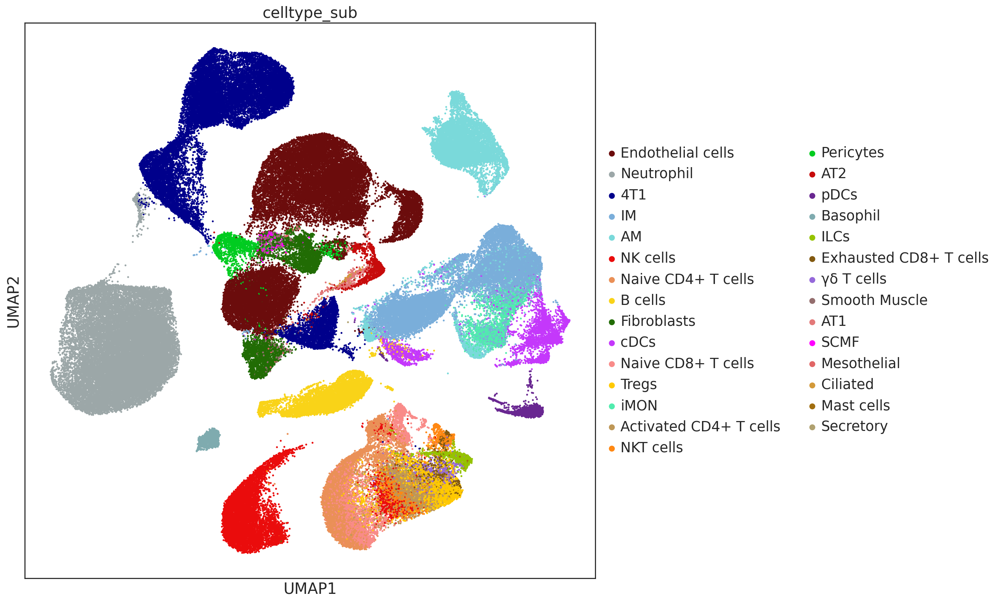

In [157]:
sc.pl.umap(adata, color='celltype_sub', s=20, show=False)
plt.close()
rndidx=random.sample(list(adata.obs.index), adata.obs.shape[0])
sc.pl.umap(adata[rndidx], color='celltype_sub', s=20)

## Figure 4E

In [158]:
adata.obs['condition'] = pd.Categorical([x.split('_')[0] for x in adata.obs['sample']], categories=['REF', 'STOP', 'P13', 'K337'])
adata.uns['condition_colors'] = ['#4d4e4e', '#b3b3b3', '#fbad35', '#ee2a2f']

In [159]:
np.array(adata.obs['celltype_sub'].unique())

array(['Endothelial cells', 'cDCs', 'Neutrophil', 'Naive CD4+ T cells',
       'IM', '4T1', 'Fibroblasts', 'B cells', 'AM', 'NK cells',
       'Naive CD8+ T cells', 'iMON', 'Tregs', 'γδ T cells',
       'Exhausted CD8+ T cells', 'Activated CD4+ T cells', 'AT2',
       'Basophil', 'pDCs', 'Smooth Muscle', 'ILCs', 'Pericytes',
       'NKT cells', 'Mesothelial', 'AT1', 'SCMF', 'Ciliated',
       'Mast cells', 'Secretory'], dtype=object)

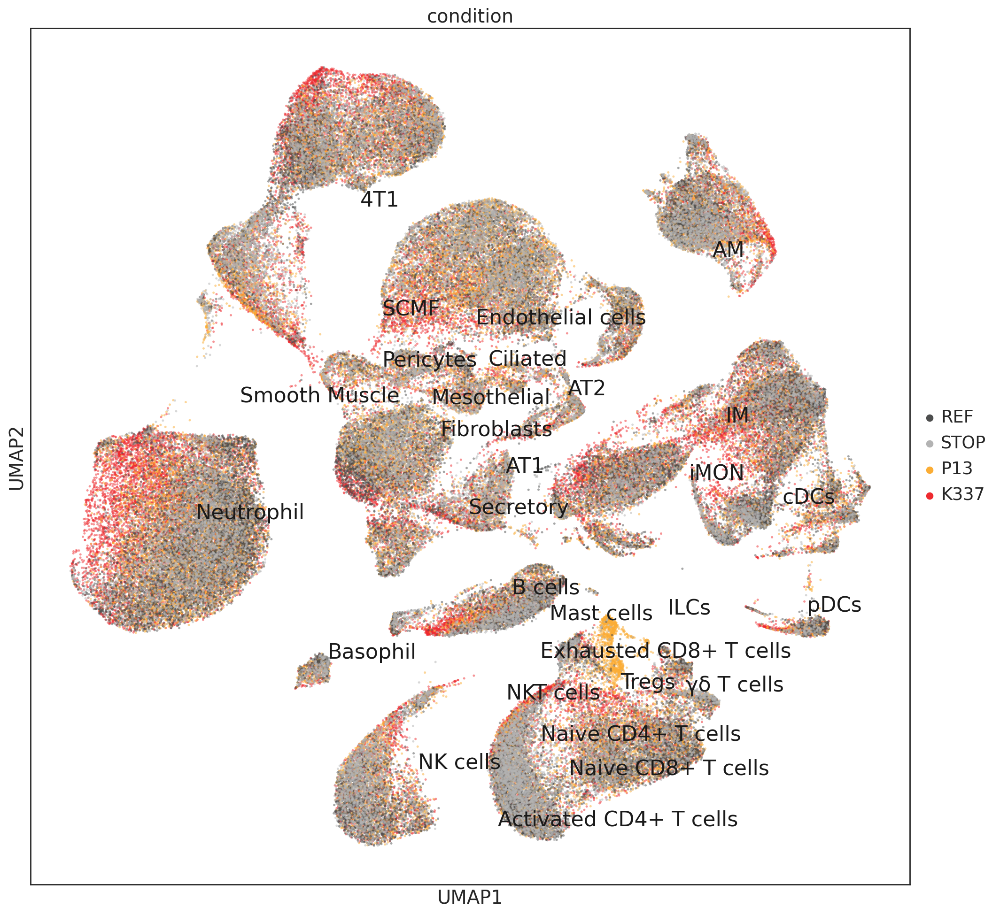

In [160]:
fig, ax = plt.subplots(figsize=(15,15))
sc.pl.umap(adata, color='condition', s=20, ax=ax, alpha=0.5, show=False)
xvals = []
yvals = []
for celltype in adata.obs['celltype_sub'].unique():
    f = adata.obs['celltype_sub'] == celltype
    meanvals = np.mean(adata[f].obsm['X_umap'], axis=0)
    xvals.append(meanvals[0])
    yvals.append(meanvals[1])
ta.allocate(ax, np.array(xvals), np.array(yvals), np.array(adata.obs['celltype_sub'].unique()), textsize=20, draw_lines=False)
plt.show()

In [161]:
adata.obs = adata.obs[['sample', 'library_size', 'mt_frac', 'totReads', 'cellAssign_0.8', 'cellAssign_maxprob', 'scrublet', 'scDbl_score', 'scDbl_class', 
                       'log_library_size', 'log_reads', 'leiden_r1.5', 'Macro Cell Type 4', 'celltype', 'celltype_sub', 'condition']]

In [162]:
adata.write('adata_lung_mets_final.h5ad')

## MILO

### Prep for MILO

In [163]:
adata.obs['condition'] = [x.split('_')[0] for x in adata.obs['sample']]
adata.obs['condition'] = pd.Categorical(adata.obs['condition'], categories=['P13', 'K337', 'STOP', 'REF'])
sum(pd.isna(adata.obs['condition']))

/tmp/ipykernel_58269/3374763269.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  adata.obs['condition'] = [x.split('_')[0] for x in adata.obs['sample']]
/tmp/ipykernel_58269/3374763269.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  adata.obs['condition'] = pd.Categorical(adata.obs['condition'], categories=['P13', 'K337', 'STOP', 'REF'])


0

In [164]:
adata.obs['condition'].value_counts()

condition
P13     39954
K337    38057
STOP    35834
REF     35478
Name: count, dtype: int64

In [165]:
for k in [100]:
    f = adata.obs['condition'].isin(['STOP', 'P13', 'REF', 'K337'])
    tmpadata = sc.AnnData(X=adata[f].X,
                          obs=adata.obs.loc[f],
                          var=adata.var)
    tmpadata.obsm['X_pca'] = adata[f].obsm['X_pca'].copy()
    tmpadata.obsm['X_umap'] = adata[f].obsm['X_umap'].copy()
    sc.pp.neighbors(tmpadata, n_pcs=26, n_neighbors=k)
    tmpadata.write(f'NOBACKUP/adata_for_Milo_k{k}.h5ad')

computing neighbors
    computing neighbors
    using 'X_pca' with n_pcs = 26
    computed neighbors (0:02:49)
    computed connectivities (0:00:49)
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:03:39)


    using 'X_pca' with n_pcs = 26


    computed neighbors (0:02:57)


    computed connectivities (0:00:49)


    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:03:47)


Note: at this point you would need to run MILO in a separate notebook, in a different docker container. You can run it with:

```
docker pull biohpc/milo:0.1
docker run --rm -i -v "$PWD":/work -w /work -p 8009:8888 /work
```

This starts a jupyter notebook running that you can visit at localhost:8009. The token to enter the notebook should be printed to the console. You can then open the `milo_analysis.ipynb` noteook and run through it.

But, the results are stored in the `data/` subdirectory, so you can move forward in this notebook without running MILO yourself.

### Process MILO results

In [166]:
dfs = []
annot = None
for cond1 in adata.obs['condition'].unique():
    for cond2 in adata.obs['condition'].unique():
        mystr=f'{cond1}_vs_{cond2}'
        fname=f'data/milo_da_results_all_{mystr}_k100.csv'
        if os.path.exists(fname):
            print(f'Reading {fname}')
            df = pd.read_csv(fname)
            if 'celltype' in df.columns:
                print(f'{mystr} has annotations')
                tmpcols = ['Nhood', 'x', 'y'] + [x for x in df.columns if 'celltype' in x or 'condition' in x]
                annot = df[tmpcols].copy()
                df = df.drop(columns=tmpcols)
            df = df.add_suffix(f'_{mystr}')
            dfs.append(df)

Reading data/milo_da_results_all_K337_vs_REF_k100.csv
Reading data/milo_da_results_all_K337_vs_STOP_k100.csv
Reading data/milo_da_results_all_P13_vs_K337_k100.csv
Reading data/milo_da_results_all_P13_vs_REF_k100.csv
Reading data/milo_da_results_all_P13_vs_STOP_k100.csv
P13_vs_STOP has annotations
Reading data/milo_da_results_all_STOP_vs_REF_k100.csv


In [167]:
df = pd.concat([annot] + dfs, axis=1).set_index('Nhood', drop=True)

In [168]:
k=100
nh_long = pd.read_csv(f'data/milo_all_k{k}_membership.tsv.gz', sep='\t')

In [169]:
cells_by_nhood = (
    nh_long
    .groupby("Nhood")["cell"]
    .apply(set)
    .to_dict()
)

In [170]:
def get_majority_subtype(nhood):
    cells = list(cells_by_nhood[nhood])  # convert set -> list

    vals = adata.obs.loc[cells, "celltype_sub"]

    # Optional sanity check for missing annotations
    if vals.isna().any():
        raise ValueError(f"Neighborhood {nhood} has cells with missing cell_subtype")

    counts = vals.value_counts()

    if len(counts) == 0:
        return pd.Series({
            "celltype_sub": np.nan,
            "celltype_sub_fraction": np.nan
        })

    top_subtype = counts.index[0]
    top_fraction = counts.iloc[0] / counts.sum()

    return pd.Series({
        "celltype_sub": top_subtype,
        "celltype_sub_fraction": top_fraction
    })

df[["celltype_sub", "celltype_sub_fraction"]] = (
    df.index.to_series().apply(get_majority_subtype)
)

In [171]:
df['celltype_sub'].value_counts()

celltype_sub
Endothelial cells         5157
Neutrophil                5058
4T1                       4233
IM                        3060
AM                        1892
Naive CD4+ T cells        1731
NK cells                  1648
B cells                   1240
Fibroblasts               1008
cDCs                       788
Naive CD8+ T cells         646
iMON                       575
Activated CD4+ T cells     522
Tregs                      511
NKT cells                  315
Pericytes                  280
AT2                        274
pDCs                       272
ILCs                       197
Basophil                   195
Exhausted CD8+ T cells     119
AT1                         72
γδ T cells                  59
Smooth Muscle                8
Ciliated                     4
Name: count, dtype: int64

In [172]:
annot_cols = [x for x in df.columns if 'K337' not in x and 'REF' not in x and 'STOP' not in x and 'P13' not in x]
annot_cols

['x',
 'y',
 'celltype',
 'celltype_fraction',
 'condition',
 'condition_fraction',
 'celltype_sub',
 'celltype_sub_fraction']

In [173]:
df['celltype'] = df['celltype'].astype(str)

In [174]:
f = df['celltype_fraction'] < 0.75
df.loc[f,'celltype'] = 'Mixed'
print(f'Set {sum(f)} ({sum(f)/len(f)*100:0.1f}%) neighborhoods w celltype_Frac < 0.8 to celltype=Mixed')

Set 2023 (6.8%) neighborhoods w celltype_Frac < 0.8 to celltype=Mixed


In [175]:
df['celltype_sub'] = df['celltype_sub'].astype(str)

In [176]:
df['logFC_REF_vs_STOP'] = -df['logFC_STOP_vs_REF']
df['FDR_REF_vs_STOP'] = df['FDR_STOP_vs_REF']
df['PValue_REF_vs_STOP'] = df['PValue_STOP_vs_REF']

In [177]:
adata

AnnData object with n_obs × n_vars = 149323 × 32245
    obs: 'sample', 'library_size', 'mt_frac', 'totReads', 'cellAssign_0.8', 'cellAssign_maxprob', 'scrublet', 'scDbl_score', 'scDbl_class', 'log_library_size', 'log_reads', 'leiden_r1.5', 'Macro Cell Type 4', 'celltype', 'celltype_sub', 'condition'
    var: 'gene_ids', 'feature_types', 'genome', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'log1p', 'cellAssign_0.8_colors', 'hvg', 'pca', 'neighbors', 'umap', 'sample_colors', 'leiden_r1.5_colors', 'unclear_cellType_colors', 'cluster_2_colors', 'cluster_2_celltype_colors', 'cluster_7_colors', 'cluster_7_celltype_colors', 'cluster_10_colors', 'cluster_10_celltype_colors', 'cluster_14_colors', 'cluster_14_celltype_colors', 'cluster_17_colors', 'cluster_17_celltype_colors', 'cluster_18_colors', 'cluster_18_celltype_colors', 'cluster_19_colors', 'cluster_19_celltype_colors', 'cluster_20_colors', 'cluster_20

In [178]:
df["delta"] = (
    df["logFC_P13_vs_STOP"] -
    df["logFC_REF_vs_STOP"]
)

In [179]:
for var in ['P13', 'K337']:
    df[f"delta_{var}"] = (
        df[f"logFC_{var}_vs_STOP"] -
        df["logFC_REF_vs_STOP"]
    )

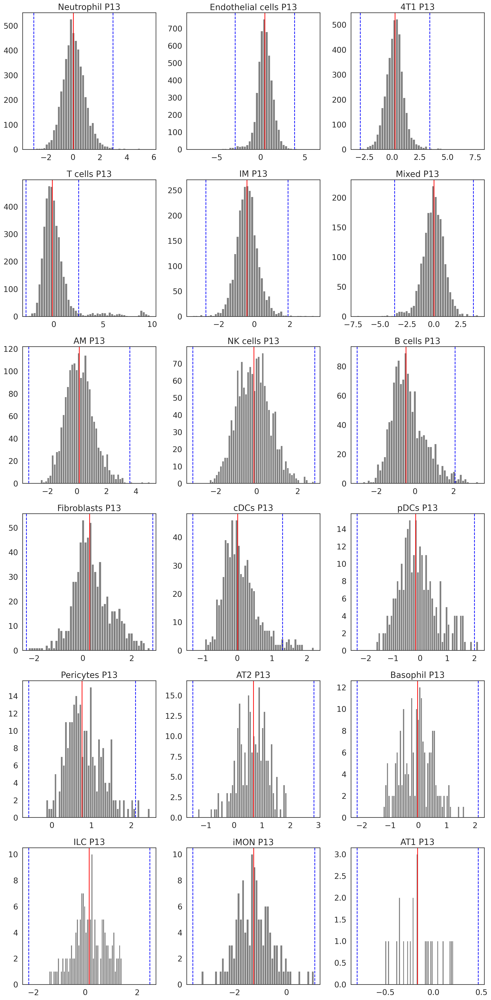

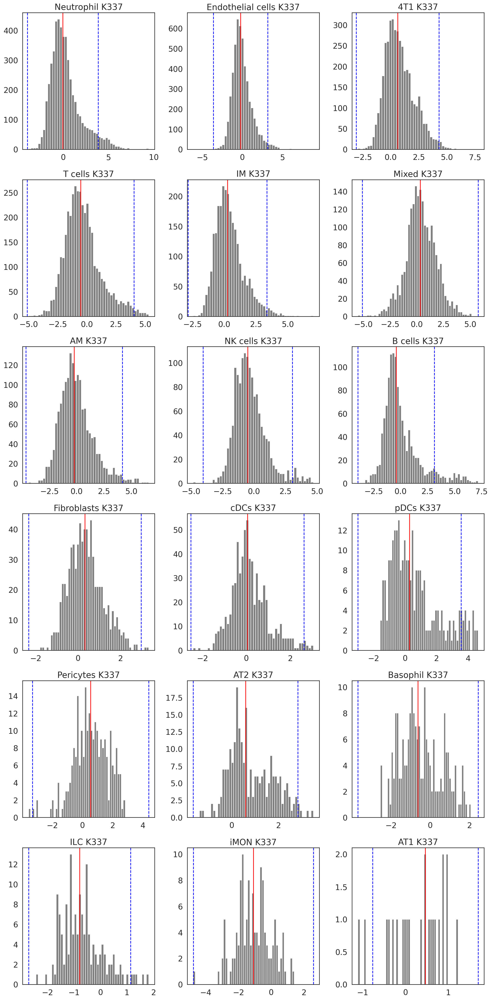

In [180]:
for var in ['P13', 'K337']:
    nrows=6
    ncols=3
    fig, ax = plt.subplots(nrows=nrows, ncols=ncols, figsize=(ncols*5, nrows*5))
    df[f'outlier_direction_{var}']  = 'none'
    for i,celltype in enumerate(df['celltype'].value_counts().index):
        dvar=f'delta_{var}'
        ax = plt.subplot(nrows, ncols, i+1)
        f = df['celltype'] == celltype
        if sum(f) == 0:
            continue
        plt.hist(df.loc[f,dvar], bins=50, color='gray')
        #plt.axvline(np.mean(df.loc[f,'delta']), color='red')
        median = np.median(df.loc[f,dvar])
        plt.axvline(median, color='red')
        q1 = np.quantile(df.loc[f,dvar], 0.025)
        q2 = np.quantile(df.loc[f,dvar], 0.975)
        #plt.axvline(q1, color='black')
        #plt.axvline(q2, color='black')
        qdiff2 = q2 - median
        qdiff1 = median - q1
        if qdiff1 < qdiff2:
            q2 = median + qdiff1*2
            q1 = median - qdiff1*2
        else:
            q2 = median + qdiff2*2
            q1 = median - qdiff2*2
        plt.axvline(q1, color='blue', linestyle='--')
        plt.axvline(q2, color='blue', linestyle='--')
        f2 = (f) & (df[dvar] < q1)
        df.loc[f2,f'outlier_direction_{var}'] = 'below'
        f2 = (f) & (df[dvar] > q2)
        df.loc[f2,f'outlier_direction_{var}'] = 'above'
        plt.title(f'{celltype} {var}')
        #plt.yscale('log')
    plt.tight_layout()
    plt.show()

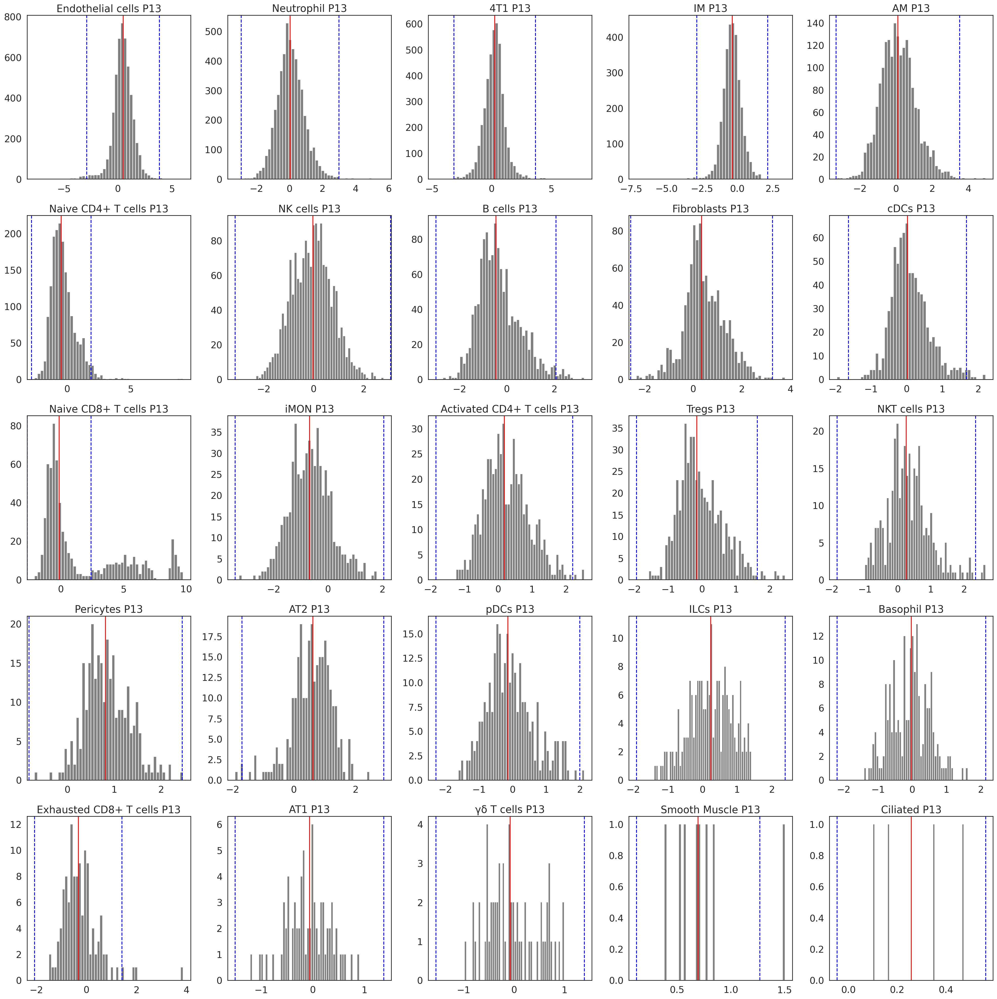

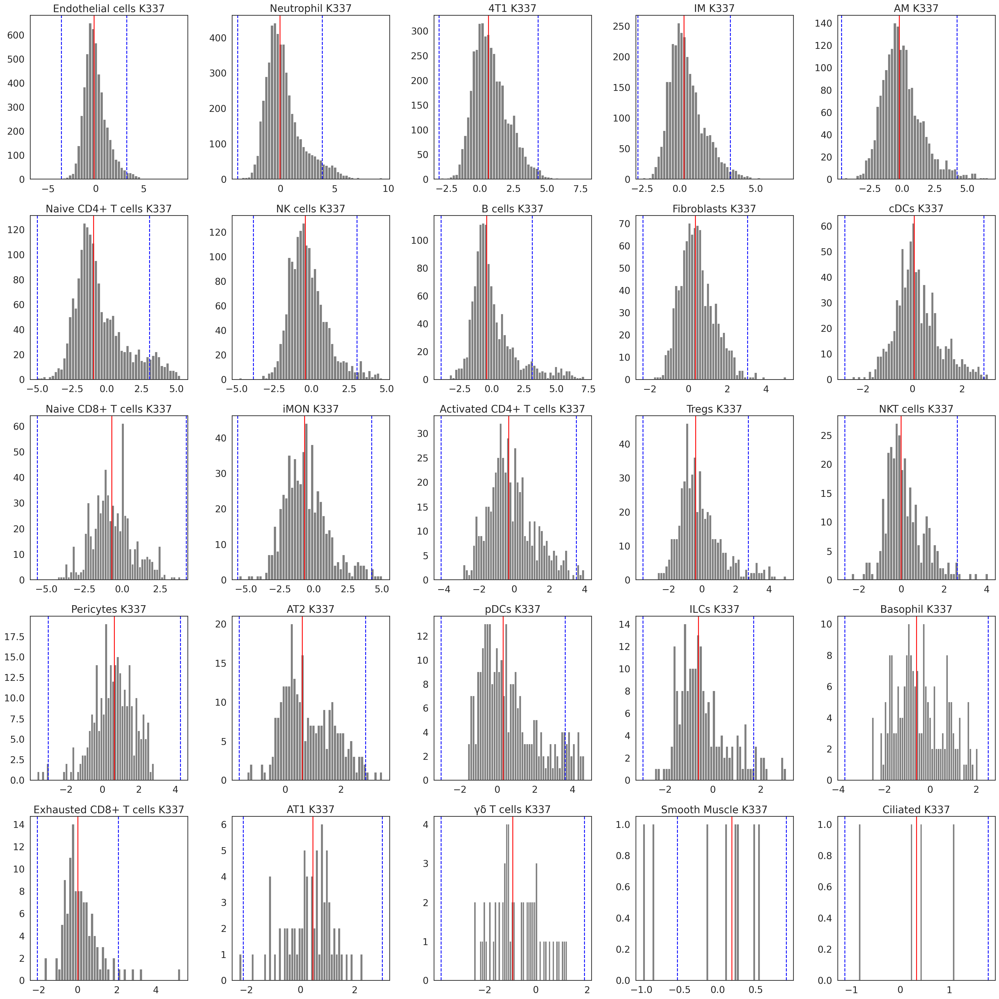

In [181]:
for var in ['P13', 'K337']:
    nrows=5
    ncols=5
    fig, ax = plt.subplots(nrows=nrows, ncols=ncols, figsize=(ncols*5, nrows*5))
    df[f'outlier_direction_sub_{var}']  = 'none'
    for i,celltype in enumerate(df['celltype_sub'].value_counts().index):
        dvar=f'delta_{var}'
        ax = plt.subplot(nrows, ncols, i+1)
        f = df['celltype_sub'] == celltype
        if sum(f) == 0:
            continue
        plt.hist(df.loc[f,dvar], bins=50, color='gray')
        #plt.axvline(np.mean(df.loc[f,'delta']), color='red')
        median = np.median(df.loc[f,dvar])
        plt.axvline(median, color='red')
        q1 = np.quantile(df.loc[f,dvar], 0.025)
        q2 = np.quantile(df.loc[f,dvar], 0.975)
        #plt.axvline(q1, color='black')
        #plt.axvline(q2, color='black')
        qdiff2 = q2 - median
        qdiff1 = median - q1
        if qdiff1 < qdiff2:
            q2 = median + qdiff1*2
            q1 = median - qdiff1*2
        else:
            q2 = median + qdiff2*2
            q1 = median - qdiff2*2
        plt.axvline(q1, color='blue', linestyle='--')
        plt.axvline(q2, color='blue', linestyle='--')
        f2 = (f) & (df[dvar] < q1)
        df.loc[f2,f'outlier_direction_sub+{var}'] = 'below'
        f2 = (f) & (df[dvar] > q2)
        df.loc[f2,f'outlier_direction_sub_{var}'] = 'above'
        plt.title(f'{celltype} {var}')
        #plt.yscale('log')
    plt.tight_layout()
    plt.show()

In [182]:
celltype_colors['Mixed'] = 'black'

Neutrophil 7.716410969086886
Endothelial cells 8.805801461087587
4T1 5.1559663367597555
T cells 10.191527217678773
IM 6.877573269202703
Mixed 7.808257770903943
AM 5.562648376713286
NK cells 3.0122009592050754
B cells 4.9134820450066234
Fibroblasts 5.605254929883477
cDCs 2.609181542105171
pDCs 3.144664744107953
Pericytes 3.2995455414700023
AT2 2.668897665226892
Basophil 2.028028007821585
ILC 2.8897665687152903
iMON 3.066073229450814
AT1 1.3106410730470202


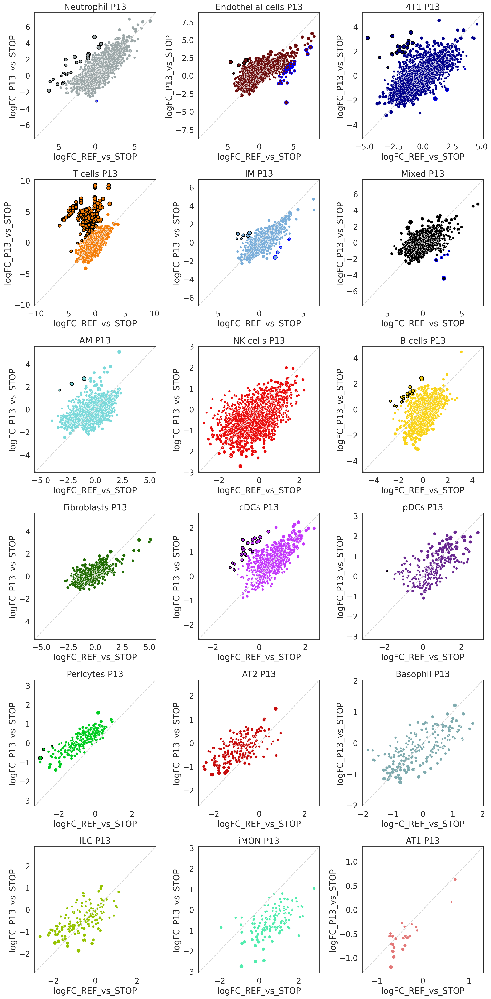

Neutrophil 10.619206157751236
Endothelial cells 10.069545391551701
4T1 10.195085717836747
T cells 6.703168117853383
IM 9.962523881216853
Mixed 9.81811735065929
AM 6.876170593014053
NK cells 5.997088384138028
B cells 10.217721989160038
Fibroblasts 6.926427248735248
cDCs 3.5412443534247124
pDCs 5.774132867142321
Pericytes 4.318183091288485
AT2 2.758445883961097
Basophil 3.4561595404200265
ILC 3.8687918157417105
iMON 6.214825507563838
AT1 1.4796607769905832


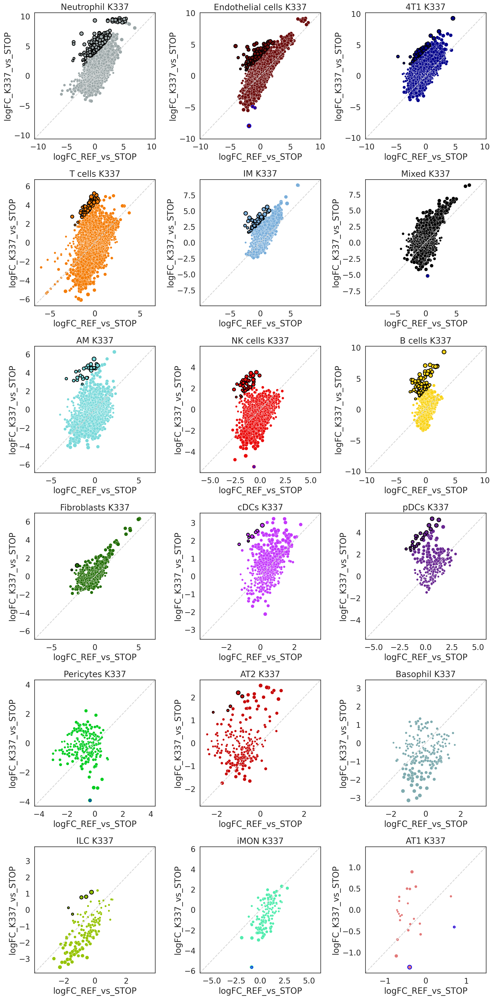

Fibroblasts 6.926427248735248
cDCs 3.5412443534247124
pDCs 5.774132867142321
Pericytes 4.318183091288485
AT2 2.758445883961097
Basophil 3.4561595404200265


ILC 3.8687918157417105
iMON 6.214825507563838
AT1 1.4796607769905832


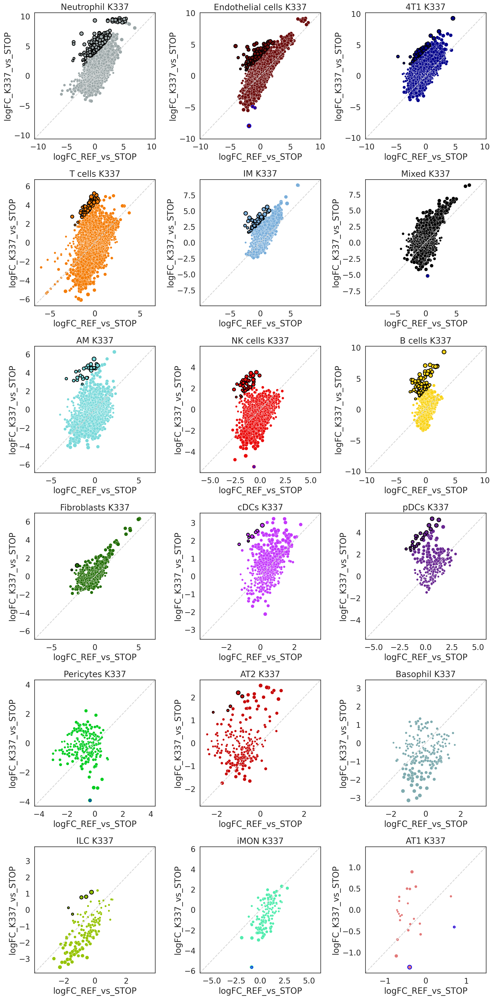

In [183]:
for var in ['P13', 'K337']:
    nrows=6
    ncols=3
    df['size'] = -np.log10(df[f'PValue_{var}_vs_STOP'])
    fig, ax = plt.subplots(nrows=nrows, ncols=ncols, figsize=(ncols*5, nrows*5))
    for i,celltype in enumerate(df['celltype'].value_counts().index):
        ax = plt.subplot(nrows, ncols, i+1)
        f = df['celltype'] == celltype
        if sum(f) == 0:
            continue
        #sns.scatterplot(data=df.loc[f], x='logFC_STOP_vs_REF', y='logFC_P13_vs_REF', color=celltype_colors[celltype], ax=ax, size='size', legend=False)
        sns.scatterplot(data=df.loc[f], x='logFC_REF_vs_STOP', y=f'logFC_{var}_vs_STOP', color=celltype_colors[celltype], ax=ax, size='size', legend=False)
        #sns.scatterplot(data=df.loc[f], x='logFC_REF_vs_STOP', y='logFC_P13_vs_STOP', hue='logFC_P13_vs_STOP', palette='bwr', hue_norm=(-4, 4), ax=ax, size='size', legend=False)
        #f2  = (f) & (df['PValue_P13_vs_STOP'] < 0.01) #& (df['logFC_STOP_vs_REF']*df['logFC_P13_vs_REF'] < 0)
        #f2  = (f) & (df['PValue_P13_vs_STOP'] < 0.05)# & (df['PValue_P13_vs_REF'] < 0.05)
        f2 = (f) & (df[f'outlier_direction_{var}'] == 'above')
        #print(sum(f2))
        sns.scatterplot(data=df.loc[f2], x='logFC_REF_vs_STOP', y=f'logFC_{var}_vs_STOP',  color=celltype_colors[celltype], ax=ax, size='size', legend=False, edgecolor='black', linewidth=1.5)
        f2 = (f) & (df[f'outlier_direction_{var}'] == 'below')
        sns.scatterplot(data=df.loc[f2], x='logFC_REF_vs_STOP', y=f'logFC_{var}_vs_STOP',  color=celltype_colors[celltype], ax=ax, size='size', legend=False, edgecolor='blue', linewidth=1.5)
        #sns.scatterplot(data=df.loc[f2], x='logFC_REF_vs_STOP', y='logFC_P13_vs_STOP', color=celltype_colors[celltype], ax=ax, size='size', legend=False, edgecolor='black', linewidth=1.5)
        ax.set_title(f'{celltype} {var}')
        #ax.set_xlabel(f'logFC_{cond1a}_vs_REF')
        #ax.set_ylabel(f'logFC_{cond1b}_vs_REF')
        maxval = np.max(np.abs(df.loc[f, ['logFC_REF_vs_STOP', f'logFC_{var}_vs_STOP']]))*1.1
        print(celltype, maxval)
        plt.axline((0, 0), slope=1, color='lightgray', linestyle='--')
        #plt.axvline(0, color='lightgray', linestyle='--')
        #plt.axhline(0, color='lightgray', linestyle='--')
        ax.set_xlim(-maxval, maxval)
        ax.set_ylim(-maxval, maxval)
    plt.tight_layout()
    plt.show()

In [184]:
for k, value in cell_subtype_cmap.items():
    if k not in celltype_colors:
        celltype_colors[k] = value

In [185]:
df['Nhood'] = df.index.astype(int)

In [186]:
cells_by_nhood = (
    nh_long
    .groupby("Nhood")["cell"]
    .apply(set)
    .to_dict()
)

In [187]:
for var in ['P13', 'K337']:
    print(df[f'outlier_direction_{var}'].value_counts())

outlier_direction_P13
none     29482
above      330
below       52
Name: count, dtype: int64
outlier_direction_K337
none     29136
above      719
below        9
Name: count, dtype: int64


In [188]:
from itertools import combinations

import networkx as nx
import pandas as pd


def combine_overlapping_nhoods(
    selected_nhoods,
    nh_long,
    jaccard_cutoff=0.05,
    min_shared_cells=1,
):
    """
    Combine neighborhoods based only on shared cells.

    Parameters
    ----------
    selected_nhoods : list-like
        Neighborhood IDs to consider for merging.

    nh_long : pandas.DataFrame
        Long-format neighborhood membership table with columns:
        'cell' and 'Nhood'.

    jaccard_cutoff : float
        Minimum Jaccard overlap required to connect two neighborhoods.
        Jaccard = shared cells / union of cells.

    min_shared_cells : int
        Minimum number of shared cells required to connect two neighborhoods.

    Returns
    -------
    regions : pandas.DataFrame
        One row per selected neighborhood, with columns:
        Nhood, region
    """

    selected_nhoods = [int(x) for x in selected_nhoods]

    nh_sub = nh_long[nh_long["Nhood"].isin(selected_nhoods)].copy()
    nh_sub["Nhood"] = nh_sub["Nhood"].astype(int)

    cells_by_nhood = (
        nh_sub
        .groupby("Nhood")["cell"]
        .apply(set)
        .to_dict()
    )

    G = nx.Graph()
    G.add_nodes_from(selected_nhoods)

    for a, b in combinations(selected_nhoods, 2):
        cells_a = cells_by_nhood.get(a, set())
        cells_b = cells_by_nhood.get(b, set())

        if not cells_a or not cells_b:
            continue

        shared = len(cells_a & cells_b)

        if shared < min_shared_cells:
            continue

        union = len(cells_a | cells_b)
        jaccard = shared / union

        if jaccard > jaccard_cutoff:
            G.add_edge(a, b, jaccard=jaccard, shared_cells=shared)

    rows = []

    for region_id, component in enumerate(nx.connected_components(G), start=1):
        for nhood in component:
            rows.append({
                "Nhood": nhood,
                "region": f"region_{region_id}"
            })

    regions = pd.DataFrame(rows)

    return regions

In [189]:
for var in ['P13', 'K337']:
    f = df[f'outlier_direction_{var}'] == 'above'
    above_regions = combine_overlapping_nhoods(df.loc[f,'Nhood'], nh_long, jaccard_cutoff=0)
    f = df[f'outlier_direction_{var}'] == 'below'
    below_regions = combine_overlapping_nhoods(df.loc[f,'Nhood'], nh_long, jaccard_cutoff=0)
    
    for dir in ['above', 'below']:
        cname=f'{dir}_region_{var}'
        adata.obs[cname] = None
        if dir == 'above':
            regions = above_regions.copy()
        else:
            regions = below_regions.copy()
        for i in regions.index:
            nhood=regions.loc[i,'Nhood']
            rname=regions.loc[i,'region']
            cells = list(cells_by_nhood[nhood])
            f = (~adata.obs.loc[cells,cname].isna()) & (adata.obs.loc[cells,cname] != rname)
            if sum(f) != 0:
                print('Got overlapping regions')
                break
            adata.obs.loc[cells,cname] = rname


/tmp/ipykernel_58269/3348498595.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  adata.obs[cname] = None
/tmp/ipykernel_58269/3348498595.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  adata.obs[cname] = None
/tmp/ipykernel_58269/3348498595.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#r

/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1301: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[key] = c
/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1301: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[key] = c
/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1301: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentati

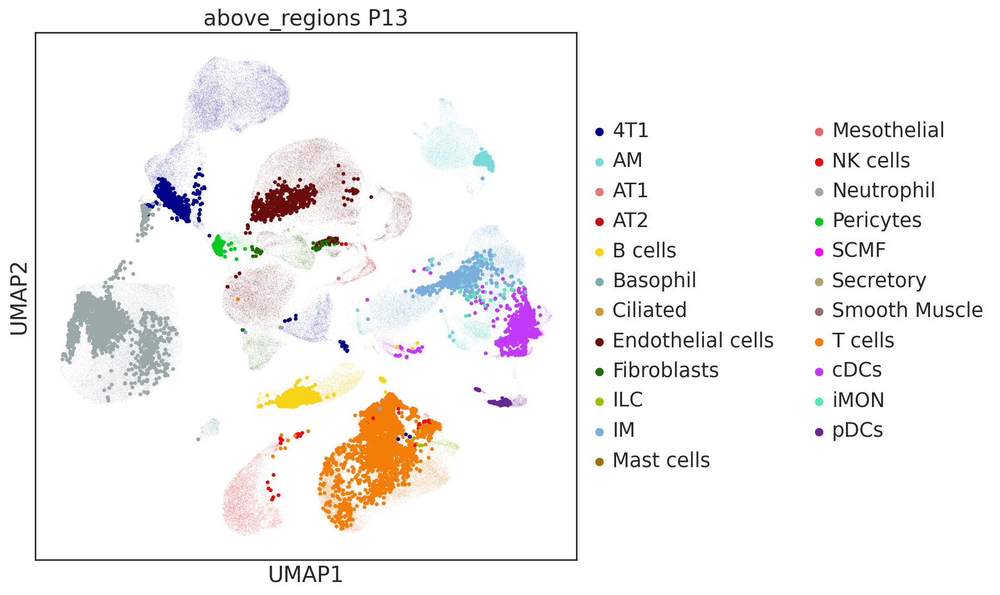

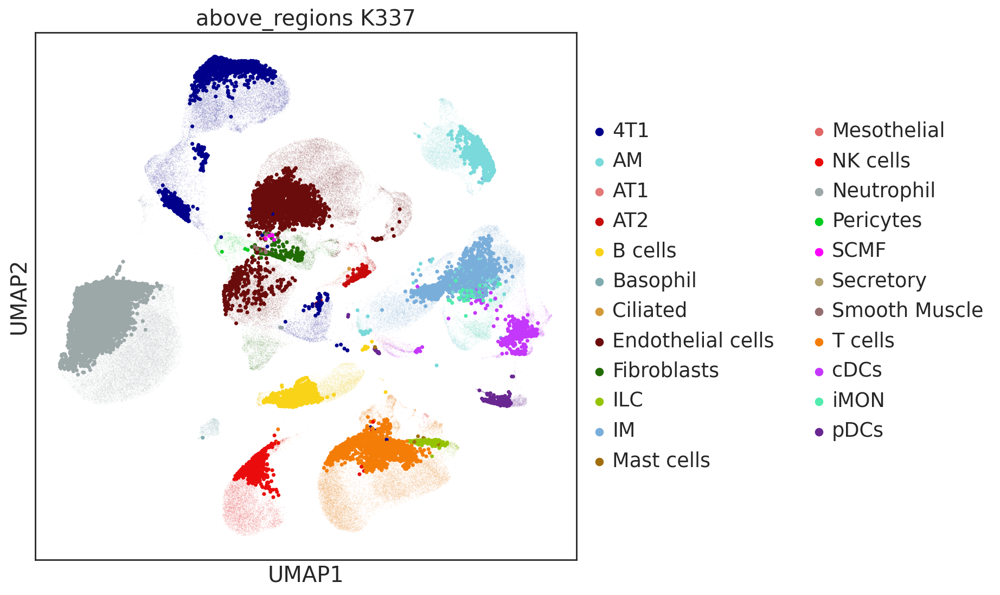

In [190]:
for var in ['P13', 'K337']:
    fig, ax = plt.subplots(figsize=(8, 8))
    sc.pl.umap(adata, color='Macro Cell Type 4', ax=ax, show=False, alpha=0.1, s=2, title=f'above regions {var}')
    f = ~adata.obs[f'above_region_{var}'].isna()
    sc.pl.umap(adata[f], color='Macro Cell Type 4', ax=ax, show=True, legend_loc=None, s=40, title=f'above_regions {var}')

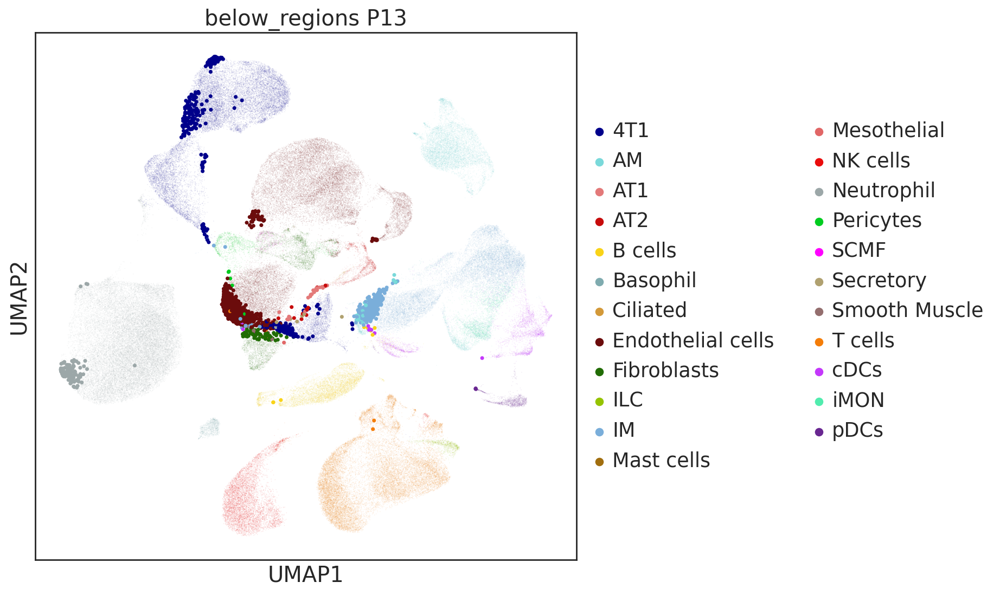

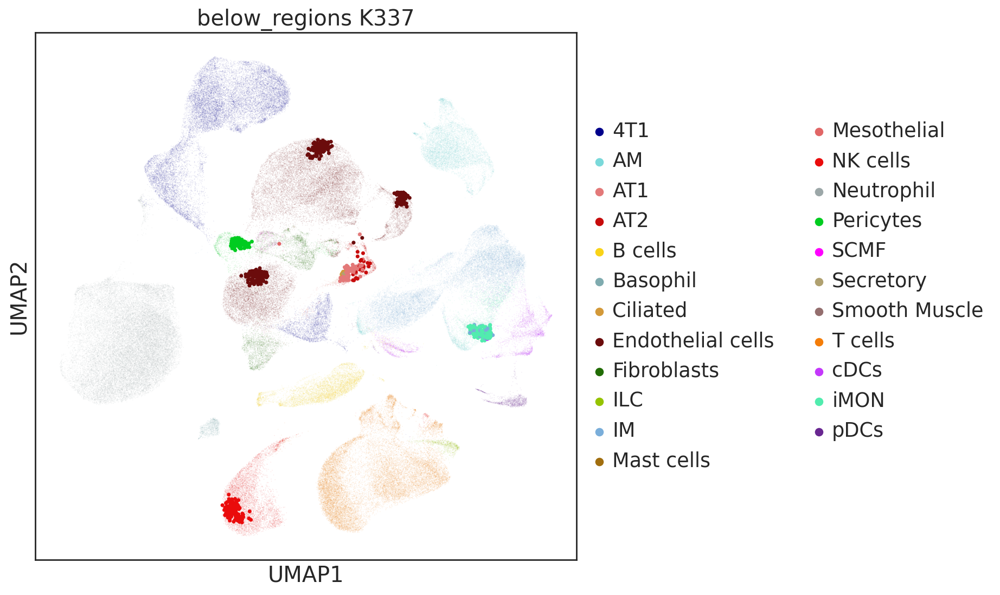

In [191]:
for var in ['P13', 'K337']:
    fig, ax = plt.subplots(figsize=(8, 8))
    sc.pl.umap(adata, color='Macro Cell Type 4', ax=ax, show=False, alpha=0.1, s=2, title=f'below regions {var}')
    f = ~adata.obs[f'below_region_{var}'].isna()
    sc.pl.umap(adata[f], color='Macro Cell Type 4', ax=ax, show=True, legend_loc=None, s=40, title=f'below_regions {var}')

In [192]:
df['outlier_direction_P13'].value_counts()

outlier_direction_P13
none     29482
above      330
below       52
Name: count, dtype: int64

In [193]:
cell_type_name_map = {'Fibroblasts': 'Fibroblast cells',
                      'AM': 'Alveolar macrophages', 
                      'Smooth Muscle': 'Smooth muscle', 
                      'AT1': 'AT1', 
                      'AT2': 'AT2', 
                      'B cells': 'B cells',
                      'Plasma cells': 'Plasma cells',
                      'Basal cells': 'Basal cells', 
                      'Basophil': 'Basophils', 
                      'T cells': 'T cells',
                      'cDCs': 'DCs', 
                      'DCs': 'DCs', 
                      'pDCs': 'pDCs',
                      'Chondrocyte': 'Chondrocytes', 
                      'Ciliated': 'Ciliated cells', 
                      'Deuterosomal': 'Deuterosomal cells',
                      'ILC': 'ILC', 
                      'IM': 'Interstitial macrophages', 
                      'iMON': 'Monocytes', 
                      'LEC': 'Lymphatic EC', 
                      'Mast cells': 'Mast cells', 
                      'Platelet': 'Platelets',
                      'Mesothelial': 'Mesothelium',
                      'Neutrophil': 'Neutrophils',
                      'Granulocytic cells': 'Granulocytic cells',
                      'NK cells': 'NK cells',
                      'Pericytes': 'Pericytes',
                      'PNEC': 'PNEC',
                      'SCMF': 'Myofibroblasts', 
                      'Secretory': 'Secretory cells',
                      'Endothelial cells': 'Endothelial cells', 
                      'unassigned': 'unassigned'}


In [194]:
for x in df['celltype'].value_counts().index:
    if x == 'Mixed' or x=='4T1':
        continue
    if x not in cell_type_name_map:
        print('error')
        break
    if x != cell_type_name_map[x]:
        print(x, cell_type_name_map[x])

Neutrophil Neutrophils
IM Interstitial macrophages
AM Alveolar macrophages
Fibroblasts Fibroblast cells
cDCs DCs
Basophil Basophils
iMON Monocytes


## Figure 4F

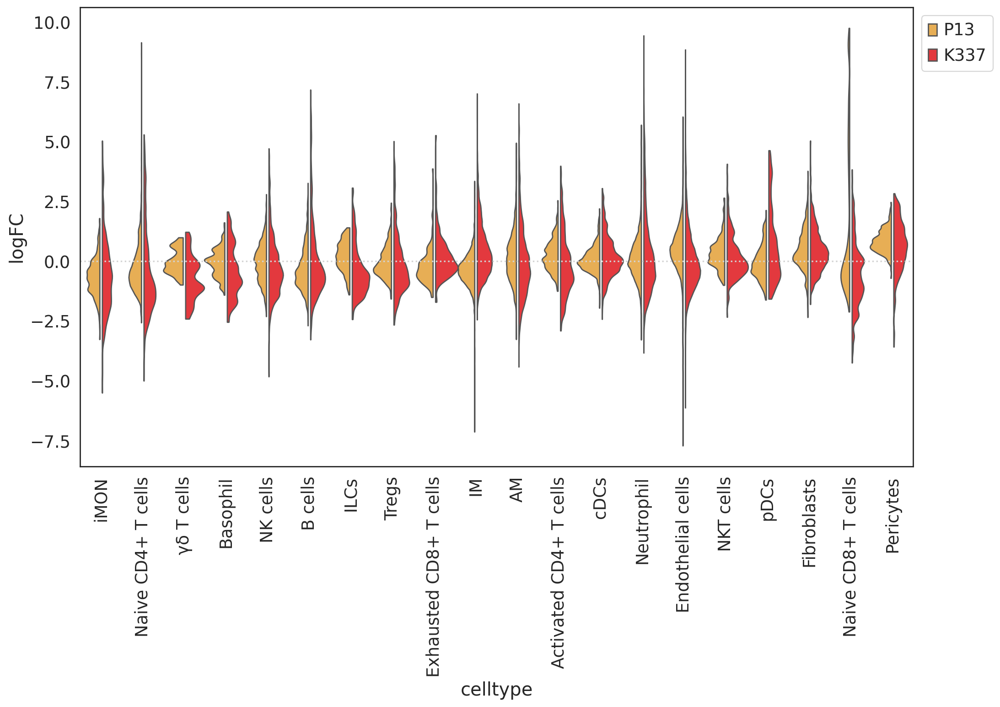

In [195]:
sns.set_style('white')

# keep only desired cell types
f0 = ~df['celltype_sub'].isin(['4T1', 'Mixed', 'AT1', 'AT2'])

# build long-format dataframe
d1 = df.loc[f0, ['celltype_sub', 'logFC_P13_vs_REF', 'outlier_direction_sub_P13']].copy()
d1 = d1.rename(columns={
    'celltype_sub':'celltype',
    'logFC_P13_vs_REF': 'logFC',
    'outlier_direction_sub_P13': 'outlier_direction'
})
d1['var'] = 'P13'

d2 = df.loc[f0, ['celltype_sub', 'logFC_K337_vs_REF', 'outlier_direction_sub_K337']].copy()
d2 = d2.rename(columns={
    'celltype_sub':'celltype',
    'logFC_K337_vs_REF': 'logFC',
    'outlier_direction_sub_K337': 'outlier_direction'
})
d2['var'] = 'K337'

longdf = pd.concat([d1, d2], ignore_index=True)

num_nhoods = longdf['celltype'].value_counts()
remove_celltypes = list(num_nhoods[num_nhoods < 20].index)
longdf = longdf.loc[~longdf['celltype'].isin(remove_celltypes)]

df['sumlogFC'] = df['logFC_P13_vs_REF'] + df['logFC_K337_vs_REF']

# compute cell type order from one condition, as before
ct_order = list(
    df.loc[f0 & (~df['celltype_sub'].isin(remove_celltypes)), ['celltype_sub', 'sumlogFC']]
      .groupby('celltype_sub', observed=True)
      .mean()
      .sort_values(by='sumlogFC')
      .index
)

palette = {'K337': '#ff1d24', 'P13': '#ffb33d'}

plt.figure(figsize=(14, 10))

ax = sns.violinplot(
    data=longdf,
    x='celltype',
    y='logFC',
    hue='var',
    order=ct_order,
    hue_order=['P13', 'K337'],   # swap if top/bottom come out reversed
    split=True,
    inner=None,
    cut=0,
    bw_adjust=0.5,
    density_norm='area',
    palette=palette, gap=0.1, width=1.2
)

# overlay only outliers
outliers = longdf[longdf['outlier_direction'].isin(['above', 'below'])].copy()


ax.axhline(0.0, color='lightgray', linestyle=':')

# clean up duplicated legends (one from violinplot, one from stripplot)
handles, labels = ax.get_legend_handles_labels()
seen = set()
new_handles = []
new_labels = []
for h, l in zip(handles, labels):
    if l not in seen:
        new_handles.append(h)
        new_labels.append(l)
        seen.add(l)

ax.legend(new_handles, new_labels, title=None, loc='best')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.xticks(rotation=90)

plt.tight_layout()
plt.savefig('lungmet_violin_subtypes_no_outliers.png', bbox_inches='tight', dpi=300)
plt.savefig('lungmet_violin_subtypes_no_outliers.svg', bbox_inches='tight')
plt.show()

## Mast vs REF in each cell type

In [196]:
Rcommand='MKL_NUM_THREADS=1 OPENBLAS_NUM_THREADS=1 OMP_NUM_THREADS=1 R'

In [197]:
adata.obs['Macro Cell Type 4'].value_counts()

Macro Cell Type 4
Endothelial cells    25357
Neutrophil           25356
4T1                  20975
T cells              20373
IM                   15346
AM                   10145
NK cells              7305
B cells               6328
Fibroblasts           4441
cDCs                  3841
iMON                  2591
Pericytes             1504
AT2                   1328
pDCs                  1298
Basophil               916
ILC                    853
Smooth Muscle          492
AT1                    401
SCMF                   218
Mesothelial             94
Ciliated                73
Mast cells              55
Secretory               33
Name: count, dtype: int64

In [198]:
numCore=4

In [199]:
# This prints the commands to run MAST on genotype1 vs genotype2 in each cell type
with open('mast_commands.sh', 'w') as cmdfile:
    for celltype in adata.obs['Macro Cell Type 4'].unique():
        for cond1 in ['REF', 'K337', 'P13']: 
            for cond2 in ['STOP', 'REF']: 
                if cond1 == cond2: 
                    continue
                #print(cond1, cond2)
                f = (adata.obs['Macro Cell Type 4'] == celltype)
                f1 = (f) & (adata.obs['condition']== cond1)
                f2 = (f) & (adata.obs['condition'] == cond2)
                if sum(f1) < 10:
                    continue
                if sum(f2) < 10:
                    continue
                f = f1 | f2
                tmpadata = sc.AnnData(adata[f].X,
                                  obs=adata.obs.loc[f,['sample', 'library_size', 'mt_frac', 'condition']], 
                                  var=adata.var)
                tmpadata.layers['logX'] = tmpadata.X
                ct0=celltype.replace(' ', '_')
                mast_infile=f'NOBACKUP/MAST_input/{ct0}_{cond1}_{cond2}_for_MAST.h5ad'
                #if not os.path.exists(mast_infile):
                tmpadata.write(mast_infile)
                mast_outdir=f'data/MAST_celltype/{ct0}_{cond1}_{cond2}'
                !mkdir -p {mast_outdir}
                cmd=f'{Rcommand} --vanilla --args --infile "{mast_infile}" --outdir "{mast_outdir}/" --groups "condition"'
                cmd += f' --covariates cngeneson --numcore {numCore} --comp-groups {cond1} {cond2} --force'
                cmd += ' < MAST_wrapper.R'
                cmdfile.write(cmd)
                


In [200]:
# If you want to actually run the commands above, change this to True and run, or else execute in docker container
# Will take several hours and a lot of CPU/RAM on powerful server
if False:
    !parallel -j 4 < mast_commands.sh
else:
    print('Will read pre-computed results from repository')

Will read pre-computed results from repository


In [201]:
# copied from contactTracing library

def read_mast_results(filename, reverse=False, sortBy='scaled_rank_score', quiet=False, minpval=1e-240):
    """Load results created by MAST_wrapper.R
    :param filename: The filename containing the results
    :param reverse: If True, flip direction of fold-change parameters
    :param sortBy: parameter to sort results by, should be a column of the results
    :param quiet: If True, suppress verbose output
    :param minpval: Any p-value less than this is set to this value
    :return: data frame with columns including gene,log2FC,p,bonferroni,fdr,rank_score,scaled_rank_score
    """
    if not quiet:
        print("Reading " + filename)
    mastResults = pd.read_csv(filename)
    mastResults.rename(index=str, columns={"primerid": "gene", "coef": "log2FC", 'Pr(>Chisq)':'p',
                                          'Pr..Chisq.':'p'}, inplace=True, errors='ignore')
    mastResults['p'] = mastResults['p'].astype('float')
    mastResults['log2FC'] = mastResults['log2FC'].astype('float')
    mastResults['fdr'] = mastResults['fdr'].astype('float')
    #mastResults.log2FC[np.isnan(mastResults.log2FC)] = np.nanmax(mastResults.log2FC)
    mastResults.drop(['Unnamed: 0'], axis=1, inplace=True)
    mastResults.set_index('gene', drop=True, inplace=True)
    mastResults['bonferroni'] = mastResults['p']*mastResults.shape[0]
    mastResults.loc[mastResults.p < minpval,'p'] = minpval
    mastResults.loc[mastResults.fdr < minpval,'fdr'] = minpval
    mastResults.loc[mastResults.bonferroni< minpval,'bonferroni'] = minpval
    mastResults.loc[mastResults.bonferroni > 1,'bonferroni'] = 1
    mastResults['rank_score'] = -10*np.log10(mastResults['bonferroni'])*np.sign(mastResults['log2FC'])
    mastResults['FC'] = 2.0**mastResults['log2FC']
    mastResults['scaled_rank_score'] = mastResults['rank_score']*np.abs(mastResults['log2FC'])
    mastResults['abs_scaled_rank_score'] = np.abs(mastResults['scaled_rank_score'])
    if reverse:
        mastResults['log2FC'] = -mastResults['log2FC']
        mastResults['FC'] = 1.0/mastResults['FC']
        mastResults['ci.hi'] = -mastResults['ci.hi']
        mastResults['ci.lo'] = -mastResults['ci.lo']
        mastResults['rank_score'] = -mastResults['rank_score']
        mastResults['scaled_rank_score'] = -mastResults['scaled_rank_score']
    mastResults = mastResults.sort_values(by=sortBy, ascending=False)
    return(mastResults)


def run_in_background(command, stdoutfile, stderrfile="",
                      force=True, wait=False, quiet=False):
    """Run a system command
    :param command: A string with the command to run
    :param stdoutfile: A string with file name where stdout will be written
    :param stderrfile: A string with file name where stderr will be written. If "", then combine stdout/stderr to stdoutfile
    :param force: If False, do not run command if stdoutfile already exists. If True, command will be run and stdoutfile will be overwritten (if it already exists)
    :param wait: If True, then function will not return until command is finished running. Otherwise, the function will issue the command to run in the background and then return.
    :param quiet: If False, print contents of stdoutfile and stderrfile to console after command is finished (only if wait=True)
    :return: None
    """
    if force or not os.path.exists(stdoutfile):
        command = 'bash -c \'' + command + '\' > ' + stdoutfile
        if stderrfile:
            command = command + ' 2>' + stderrfile
        else:
            command = command + ' 2>&1'
        if not wait:
            command = command + ' &'
        if not quiet:
            print('calling ' + command + '\n')
        os.system(command)
    else:
        wait=True
    if wait:
        if not quiet:
            print("Output from stdout file " + stdoutfile)
            get_ipython().system('cat {stdoutfile}')
        if stderrfile and os.path.exists(stderrfile):
            print("Output from stderr file " + stderrfile)
            get_ipython().system('cat {stderrfile}')


def run_gsea(rank, output_root, gmtfile, fdr_cutoff=0.25, label='GSEA run', force=False, wait=False,
             return_command_only=False, readonly=False, gene_map=None, quiet=False, fix_dup_mappings=None):
    """Run GSEA
    :param rank: pd.Series object with score for each gene
    :param output_root: Directory output
    :param gmtfile: Path to GMT file
    :param fdr_cutoff: If returning results, only return results with fdr < fdr_cutoff
    :param label: Name to use (results will be in f'{output_dir}/{label}.csv'. Spaces will be replaced by underscores.
    :param force: If True, run GSEA even if results file already exists.
    :param wait: If True, wait for GSEA to finish running, and return results. Otherwise, start GSEA running, and return None.
    :param return_command_only: If True, return the command to run GSEA on command-line. Otherwise, run the command from the function.
    :param readonly: If True, do not run the command, just read results (from previously run commands).
    :param gene_map: If not None, this should be a dictionary used to convert gene names in rank to gene names in the GMT file. (i.e. to convert between different species gene names). If gene_map is given, it assumes that we are converting to human gene names (all caps) and converts all gene names to all caps, unless the gene mapping is specified in gene_map. If gene_map is None, the given gene names in rank are used and assumed to match with those in the GMT file.
    :param fix_dup_mappings If provided, the gmt file should be one produced by fix_gmt_dups, and fix_dup_mappings should be the list of genes returned by fix_gmt_dups. Then, if any genes get mapped to the same name with gene_map, they will be renamed to gene.0, gene.1, etc. The fix_gmt_dups function does this for the GMT file, this argument does it for the score file. Ignored if gene_map is None.
    :return: data frame with GSEA Results
    """
    label = label.replace(" ", "_")

    # look to see if output folder already exists
    f = glob.glob(output_root + "/**/*gsea_report*pos*tsv", recursive=True)
    if return_command_only and not force:
        if len(f):
            return None
    if force or len(f)==0:
        if not readonly:
            Path(output_root).mkdir(parents=True, exist_ok=True)
        rnkFile=f'{output_root}/input.rnk'
        if rank is not None:
            if gene_map is not None:
                rank = pd.DataFrame(rank)
                rank['hgene'] = [('' if i.upper() in gene_map.values() else i.upper())
                                 if i not in gene_map else gene_map[i] for i in rank.index]
                droprows = (rank['hgene'] == '')
                if not quiet:
                    print(f'Dropping {sum(droprows)} results with no human gene mapping')
                rank = rank.loc[~droprows]
                rank.set_index('hgene', inplace=True)
                if fix_dup_mappings is not None:
                    rankcount = rank.index.value_counts()
                    rankcount = rankcount[rankcount > 1]
                    rank['count'] = ''
                    for i in rankcount.index:
                        rank.loc[i,'count'] = ['.'+str(j) for j in range(rankcount[i])]
                    rank['newidx'] = rank.index + rank['count']
                    # It's possible that we fixed a duplicate in GMT file but it exists only once in the scores, in this case
                    # we want to rename it to gene.0 so that it mathces the GMT
                    for h in fix_dup_mappings.index:
                        f = rank['newidx'] == h
                        if sum(f) == 1:
                            rank.loc[f,'newidx'] = h + '.0'
                        elif sum(f) > 1:
                            print('Error fixing dups, check')  # shouldn't happen
                            break
                    rank = rank.set_index('newidx', drop=True).drop(columns='count')
            #else:
            #    rank.index = [i.upper() for i in rank.index]
            if not readonly:
                rank.to_csv(rnkFile, sep='\t', header=False, index=True)
        cmd=f'/opt/GSEA_Linux_4.3.3/gsea-cli.sh GSEAPreranked -rnk "{rnkFile}" -gmx "{gmtfile}" -collapse No_Collapse -mode Max_probe -norm meandiv'
        cmd += f' -nperm 10000 -scoring_scheme weighted -rpt_label "{label}" -create_svgs true -include_only_symbols true'
        cmd += f' -make_sets true -plot_top_x 20 -rnd_seed 888 -set_max 1500 -set_min 1 -zip_report false -out "{output_root}"'
        if return_command_only:
            return(cmd)
        if not readonly:
            run_in_background(cmd,f'"{output_root}/{label}_stdout.txt"',  wait=wait, force=force, quiet=True)
        if not wait:
            return(None)
    # recover information from run
    f = glob.glob(output_root + "/**/*gsea_report*pos*tsv", recursive=True)
    #print(f, output_root + "/**/*gsea_report*pos*tsv")
    if f is None or len(f) == 0:
        if readonly:
            return None
        raise RuntimeError(
            'seqc.JavaGSEA was not able to recover the output of the Java '
            'executable. This likely represents a bug.')
    f.sort(key=os.path.getmtime)
    f = f[-1]
    f2 = f.replace('_pos_', '_neg_')
    if not os.path.exists(f2):
        raise RuntimeError("Error finding neg result file for GSEA " + f2)
    names = ['name', 'size', 'es', 'nes', 'p', 'fdr_q', 'fwer_p', 'rank_at_max', 'leading_edge']
    if not quiet:
        print(f'Reading positive GSEA results rom {f}')
    pos = pd.read_csv(f, sep='\t', parse_dates=False).iloc[:, :-1]
    pos.drop(['GS<br> follow link to MSigDB', 'GS DETAILS'], axis=1, inplace=True)

    neg = pd.read_csv(f2, sep='\t', parse_dates=False).iloc[:, :-1]
    if not quiet:
       print(f'Reading negative GSEA results rom {f2}')
    neg.drop(['GS<br> follow link to MSigDB', 'GS DETAILS'], axis=1, inplace=True)
    pos.columns, neg.columns = names, names
    pos['direction'] = 'pos'
    neg['direction'] = 'neg'

    aa = pos.sort_values('fdr_q', ascending=True).fillna(0)
    bb = neg.sort_values('fdr_q', ascending=True).fillna(0)
    aa = aa[aa['fdr_q'] <= fdr_cutoff]
    bb = bb[bb['fdr_q'] <= fdr_cutoff]
    outcsv = f'{output_root}/{label}.csv'.replace(' ', '_')
    aa.to_csv(outcsv, sep='\t', index=False)
    with open(outcsv, 'a') as f:
        f.write('\n')
    bb.to_csv(outcsv, sep='\t', index=False, mode='a')
    rv = pd.concat([pos, neg])
    f = rv['nes'] == '---'
    rv.loc[f,'nes'] = 0
    rv['nes'] = rv['nes'].astype(np.float64)
    return(rv)


In [202]:
# infile should be csv file
def my_read_mast_results(infile, minfdr=1.0):
    if not os.path.exists(infile):
        print(f'{infile} not found ... skipping') 
    df = read_mast_results(infile)
    
    df = df.loc[df['fdr'] < minfdr].copy()
    numna = np.sum(pd.isna(df['log2FC']))
    if numna > 0:
        print(f'WARNING: {sum(numna)} values for leiden {l}')
    f = np.abs(df['log2FC']) < 9999
    maxval = np.max(np.abs(df.loc[f,'log2FC']))
    f = df['log2FC'] > 9999
    df.loc[f,'log2FC'] = maxval
    f = df['log2FC'] < -9999
    df.loc[f,'log2FC'] = -maxval
    
    df['logfdr'] = -np.log10(df['fdr'])
    df['abs_score'] = np.abs(df['logfdr']*df['log2FC'])
    df['score'] = (df['logfdr']*df['log2FC'])
    return df.sort_values(by='abs_score', ascending=False)

Reading data/MAST_celltype/T_cells_REF_STOP/REF_vs_STOP.csv


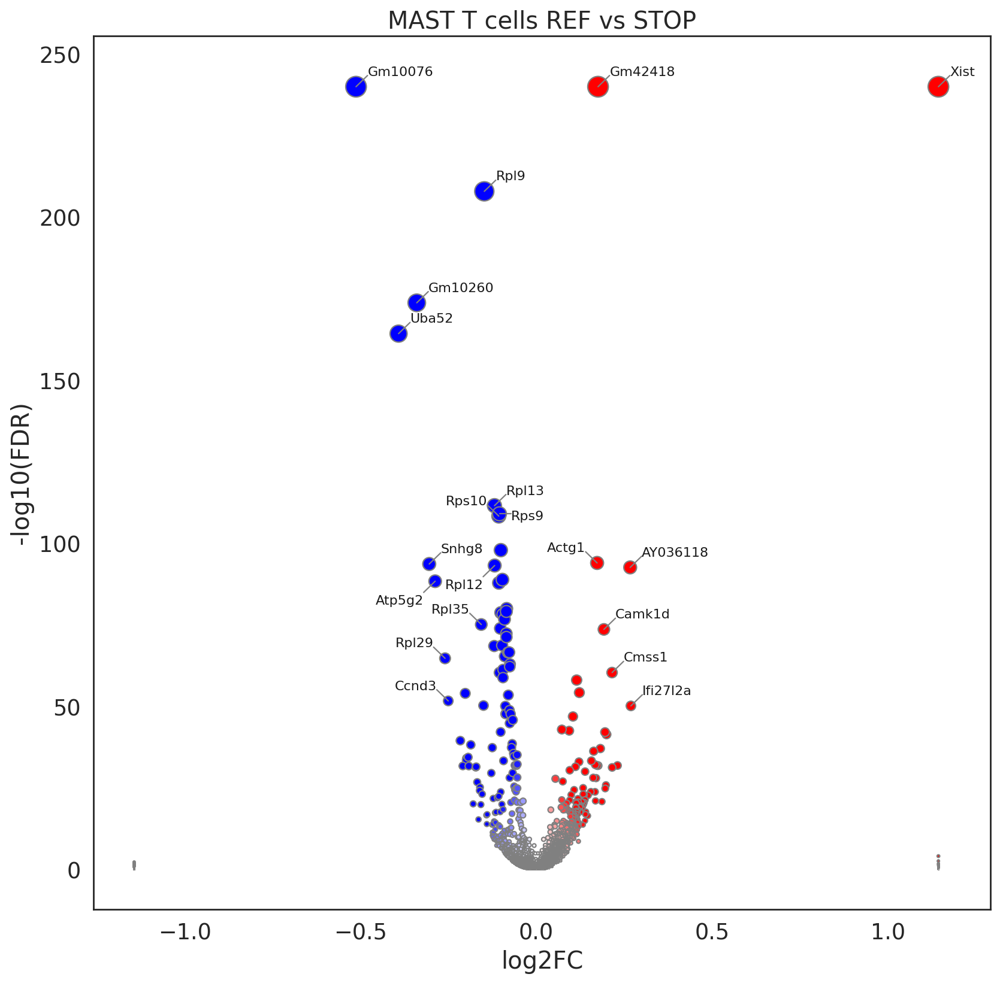

Reading data/MAST_celltype/T_cells_K337_STOP/K337_vs_STOP.csv


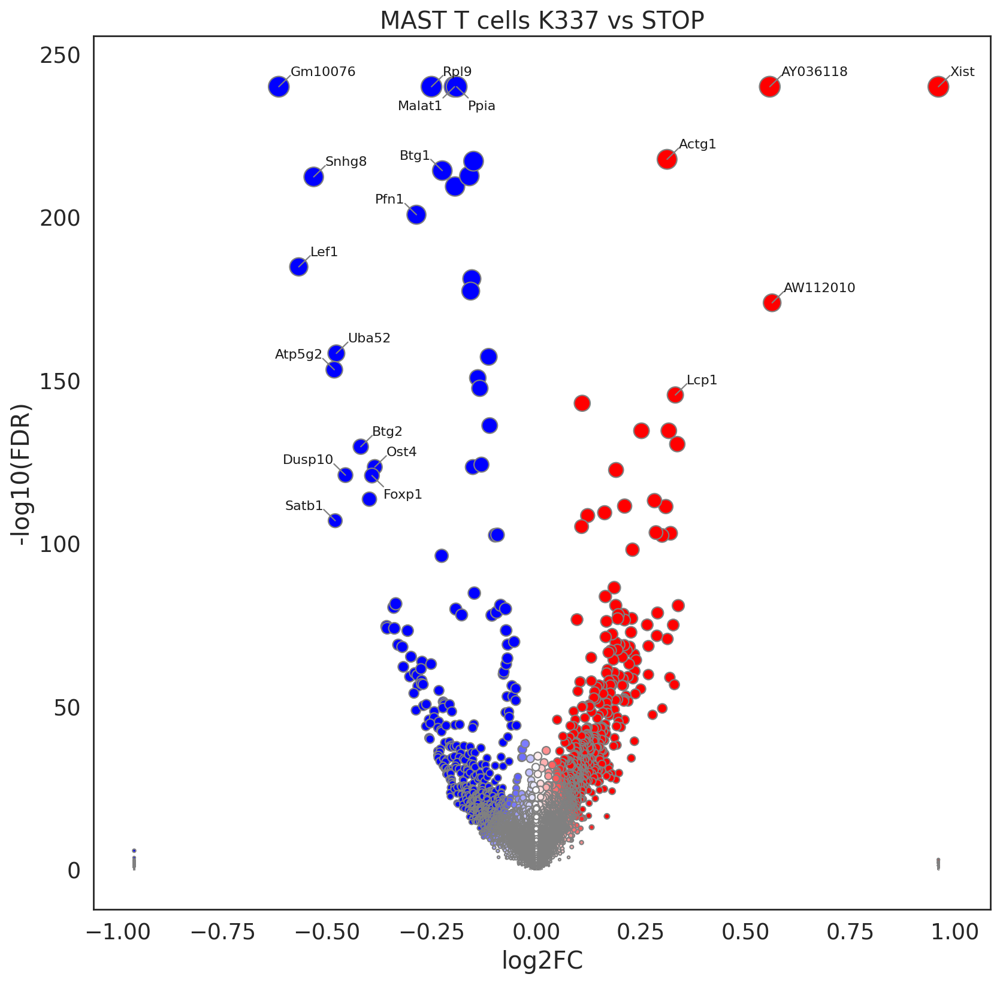

Reading data/MAST_celltype/T_cells_K337_REF/K337_vs_REF.csv


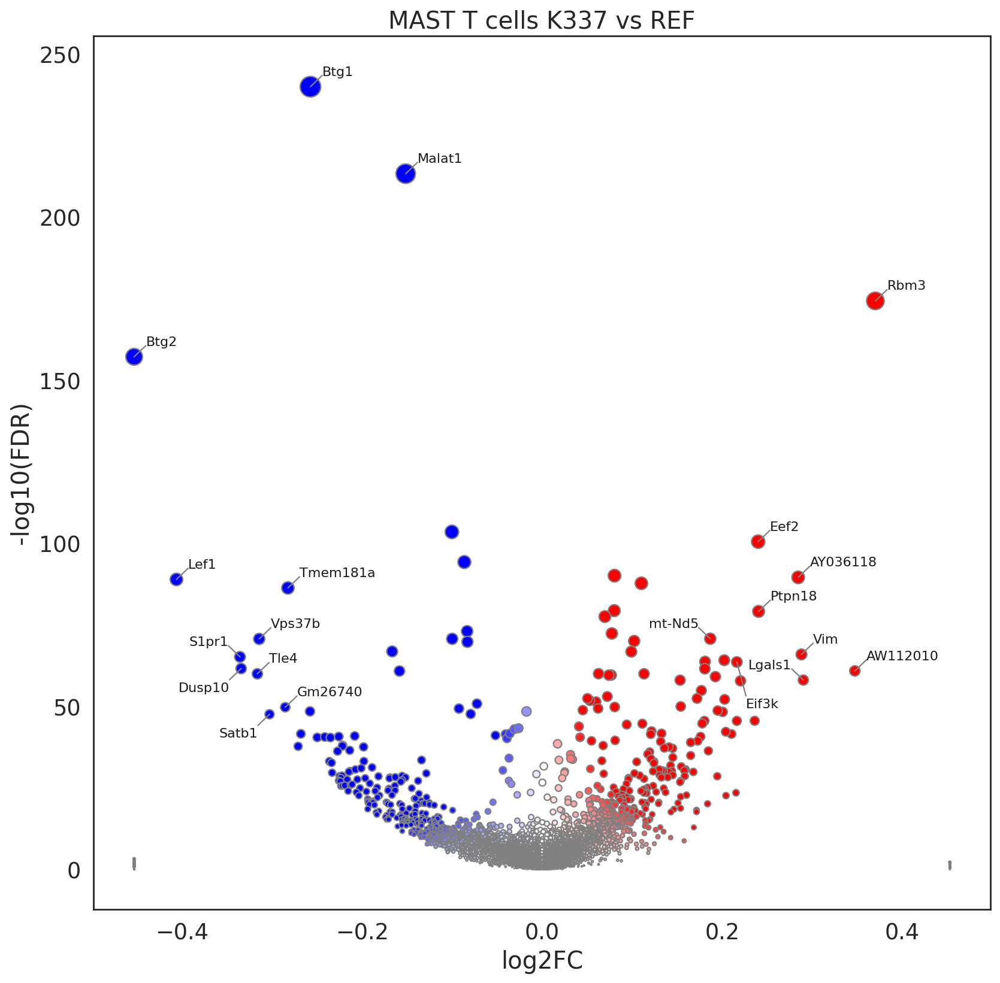

Reading data/MAST_celltype/T_cells_P13_STOP/P13_vs_STOP.csv


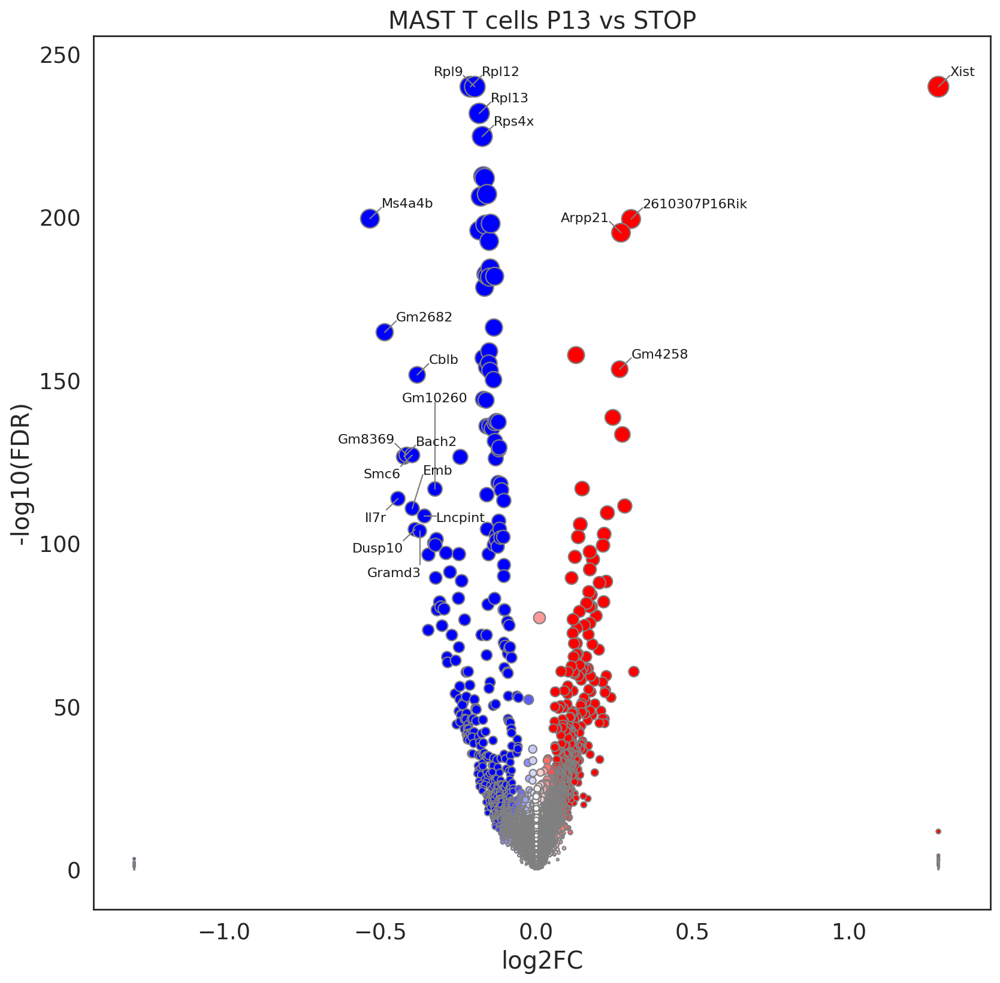

Reading data/MAST_celltype/T_cells_P13_REF/P13_vs_REF.csv


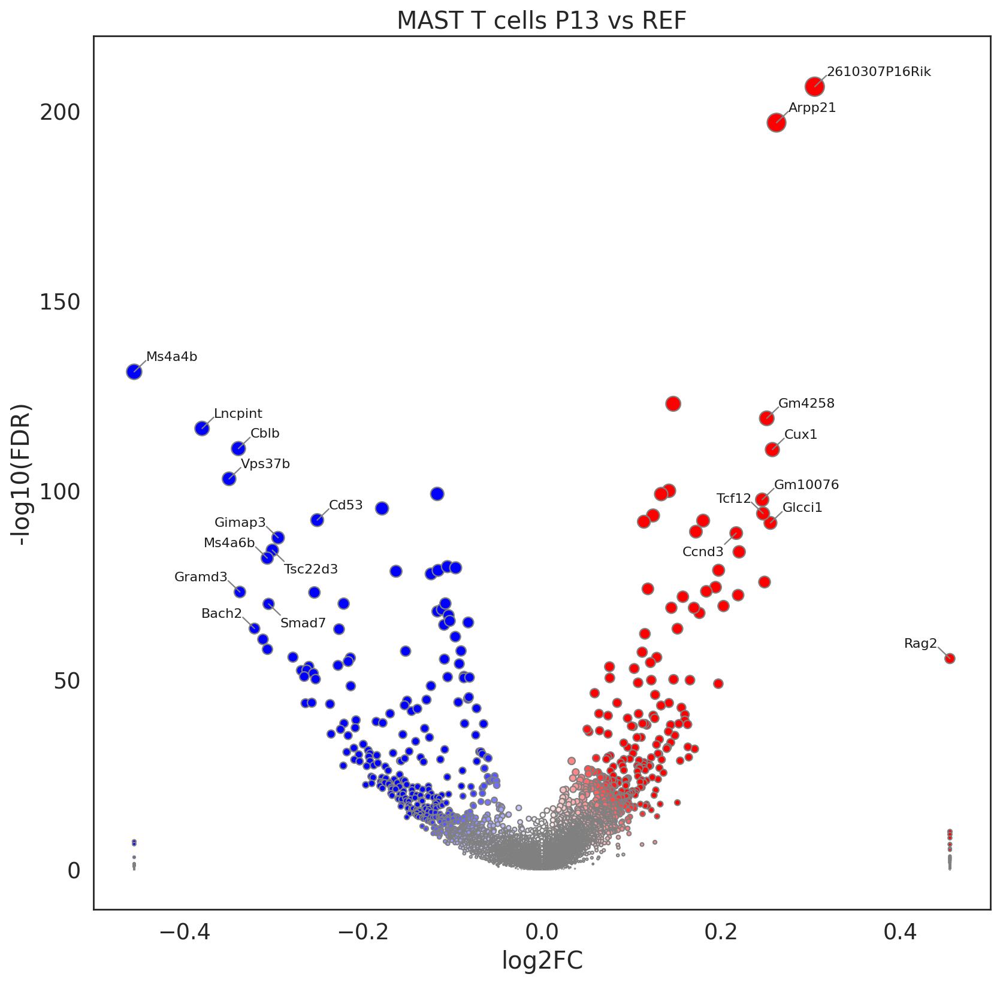

In [203]:
sns.set_style('white')
!mkdir -p MAST_celltype_plots

#for celltype in adata.obs['Macro Cell Type 4'].unique():
for celltype in ['T cells']:
      for cond1 in ['REF', 'K337', 'P13']: 
        for cond2 in ['STOP', 'REF']: 
            if cond1 == cond2: 
                continue
            #print(cond1, cond2)
            f = (adata.obs['Macro Cell Type 4'] == celltype)
            f1 = (f) & (adata.obs['condition']== cond1)
            f2 = (f) & (adata.obs['condition'] == cond2)
            if sum(f1) < 10:
                continue
            if sum(f2) < 10:
                continue
            f = f1 | f2
            
            ct0=celltype.replace(' ', '_')
            mast_infile=f'NOBACKUP/MAST_input/{ct0}_{cond1}_{cond2}_for_MAST.h5ad'
            mast_outdir=f'data/MAST_celltype/{ct0}_{cond1}_{cond2}'

            infile=f'{mast_outdir}/{cond1}_vs_{cond2}.csv'
            if not os.path.exists(infile):
                print(f'{infile} does not exist')
                continue
            df = my_read_mast_results(infile)
            if df.shape[0] == 0:
                continue
            plt.scatter(df['log2FC'], df['logfdr'], s=df['logfdr'], c=df['score'], cmap='bwr', vmin=-2, vmax=2, edgecolor='gray')
            if df.shape[0] < 20:
                top_genes = list(df.index)
            else:
                top_genes = list(df.index[:20])
            ta.allocate(plt.gca(), np.array(df.loc[top_genes,'log2FC']), np.array(df.loc[top_genes,'logfdr']),
                    np.array(top_genes), x_scatter=np.array(df['log2FC']), y_scatter=np.array(df['logfdr']), linecolor='gray')
            plt.xlabel('log2FC')
            plt.ylabel('-log10(FDR)')
            plt.title(f'MAST {celltype} {cond1} vs {cond2}')
            plt.savefig(f'MAST_celltype_plots/volcano_{ct0}_{cond1}_vs_{cond2}.png', dpi=300)
            plt.show()                                


In [204]:
gmt_file='/workdir/satseq/matt_cbsulaughney/10x/custom_gmt/custom_pathways.gmt'

In [205]:
# This code will load GSEA results stored in data directory.
# If you want to run GSEA yourself, set run_again=True, it will overwrite files
run_again=False
if not run_again:
    print('Will read pre-computed GSEA results from repository')

with open('gsea_commands4.sh', 'w') as outfile:
    for celltype in adata.obs['Macro Cell Type 4'].unique():
          for cond1 in ['REF', 'K337', 'P13']: 
            for cond2 in ['STOP', 'REF']: 
                if cond1 == cond2: 
                    continue
                #print(cond1, cond2)
                f = (adata.obs['Macro Cell Type 4'] == celltype)
                f1 = (f) & (adata.obs['condition']== cond1)
                f2 = (f) & (adata.obs['condition'] == cond2)
                if sum(f1) < 10:
                    continue
                if sum(f2) < 10:
                    continue
                f = f1 | f2
                ct0=celltype.replace(' ', '_')
                mast_outdir=f'data/MAST_celltype/{ct0}_{cond1}_{cond2}'
                infile=f'{mast_outdir}/{cond1}_vs_{cond2}.csv'
                if not os.path.exists(infile):
                    print(f'{infile} does not exist')
                    continue
                df = read_mast_results(infile)
                numna = np.sum((pd.isna(df['log2FC'])) & (df['fdr'] < 1.0))
                if numna > 0:
                    print(f'WARNING: {numna} values for leiden {l}')
                f = np.abs(df['log2FC']) < 9999
                maxval = np.max(np.abs(df.loc[f,'log2FC']))
                f = df['log2FC'] > 9999
                df.loc[f,'log2FC'] = maxval
                f = df['log2FC'] < -9999
                df.loc[f,'log2FC'] = -maxval
                df = df.loc[df['fdr'] < 1.0]
                scores = df['log2FC']*(1.0-df['fdr'])
                if len(scores) < 2:
                    continue

                gsea_dir=f'{mast_outdir}/gsea'
                !mkdir -p {gsea_dir}
                cmd=run_gsea(scores, gsea_dir, gmt_file, return_command_only=True, force=run_again)
                if cmd is not None:
                    outfile.write(cmd + '\n')

Will read pre-computed GSEA results from repository
Reading data/MAST_celltype/Endothelial_cells_REF_STOP/REF_vs_STOP.csv
Reading data/MAST_celltype/Endothelial_cells_K337_STOP/K337_vs_STOP.csv
Reading data/MAST_celltype/Endothelial_cells_K337_REF/K337_vs_REF.csv
Reading data/MAST_celltype/Endothelial_cells_P13_STOP/P13_vs_STOP.csv
Reading data/MAST_celltype/Endothelial_cells_P13_REF/P13_vs_REF.csv
Reading data/MAST_celltype/cDCs_REF_STOP/REF_vs_STOP.csv
Reading data/MAST_celltype/cDCs_K337_STOP/K337_vs_STOP.csv
Reading data/MAST_celltype/cDCs_K337_REF/K337_vs_REF.csv
Reading data/MAST_celltype/cDCs_P13_STOP/P13_vs_STOP.csv
Reading data/MAST_celltype/cDCs_P13_REF/P13_vs_REF.csv
Reading data/MAST_celltype/Neutrophil_REF_STOP/REF_vs_STOP.csv
Reading data/MAST_celltype/Neutrophil_K337_STOP/K337_vs_STOP.csv
Reading data/MAST_celltype/Neutrophil_K337_REF/K337_vs_REF.csv
Reading data/MAST_celltype/Neutrophil_P13_STOP/P13_vs_STOP.csv
Reading data/MAST_celltype/Neutrophil_P13_REF/P13_vs_REF.cs

Reading data/MAST_celltype/Endothelial_cells_K337_REF/K337_vs_REF.csv


Reading data/MAST_celltype/Endothelial_cells_P13_STOP/P13_vs_STOP.csv


Reading data/MAST_celltype/Endothelial_cells_P13_REF/P13_vs_REF.csv


Reading data/MAST_celltype/cDCs_REF_STOP/REF_vs_STOP.csv


Reading data/MAST_celltype/cDCs_K337_STOP/K337_vs_STOP.csv


... (89 outputs left out)

Reading data/MAST_celltype/Ciliated_K337_STOP/K337_vs_STOP.csv


Reading data/MAST_celltype/Ciliated_K337_REF/K337_vs_REF.csv
Reading data/MAST_celltype/Ciliated_P13_STOP/P13_vs_STOP.csv


Reading data/MAST_celltype/Ciliated_P13_REF/P13_vs_REF.csv
Reading data/MAST_celltype/Mast_cells_REF_STOP/REF_vs_STOP.csv


Reading data/MAST_celltype/Mast_cells_P13_STOP/P13_vs_STOP.csv
Reading data/MAST_celltype/Mast_cells_P13_REF/P13_vs_REF.csv


### Figure 4G

Reading positive GSEA results rom data/MAST_celltype/Endothelial_cells_REF_STOP/gsea/GSEA_run.GseaPreranked.1782955267358/gsea_report_for_na_pos_1782955267358.tsv
Reading negative GSEA results rom data/MAST_celltype/Endothelial_cells_REF_STOP/gsea/GSEA_run.GseaPreranked.1782955267358/gsea_report_for_na_neg_1782955267358.tsv
Reading positive GSEA results rom data/MAST_celltype/Endothelial_cells_P13_REF/gsea/GSEA_run.GseaPreranked.1782955441288/gsea_report_for_na_pos_1782955441288.tsv
Reading negative GSEA results rom data/MAST_celltype/Endothelial_cells_P13_REF/gsea/GSEA_run.GseaPreranked.1782955441288/gsea_report_for_na_neg_1782955441288.tsv
Reading positive GSEA results rom data/MAST_celltype/Endothelial_cells_K337_REF/gsea/GSEA_run.GseaPreranked.1782955360012/gsea_report_for_na_pos_1782955360012.tsv
Reading negative GSEA results rom data/MAST_celltype/Endothelial_cells_K337_REF/gsea/GSEA_run.GseaPreranked.1782955360012/gsea_report_for_na_neg_1782955360012.tsv


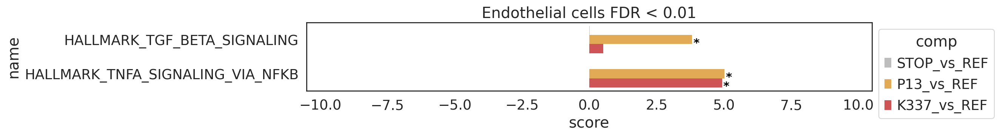

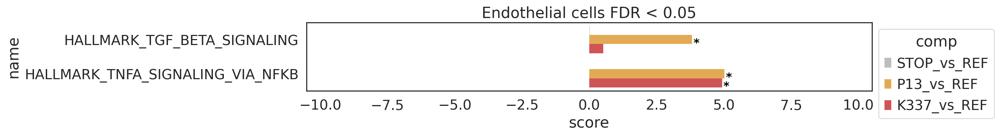

Reading positive GSEA results rom data/MAST_celltype/cDCs_REF_STOP/gsea/GSEA_run.GseaPreranked.1782955472130/gsea_report_for_na_pos_1782955472130.tsv
Reading negative GSEA results rom data/MAST_celltype/cDCs_REF_STOP/gsea/GSEA_run.GseaPreranked.1782955472130/gsea_report_for_na_neg_1782955472130.tsv
Reading positive GSEA results rom data/MAST_celltype/cDCs_P13_REF/gsea/GSEA_run.GseaPreranked.1782955530297/gsea_report_for_na_pos_1782955530297.tsv
Reading negative GSEA results rom data/MAST_celltype/cDCs_P13_REF/gsea/GSEA_run.GseaPreranked.1782955530297/gsea_report_for_na_neg_1782955530297.tsv
Reading positive GSEA results rom data/MAST_celltype/cDCs_K337_REF/gsea/GSEA_run.GseaPreranked.1782955502684/gsea_report_for_na_pos_1782955502684.tsv
Reading negative GSEA results rom data/MAST_celltype/cDCs_K337_REF/gsea/GSEA_run.GseaPreranked.1782955502684/gsea_report_for_na_neg_1782955502684.tsv


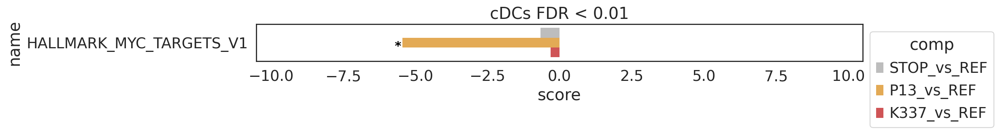

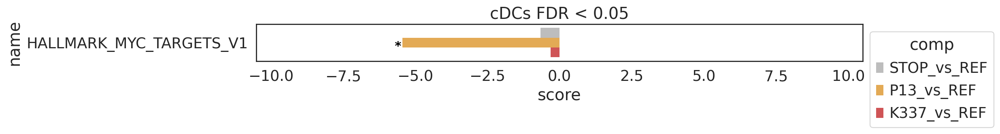

Reading positive GSEA results rom data/MAST_celltype/Neutrophil_REF_STOP/gsea/GSEA_run.GseaPreranked.1782955542597/gsea_report_for_na_pos_1782955542597.tsv
Reading negative GSEA results rom data/MAST_celltype/Neutrophil_REF_STOP/gsea/GSEA_run.GseaPreranked.1782955542597/gsea_report_for_na_neg_1782955542597.tsv
Reading positive GSEA results rom data/MAST_celltype/Neutrophil_P13_REF/gsea/GSEA_run.GseaPreranked.1782997416256/gsea_report_for_na_pos_1782997416256.tsv
Reading negative GSEA results rom data/MAST_celltype/Neutrophil_P13_REF/gsea/GSEA_run.GseaPreranked.1782997416256/gsea_report_for_na_neg_1782997416256.tsv
Reading positive GSEA results rom data/MAST_celltype/Neutrophil_K337_REF/gsea/GSEA_run.GseaPreranked.1782997416262/gsea_report_for_na_pos_1782997416262.tsv
Reading negative GSEA results rom data/MAST_celltype/Neutrophil_K337_REF/gsea/GSEA_run.GseaPreranked.1782997416262/gsea_report_for_na_neg_1782997416262.tsv


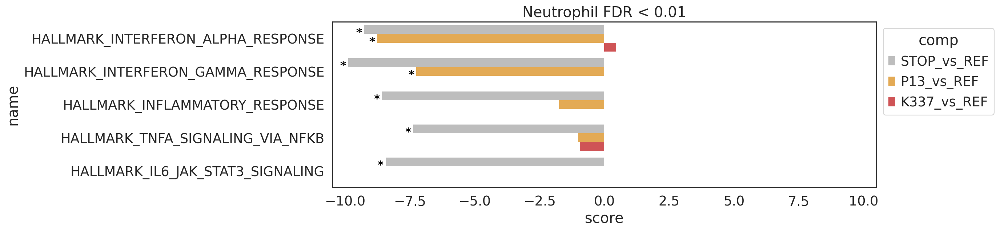

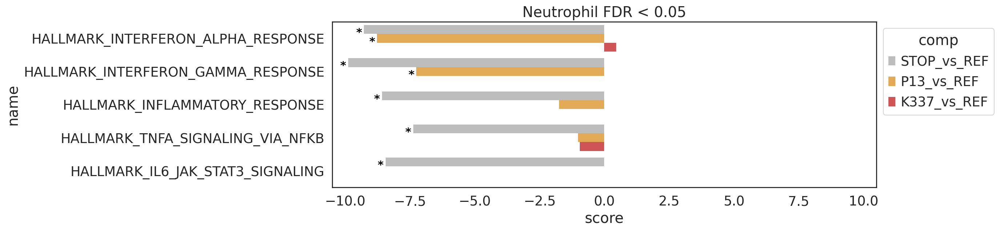

Reading positive GSEA results rom data/MAST_celltype/T_cells_REF_STOP/gsea/GSEA_run.GseaPreranked.1782950561547/gsea_report_for_na_pos_1782950561547.tsv
Reading negative GSEA results rom data/MAST_celltype/T_cells_REF_STOP/gsea/GSEA_run.GseaPreranked.1782950561547/gsea_report_for_na_neg_1782950561547.tsv
Reading positive GSEA results rom data/MAST_celltype/T_cells_P13_REF/gsea/GSEA_run.GseaPreranked.1782950782122/gsea_report_for_na_pos_1782950782122.tsv
Reading negative GSEA results rom data/MAST_celltype/T_cells_P13_REF/gsea/GSEA_run.GseaPreranked.1782950782122/gsea_report_for_na_neg_1782950782122.tsv
Reading positive GSEA results rom data/MAST_celltype/T_cells_K337_REF/gsea/GSEA_run.GseaPreranked.1782950668658/gsea_report_for_na_pos_1782950668658.tsv
Reading negative GSEA results rom data/MAST_celltype/T_cells_K337_REF/gsea/GSEA_run.GseaPreranked.1782950668658/gsea_report_for_na_neg_1782950668658.tsv


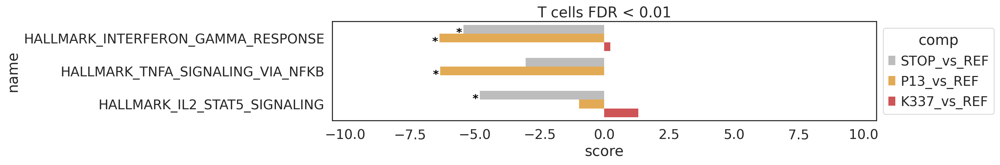

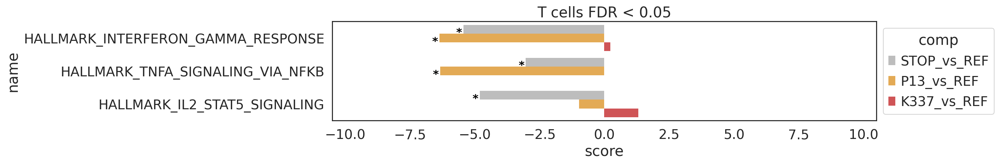

Reading positive GSEA results rom data/MAST_celltype/IM_REF_STOP/gsea/GSEA_run.GseaPreranked.1782997416252/gsea_report_for_na_pos_1782997416252.tsv
Reading negative GSEA results rom data/MAST_celltype/IM_REF_STOP/gsea/GSEA_run.GseaPreranked.1782997416252/gsea_report_for_na_neg_1782997416252.tsv
Reading positive GSEA results rom data/MAST_celltype/IM_P13_REF/gsea/GSEA_run.GseaPreranked.1782997460791/gsea_report_for_na_pos_1782997460791.tsv
Reading negative GSEA results rom data/MAST_celltype/IM_P13_REF/gsea/GSEA_run.GseaPreranked.1782997460791/gsea_report_for_na_neg_1782997460791.tsv
Reading positive GSEA results rom data/MAST_celltype/IM_K337_REF/gsea/GSEA_run.GseaPreranked.1782997448413/gsea_report_for_na_pos_1782997448413.tsv
Reading negative GSEA results rom data/MAST_celltype/IM_K337_REF/gsea/GSEA_run.GseaPreranked.1782997448413/gsea_report_for_na_neg_1782997448413.tsv


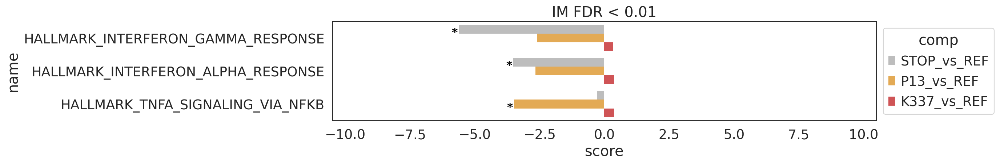

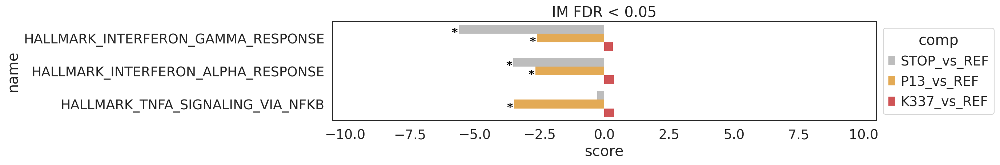

Reading positive GSEA results rom data/MAST_celltype/4T1_REF_STOP/gsea/GSEA_run.GseaPreranked.1782997462115/gsea_report_for_na_pos_1782997462115.tsv
Reading negative GSEA results rom data/MAST_celltype/4T1_REF_STOP/gsea/GSEA_run.GseaPreranked.1782997462115/gsea_report_for_na_neg_1782997462115.tsv
Reading positive GSEA results rom data/MAST_celltype/4T1_P13_REF/gsea/GSEA_run.GseaPreranked.1782997496633/gsea_report_for_na_pos_1782997496633.tsv
Reading negative GSEA results rom data/MAST_celltype/4T1_P13_REF/gsea/GSEA_run.GseaPreranked.1782997496633/gsea_report_for_na_neg_1782997496633.tsv
Reading positive GSEA results rom data/MAST_celltype/4T1_K337_REF/gsea/GSEA_run.GseaPreranked.1782997471721/gsea_report_for_na_pos_1782997471721.tsv
Reading negative GSEA results rom data/MAST_celltype/4T1_K337_REF/gsea/GSEA_run.GseaPreranked.1782997471721/gsea_report_for_na_neg_1782997471721.tsv


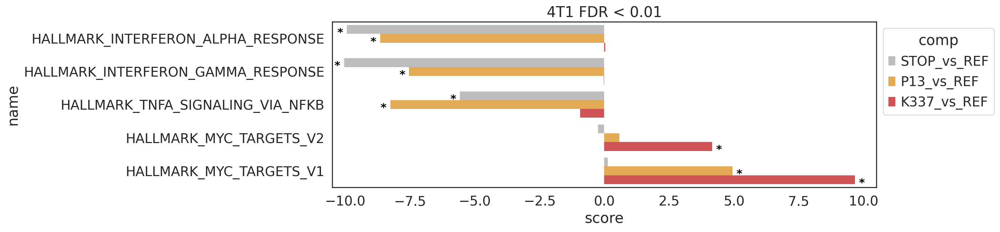

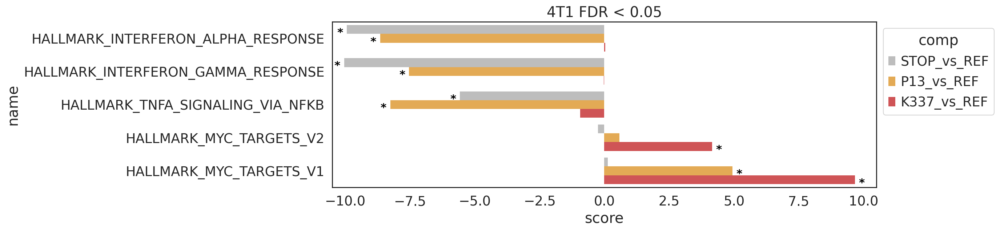

Reading positive GSEA results rom data/MAST_celltype/Fibroblasts_REF_STOP/gsea/GSEA_run.GseaPreranked.1782997524608/gsea_report_for_na_pos_1782997524608.tsv
Reading negative GSEA results rom data/MAST_celltype/Fibroblasts_REF_STOP/gsea/GSEA_run.GseaPreranked.1782997524608/gsea_report_for_na_neg_1782997524608.tsv
Reading positive GSEA results rom data/MAST_celltype/Fibroblasts_P13_REF/gsea/GSEA_run.GseaPreranked.1782997551100/gsea_report_for_na_pos_1782997551100.tsv
Reading negative GSEA results rom data/MAST_celltype/Fibroblasts_P13_REF/gsea/GSEA_run.GseaPreranked.1782997551100/gsea_report_for_na_neg_1782997551100.tsv
Reading positive GSEA results rom data/MAST_celltype/Fibroblasts_K337_REF/gsea/GSEA_run.GseaPreranked.1782997541553/gsea_report_for_na_pos_1782997541553.tsv
Reading negative GSEA results rom data/MAST_celltype/Fibroblasts_K337_REF/gsea/GSEA_run.GseaPreranked.1782997541553/gsea_report_for_na_neg_1782997541553.tsv


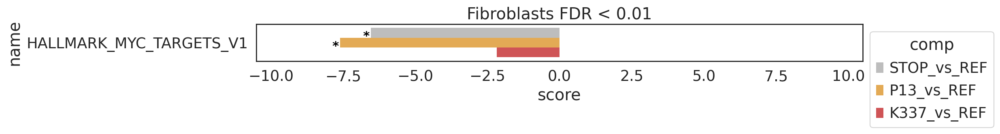

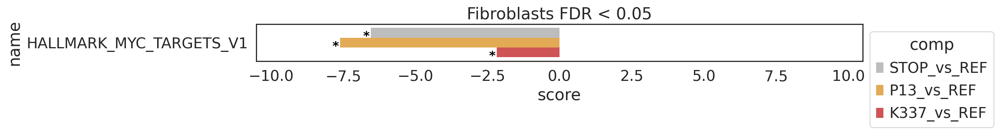

Reading positive GSEA results rom data/MAST_celltype/B_cells_REF_STOP/gsea/GSEA_run.GseaPreranked.1782997552996/gsea_report_for_na_pos_1782997552996.tsv
Reading negative GSEA results rom data/MAST_celltype/B_cells_REF_STOP/gsea/GSEA_run.GseaPreranked.1782997552996/gsea_report_for_na_neg_1782997552996.tsv
Reading positive GSEA results rom data/MAST_celltype/B_cells_P13_REF/gsea/GSEA_run.GseaPreranked.1782997563500/gsea_report_for_na_pos_1782997563500.tsv
Reading negative GSEA results rom data/MAST_celltype/B_cells_P13_REF/gsea/GSEA_run.GseaPreranked.1782997563500/gsea_report_for_na_neg_1782997563500.tsv
Reading positive GSEA results rom data/MAST_celltype/B_cells_K337_REF/gsea/GSEA_run.GseaPreranked.1782997554349/gsea_report_for_na_pos_1782997554349.tsv
Reading negative GSEA results rom data/MAST_celltype/B_cells_K337_REF/gsea/GSEA_run.GseaPreranked.1782997554349/gsea_report_for_na_neg_1782997554349.tsv
Reading positive GSEA results rom data/MAST_celltype/AM_REF_STOP/gsea/GSEA_run.GseaP

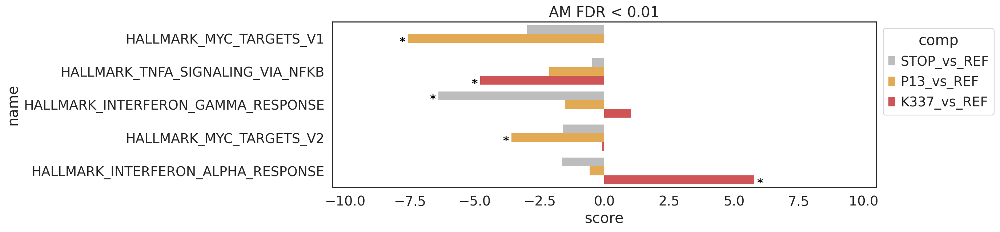

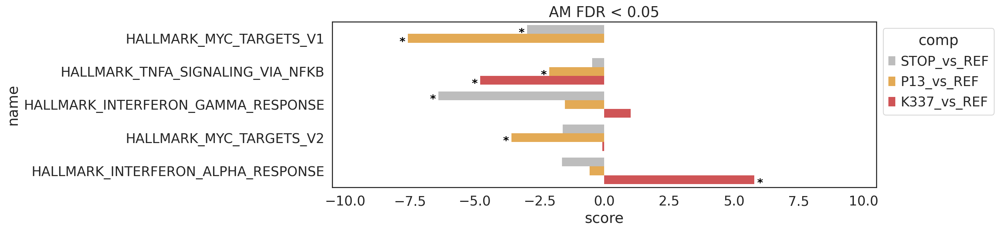

Reading positive GSEA results rom data/MAST_celltype/NK_cells_REF_STOP/gsea/GSEA_run.GseaPreranked.1782997607356/gsea_report_for_na_pos_1782997607356.tsv
Reading negative GSEA results rom data/MAST_celltype/NK_cells_REF_STOP/gsea/GSEA_run.GseaPreranked.1782997607356/gsea_report_for_na_neg_1782997607356.tsv
Reading positive GSEA results rom data/MAST_celltype/NK_cells_P13_REF/gsea/GSEA_run.GseaPreranked.1782997615671/gsea_report_for_na_pos_1782997615671.tsv
Reading negative GSEA results rom data/MAST_celltype/NK_cells_P13_REF/gsea/GSEA_run.GseaPreranked.1782997615671/gsea_report_for_na_neg_1782997615671.tsv
Reading positive GSEA results rom data/MAST_celltype/NK_cells_K337_REF/gsea/GSEA_run.GseaPreranked.1782997612953/gsea_report_for_na_pos_1782997612953.tsv
Reading negative GSEA results rom data/MAST_celltype/NK_cells_K337_REF/gsea/GSEA_run.GseaPreranked.1782997612953/gsea_report_for_na_neg_1782997612953.tsv


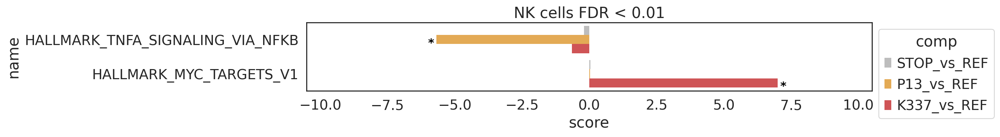

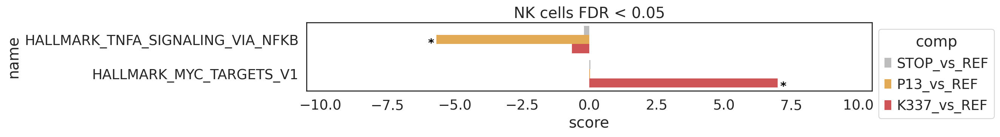

Reading positive GSEA results rom data/MAST_celltype/iMON_REF_STOP/gsea/GSEA_run.GseaPreranked.1782997618187/gsea_report_for_na_pos_1782997618187.tsv
Reading negative GSEA results rom data/MAST_celltype/iMON_REF_STOP/gsea/GSEA_run.GseaPreranked.1782997618187/gsea_report_for_na_neg_1782997618187.tsv
Reading positive GSEA results rom data/MAST_celltype/iMON_P13_REF/gsea/GSEA_run.GseaPreranked.1782997631901/gsea_report_for_na_pos_1782997631901.tsv
Reading negative GSEA results rom data/MAST_celltype/iMON_P13_REF/gsea/GSEA_run.GseaPreranked.1782997631901/gsea_report_for_na_neg_1782997631901.tsv
Reading positive GSEA results rom data/MAST_celltype/iMON_K337_REF/gsea/GSEA_run.GseaPreranked.1782997628110/gsea_report_for_na_pos_1782997628110.tsv
Reading negative GSEA results rom data/MAST_celltype/iMON_K337_REF/gsea/GSEA_run.GseaPreranked.1782997628110/gsea_report_for_na_neg_1782997628110.tsv


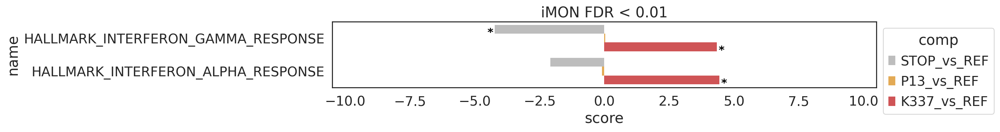

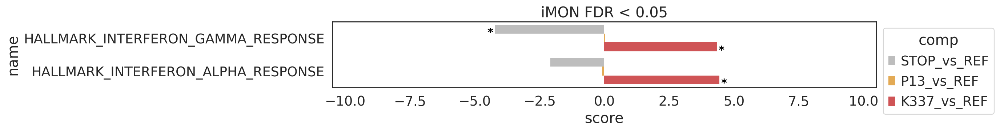

Reading positive GSEA results rom data/MAST_celltype/AT2_REF_STOP/gsea/GSEA_run.GseaPreranked.1782997632566/gsea_report_for_na_pos_1782997632566.tsv
Reading negative GSEA results rom data/MAST_celltype/AT2_REF_STOP/gsea/GSEA_run.GseaPreranked.1782997632566/gsea_report_for_na_neg_1782997632566.tsv
Reading positive GSEA results rom data/MAST_celltype/AT2_P13_REF/gsea/GSEA_run.GseaPreranked.1782997647153/gsea_report_for_na_pos_1782997647153.tsv
Reading negative GSEA results rom data/MAST_celltype/AT2_P13_REF/gsea/GSEA_run.GseaPreranked.1782997647153/gsea_report_for_na_neg_1782997647153.tsv
Reading positive GSEA results rom data/MAST_celltype/AT2_K337_REF/gsea/GSEA_run.GseaPreranked.1782997640525/gsea_report_for_na_pos_1782997640525.tsv
Reading negative GSEA results rom data/MAST_celltype/AT2_K337_REF/gsea/GSEA_run.GseaPreranked.1782997640525/gsea_report_for_na_neg_1782997640525.tsv
Reading positive GSEA results rom data/MAST_celltype/Basophil_REF_STOP/gsea/GSEA_run.GseaPreranked.178299764

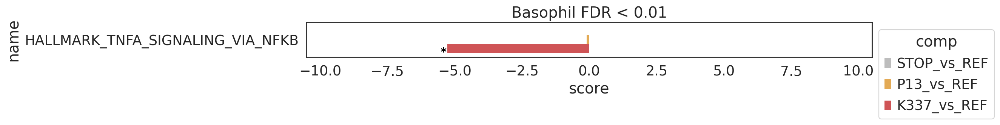

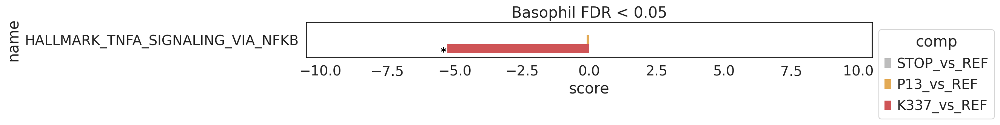

Reading positive GSEA results rom data/MAST_celltype/pDCs_REF_STOP/gsea/GSEA_run.GseaPreranked.1782997656505/gsea_report_for_na_pos_1782997656505.tsv
Reading negative GSEA results rom data/MAST_celltype/pDCs_REF_STOP/gsea/GSEA_run.GseaPreranked.1782997656505/gsea_report_for_na_neg_1782997656505.tsv
Reading positive GSEA results rom data/MAST_celltype/pDCs_P13_REF/gsea/GSEA_run.GseaPreranked.1782997657390/gsea_report_for_na_pos_1782997657390.tsv
Reading negative GSEA results rom data/MAST_celltype/pDCs_P13_REF/gsea/GSEA_run.GseaPreranked.1782997657390/gsea_report_for_na_neg_1782997657390.tsv
Reading positive GSEA results rom data/MAST_celltype/pDCs_K337_REF/gsea/GSEA_run.GseaPreranked.1782997656854/gsea_report_for_na_pos_1782997656854.tsv
Reading negative GSEA results rom data/MAST_celltype/pDCs_K337_REF/gsea/GSEA_run.GseaPreranked.1782997656854/gsea_report_for_na_neg_1782997656854.tsv


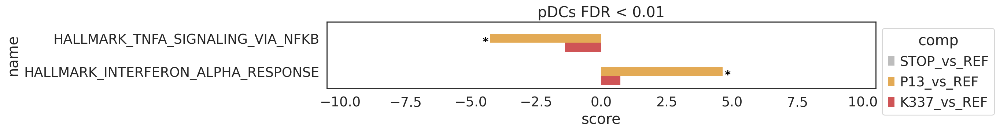

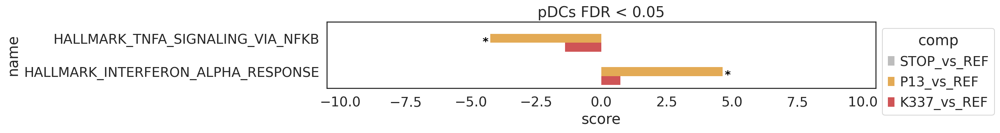

No results for Smooth Muscle K337
No results for Smooth Muscle K337
No results for Smooth Muscle K337
Smooth Muscle len(grs)=0
Reading positive GSEA results rom data/MAST_celltype/Pericytes_REF_STOP/gsea/GSEA_run.GseaPreranked.1782997663993/gsea_report_for_na_pos_1782997663993.tsv
Reading negative GSEA results rom data/MAST_celltype/Pericytes_REF_STOP/gsea/GSEA_run.GseaPreranked.1782997663993/gsea_report_for_na_neg_1782997663993.tsv
Reading positive GSEA results rom data/MAST_celltype/Pericytes_P13_REF/gsea/GSEA_run.GseaPreranked.1782997667404/gsea_report_for_na_pos_1782997667404.tsv
Reading negative GSEA results rom data/MAST_celltype/Pericytes_P13_REF/gsea/GSEA_run.GseaPreranked.1782997667404/gsea_report_for_na_neg_1782997667404.tsv
Reading positive GSEA results rom data/MAST_celltype/Pericytes_K337_REF/gsea/GSEA_run.GseaPreranked.1782997664233/gsea_report_for_na_pos_1782997664233.tsv
Reading negative GSEA results rom data/MAST_celltype/Pericytes_K337_REF/gsea/GSEA_run.GseaPreranked.

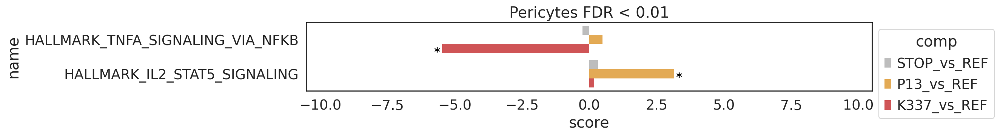

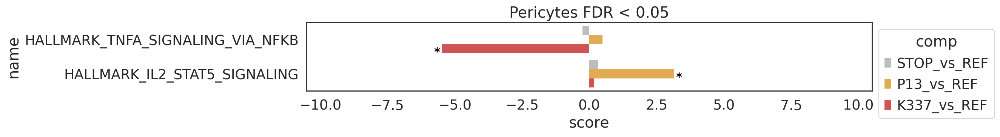

No results for Mesothelial K337
No results for Mesothelial K337
No results for Mesothelial K337
Mesothelial len(grs)=0
Reading positive GSEA results rom data/MAST_celltype/ILC_REF_STOP/gsea/GSEA_run.GseaPreranked.1782997668000/gsea_report_for_na_pos_1782997668000.tsv
Reading negative GSEA results rom data/MAST_celltype/ILC_REF_STOP/gsea/GSEA_run.GseaPreranked.1782997668000/gsea_report_for_na_neg_1782997668000.tsv
Reading positive GSEA results rom data/MAST_celltype/ILC_P13_REF/gsea/GSEA_run.GseaPreranked.1782997672065/gsea_report_for_na_pos_1782997672065.tsv
Reading negative GSEA results rom data/MAST_celltype/ILC_P13_REF/gsea/GSEA_run.GseaPreranked.1782997672065/gsea_report_for_na_neg_1782997672065.tsv
Reading positive GSEA results rom data/MAST_celltype/ILC_K337_REF/gsea/GSEA_run.GseaPreranked.1782997669826/gsea_report_for_na_pos_1782997669826.tsv
Reading negative GSEA results rom data/MAST_celltype/ILC_K337_REF/gsea/GSEA_run.GseaPreranked.1782997669826/gsea_report_for_na_neg_1782997

/tmp/ipykernel_58269/4266809872.py:180: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  rv = pd.concat([pos, neg])


In [206]:
sns.set_style('white')
ref='REF'

if ref == 'STOP':
    hue_order = ['REF_vs_STOP', 'P13_vs_STOP', 'K337_vs_STOP']#, 
else:
    hue_order=['STOP_vs_REF', 'P13_vs_REF', 'K337_vs_REF']
#for celltype in df['celltype'].unique():
for celltype in adata.obs['Macro Cell Type 4'].unique():
    ct0=celltype.replace(' ', '_')
    grs=[]
    for comp in hue_order:
        if comp == 'STOP_vs_REF':
            mast_outdir=f'data/MAST_celltype/{ct0}_REF_vs_STOP'.replace('_vs', '')
        else:
            mast_outdir=f'data/MAST_celltype/{ct0}_{comp}'.replace('_vs', '')
        gsea_dir=f'{mast_outdir}/gsea'
        gr = run_gsea(None, gsea_dir, None, readonly=True)
        if gr is None:
            print(f'No results for {celltype} {var}')
            continue
        if comp == 'STOP_vs_REF':
            gr['nes'] = gr['nes']*-1.0
        gr['comp'] = comp
        gr = gr.loc[gr['name'].str.startswith('HALLMARK')]
        grs.append(gr)
    if len(grs) != len(hue_order):
        print(f'{celltype} len(grs)={len(grs)}')
        continue

    gr =pd.concat(grs)

    #for cutoff in [0.25, 0.10, 0.05]:
    for cutoff in [0.01, 0.05]:
        
        f = gr['fdr_q'] != 0
        minval = gr.loc[f,'fdr_q'].min()
        gr = gr.copy()
        gr.loc[~f,'fdr_q'] = minval*0.5
        
        gr['score'] = -np.log10(gr['fdr_q'])*gr['nes']
        
        minfdr = gr.groupby('name')['fdr_q'].min()
        keepnames = list(minfdr[minfdr < cutoff].index)
        gr = gr.loc[gr['name'].isin(keepnames)]

        if gr.shape[0] == 0:
            continue
        tmpsum = gr.groupby('name')['score'].sum().sort_values()
        
        pltsize = len(tmpsum)
        plt.subplots(figsize=(12, pltsize/4*len(hue_order)))
        
        name_order = list(tmpsum.index)
        
        ax = sns.barplot(
            data=gr,
            x='score',
            y='name',
            hue='comp',
            hue_order=hue_order,
            palette={'REF_vs_STOP':'#bdbdbd',
                     'K337_vs_STOP':'#ff1d24', 
                     'P13_vs_STOP': '#ff5211',
                    'K337_vs_REF':'#e43f42',
                    'P13_vs_REF':'#fbaf3d',
                    'STOP_vs_REF':'#bdbdbd'},
            order=name_order,  edgecolor='none'
        )
        
        bar_info = []
        for h in hue_order:
            for name in name_order:
                row = gr[(gr['name'] == name) & (gr['comp'] == h)]
                bar_info.append(None if row.empty else row.iloc[0])

        # Add stars to significant bars instead of fading nonsignificant bars
        xvals = gr['score'].dropna()
        xpad = 0.0075 * (xvals.max() - xvals.min())

        if xpad == 0:
            xpad = 0.01

        for patch, row in zip(ax.patches, bar_info):
            if row is None:
                continue

            # Keep all bars fully opaque
            patch.set_alpha(1.0)

            # Add star only for significant comparisons
            if row['fdr_q'] < cutoff:
                width = patch.get_width()
                y = patch.get_y() + patch.get_height() / 2 + 0.1

                if width >= 0:
                    x = width + xpad
                    ha = 'left'
                else:
                    x = width - xpad
                    ha = 'right'

                ax.text(
                    x,
                    y,
                    '*',
                    va='center',
                    ha=ha,
                    fontsize=14,
                    fontweight='bold',
                    color='black'
                )
        plt.title(f'{celltype} FDR < {cutoff:0.2f}')
        sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
        ax.set_xlim(-10.5, 10.5)
        ct0=celltype.replace(' ', '_')
        plt.savefig(f'MAST_celltype_plots/pathways_vs_{ref}_{ct0}_{cutoff:0.2f}.png', bbox_inches='tight', dpi=300)
        plt.savefig(f'MAST_celltype_plots/pathways_vs_{ref}_{ct0}_{cutoff:0.2f}.svg', bbox_inches='tight')
        plt.show()